# Bounce optical state from A–B–A: all DZ, v-modes and DOF vs elevation (v3)

**Author:** Aaron Roodman (with Claude)  
**Date Created:** 2026-10-29  
**Last Modified:** 2026-11-04  
**Status:** In Progress  
**Keywords:** bounce, A–B–A, DZ, v-modes, DOF, RBR, red noise, BLOCK-T720  

## Description

The BLOCK-T720 elevation sweep (reference 70 deg), with every quantity from one
analysis:

1. The A–B–A Δ of all 126 DZ_kj terms (k = 1–6, the 21 pupil j) for each
   (night, leg): the median over B visits of B minus the A interpolated to its
   time from its neighbours.
2. The 50 DOF from Range-Bounded Recovery (RBR) 50/50 of that ΔDZ vector, with the
   bounce run's knobs.
3. Those DOF in the 50-DOF, 50-mode v-modes of `rubinwork.aos_state` (first 34 shown).

Errors come from one Monte Carlo of the full DZ vector, with this noise model:

- White noise for all 126 terms, covariance `Σ_W` (126 × 126). Its diagonal is the
  per-visit RMS from the B−A pairs (`bounce_white_noise_pairs_v1`), the conservative
  choice. The correlations come from the same pairs, shrunk toward zero
  (Ledoit–Wolf), since 45 pairs cannot fix a 126-term covariance alone.
- Red noise for DZ(1,4) only: `D(tau) = 2 sigma_W^2 + sigma_R^2 (tau / T0)^ALPHA`,
  with sigma_W fixed at the pair RMS and sigma_R, ALPHA fit to the same-setting
  variogram.

Each MC draw of the visits' DZ vectors goes through A–B–A, then RBR, then the
v-mode map, so the errors carry the covariance between DZ terms and the
nonlinearity of RBR.

v2 replaced the v1 model (shared ALPHA for all terms), which drove the DZ(1,4)
white floor to about zero.

v3 adds the DZ left after the correction: `ΔDZ − S · ΔDOF`, with S the 126 × 50
sensitivity (`estimator.forward_operator()`) and ΔDOF the RBR 50/50 solution.
It also splits the fitted DZ(1,4) into the parts from each DOF and each v-mode.
That shows how M2_dz, Cam_dz, B1_3 and B2_5 can each scatter while their sum,
and v1, follow the DZ(1,4) pattern.

**Output:** `bounce_aba_optical_state.pdf` (DZ, v-mode and DOF pages) and CSVs in
the study run directory.

**Based on:** `bounce_aba_optical_state_v1`, `bounce_white_noise_pairs_v1`; `aos/bounce/study.md`, Log 2026-10-29 (DZ(1,4) and v1 put 40 deg
out of family; the error model of `bounce_delta_derivation_v3`/`v4`).

## Change Log

| Date | Author | Description |
|------|--------|-------------|
| 2026-10-29 | Aaron Roodman | Initial version (v1) |
| 2026-11-02 | Aaron Roodman | v2: white noise from B−A pair RMS for all terms, red noise for DZ(1,4) only |
| 2026-11-04 | Aaron Roodman | v3: DZ residuals after the RBR correction; DZ(1,4) split by DOF and v-mode |

## Table of Contents

1. [Parameters](#params)
2. [Setup & Imports](#setup)
3. [Data Access](#data)
4. [Visits and legs](#visits)
5. [Noise model](#model)
6. [A–B–A Δ, RBR and Monte Carlo errors](#mc)
7. [Why the DOF do not show the v1 pattern](#dofsplit)
8. [Plots: DZ, v-modes, DOF vs elevation](#plots)
9. [DZ after the RBR correction](#resid)
10. [Save](#save)

<a id='params'></a>
## Parameters

In [1]:
DAY_OBS = [20260418, 20260419, 20260513, 20260709, 20260711, 20260713]
BOUNCE = 'T720_elevation'          # bounce name from analysis_config.yaml

PARAM_SET = 'danish_1_3'
MI_NAME = 'pathA_50_50_i_rbr_5rot'
MIW_VARIANT = 'd13-A_50_50_i_rbr_5rot'
MIW_BUILD = '20261028b'
MIN_DETECTORS = 160                # the bounce run's --min-detectors

T0_MIN = 10.0                      # red-noise reference lag, min
LAG_BINS = [0, 4, 8, 15, 30, 60, 120]   # same-setting variogram bins, min
V1_RUN = '20261029_aba_optical_state'   # v1 run, for the error comparison
N_MC = 1000                        # MC realisations per (night, leg)
N_VMODES_SHOW = 34
J_PER_PAGE = 4                     # DZ pages: k = 1..6 across, this many j down
VMODES_PER_PAGE = 12
DOF_PER_PAGE = 10
SEED = 20261102
SAVE = True

from rubinwork.common import study_run
run = study_run('aos/bounce', 'aba_dz_residual')

<a id='setup'></a>
## Setup & Imports

In [2]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages
from scipy.optimize import least_squares
from sklearn.covariance import ledoit_wolf

from rubinwork import aos_state
from rubinwork.bounce import legs as bl
from rubinwork.bounce import analysis as ba
from rubinwork.common.utils import repo_root
from rubinwork.products import catalog
from lsst.ts.intrinsic.wavefront.ofc_svd import (build_ofc_svd, project_dz_table,
                                                 LABELS_50DOF, DOF_UNITS_50)

pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 30)

<a id='data'></a>
## Data Access

The fit table goes through the same bad-fit drop and quality cut as the bounce run.

In [3]:
cfg = bl.resolve_config(PARAM_SET, MI_NAME,
                        analysis_config=repo_root() / 'aos' / 'analysis_config.yaml')
prefix = cfg['fit_prefix']
b = next(x for x in cfg['bounces'] if x['name'] == BOUNCE)
ft = ba.load_fit_table(catalog.path('miw', MIW_VARIANT, build=MIW_BUILD) / 'fits.parquet',
                       cfg, min_detectors=MIN_DETECTORS)
iZs = list(cfg['pupil_j_range']); kr = cfg['focal_k_range']
svd = build_ofc_svd(iZs, int(min(kr)), int(max(kr)), int(cfg['rbr_n_keep']), n_dof=cfg['n_dof'],
                    ofc_normalization_yaml=cfg['ofc_normalization_yaml'])
_, _, _, W = project_dz_table(ft, prefix, svd)      # (visit, kj) um of wavefront
KJ = list(svd.kj_grid); NT = len(KJ)
se50 = aos_state.make_state_estimator(dof_set='all_50', n_modes=50)
# DOF -> v-mode is linear, so one (DOF, v-mode) matrix does every draw
T_V = aos_state.vmodes_from_dofs(np.eye(50), se50, n_modes=50)

def rbr(w):
    return svd.estimator.dof_range_bounded(
        w, kappa=float(cfg['rbr_kappa']), power=int(cfg['rbr_power']),
        penalty_weight=float(cfg['rbr_penalty_weight']), full_dof=bool(cfg['rbr_full_dof']))

print(f'{len(ft)} visits, {NT} DZ terms (k = {min(kr)}..{max(kr)}, j = {iZs}); RBR kappa = '
      f'{cfg["rbr_kappa"]}, power = {cfg["rbr_power"]}, penalty_weight = {cfg["rbr_penalty_weight"]}, '
      f'full_dof = {cfg["rbr_full_dof"]}')

  dropping 11 bad-flagged visits (z1toz6_bad_fit)


        Use pytest instead. [astropy.tests.runner]
        Use pytest instead.


        Use pytest instead. [astropy.utils.decorators]
        Use pytest instead.


INFO:lsst.ts.utils.tai:Update leap second table


INFO:lsst.ts.utils.tai:current_tai uses the system TAI clock


  quality cut (min_detectors=160): 1575/2012 visits kept


1575 visits, 126 DZ terms (k = 1..6, j = [4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 22, 23, 24, 25, 26]); RBR kappa = 4.0, power = 3, penalty_weight = 1.0, full_dof = True


<a id='visits'></a>
## Visits and legs

`run_bounce(..., day_obs=night)` gives the A mask and each B leg's mask, as in the
bounce run. A–B–A uses every A and B visit of the leg in time order.

In [4]:
dobs = np.asarray(ft['day_obs']).astype(int)
seq = np.asarray(ft['seq_num']).astype(int)
mjd = np.asarray(ft['mjd'], float)
prog = bl.bounce_program_mask(ft, b)
visits, pair_rows, legs = [], [], []
for d in DAY_OBS:
    rb = bl.run_bounce(ft, b, prefix, [1], [4], day_obs=d)
    night = (dobs == d) & prog
    if not night.any():
        continue
    t0 = mjd[night].min()
    for lab, cb in rb['comparisons'].items():
        if not cb['pairs']:
            continue
        legs.append({'night': d, 'leg': lab, 'b_value_deg': bl.leg_b_value(lab)})
        for i in np.nonzero(night)[0]:
            s = 'A' if rb['ref_mask'][i] else 'B' if cb['comp_mask'][i] else 'other'
            visits.append({'night': d, 'leg': lab, 'row': i, 'seq_num': seq[i],
                           't_min': (mjd[i] - t0) * 1440.0, 'setting': s})
        for r, c in cb['pairs']:
            pair_rows.append({'night': d, 'leg': lab, 'row_A': r, 'row_B': c,
                              'lag_min': (mjd[c] - mjd[r]) * 1440.0})
vdf = pd.DataFrame(visits)
pdf_pairs = pd.DataFrame(pair_rows)


def leg_visits(d, lab):
    v = vdf[(vdf.night == d) & (vdf.leg == lab) & vdf.setting.isin(['A', 'B'])]
    return v.drop_duplicates('seq_num').sort_values('seq_num')


def aba_matrix(v):
    # rows: each A–B–A difference as weights on the visits of v
    s = v.setting.to_numpy(); t = v.t_min.to_numpy(); A = np.nonzero(s == 'A')[0]
    rows = []
    for i in np.nonzero(s == 'B')[0]:
        a0 = A[A < i]; a1 = A[A > i]
        if len(a0) and len(a1):
            a0, a1 = a0[-1], a1[0]; f = (t[i] - t[a0]) / (t[a1] - t[a0])
            w = np.zeros(len(s)); w[i] = 1; w[a0] -= 1 - f; w[a1] -= f
            rows.append(w)
    return np.array(rows)


legs_df = pd.DataFrame(legs)
legs_df['n_A'] = [(leg_visits(r.night, r.leg).setting == 'A').sum() for r in legs_df.itertuples()]
legs_df['n_B'] = [(leg_visits(r.night, r.leg).setting == 'B').sum() for r in legs_df.itertuples()]
legs_df['n_aba'] = [len(aba_matrix(leg_visits(r.night, r.leg))) for r in legs_df.itertuples()]
legs_df

,night,leg,b_value_deg,n_A,n_B,n_aba
0,20260418,Elev=40,40.0,6,6,5
1,20260419,Elev=40,40.0,12,10,9
2,20260513,Elev=40,40.0,8,8,7
3,20260709,Elev=60,60.0,6,4,3
4,20260711,Elev=50,50.0,6,6,5
5,20260713,Elev=30,30.0,12,5,5
6,20260713,Elev=75,75.0,12,6,6


<a id='model'></a>
## Noise model

**White, all terms.** The B−A pairs of each (night, leg), about 2.8 min apart, with
the (night, leg) median subtracted. The per-visit sigma of each term is the RMS
`sqrt(sum d^2 / (2 (N − G)))` (N pairs, G groups), as in
`bounce_white_noise_pairs_v1`. It includes about 2.8 min of drift, so it is an
upper limit on the floor: conservative. The correlation matrix is the Ledoit–Wolf
shrinkage estimate from the same standardised pairs.

**Red, DZ(1,4) only.** Same-setting visit differences in lag bins give
`D(tau)`. The visits are grouped by (night, A) and by (night, leg) for B, so the
two B legs of 20260713 (30 and 75 deg) are never differenced. (v1 grouped B by
night only, which mixed them.) With sigma_W fixed, sigma_R and ALPHA are a
weighted least-squares fit, with Gaussian bin errors `D sqrt(2 / n)`. Pairs that
share visits are correlated, so those errors are optimistic.

The time-dependence figure shows `D(tau) / (2 sigma_W^2)` for every term: 1 means
white noise only.

In [5]:
ncell = pdf_pairs.groupby(['night', 'leg']).indices
dp = W[pdf_pairs.row_B] - W[pdf_pairs.row_A]
dc = np.zeros_like(dp)
for _, ix in ncell.items():
    dc[ix] = dp[ix] - np.median(dp[ix], 0)
N_P, G_P = len(dc), len(ncell)
SW_SD = np.sqrt((dc ** 2).sum(0) / (2 * (N_P - G_P)))          # per-visit white sigma, um
z = dc / (np.sqrt(2) * SW_SD)
C_lw, shrink = ledoit_wolf(z, assume_centered=True)
R_W = C_lw / np.sqrt(np.outer(np.diag(C_lw), np.diag(C_lw)))
SIG_W = R_W * np.outer(SW_SD, SW_SD)
i14 = KJ.index((1, 4))
print(f'{N_P} B−A pairs in {G_P} (night, leg) groups; Ledoit–Wolf shrinkage = {shrink:.2f} '
      '(dimensionless; 0 = sample correlation, 1 = identity)')
print(f'DZ(1,4) white sigma per visit = {SW_SD[i14]:.4f} um')

# Same-setting differences; B grouped per leg so no two elevations are mixed
vv = vdf[vdf.setting.isin(['A', 'B'])].copy()
vv['grp'] = np.where(vv.setting == 'A', 'A', vv.leg)
vv = vv.drop_duplicates(['night', 'grp', 'seq_num'])
dys, lags = [], []
for _, g in vv.groupby(['night', 'grp']):
    g = g.sort_values('t_min'); tt = g.t_min.to_numpy(); rr = g.row.to_numpy()
    for i in range(len(rr)):
        for j in range(i + 1, len(rr)):
            dys.append(W[rr[j]] - W[rr[i]]); lags.append(tt[j] - tt[i])
dys = np.array(dys); lags = np.array(lags)
bi = np.digitize(lags, LAG_BINS) - 1
Dg, nb, tb, src = [], [], [], []
for k in range(len(LAG_BINS) - 1):
    m = bi == k
    if m.sum() >= 5:
        Dg.append((dys[m] ** 2).mean(0)); nb.append(int(m.sum())); tb.append(np.median(lags[m]))
        src.append(f'{LAG_BINS[k]}-{LAG_BINS[k + 1]} min')
Dg = np.array(Dg); nb = np.array(nb); tb = np.array(tb)
ratio = Dg / (2 * SW_SD ** 2)

y = Dg[:, i14]; ey = y * np.sqrt(2 / nb)
fr = least_squares(lambda p: (2 * SW_SD[i14] ** 2 + p[0] ** 2 * (tb / T0_MIN) ** p[1] - y) / ey,
                   [0.1, 1.5], bounds=([0, 0.1], [1, 2.5]))
SR14, ALPHA14 = fr.x
SR14_err, ALPHA14_err = np.sqrt(np.diag(np.linalg.inv(fr.jac.T @ fr.jac)))
chi2_r = (fr.fun ** 2).sum(); dof_r = len(y) - 2
print(f'same-setting lag bins: {list(zip(src, nb))}')
print(f'DZ(1,4) red: sigma_R = {SR14:.4f} +- {SR14_err:.4f} um over {T0_MIN:g} min, '
      f'ALPHA = {ALPHA14:.2f} +- {ALPHA14_err:.2f} (dimensionless); chi2/dof = {chi2_r:.2f}/{dof_r}')
nmod = pd.DataFrame({'term': [f'DZ({k},{j})' for k, j in KJ], 'sigma_W_um': SW_SD,
                     **{f'D_over_2sW2_{s}': ratio[b_] for b_, s in enumerate(src)}})
top = nmod.assign(r_last=ratio[-2]).sort_values('r_last', ascending=False)
print(f'terms with the largest D / (2 sigma_W^2) in the {src[-2]} bin:')
top.head(8).round(3)

45 B−A pairs in 7 (night, leg) groups; Ledoit–Wolf shrinkage = 0.66 (dimensionless; 0 = sample correlation, 1 = identity)
DZ(1,4) white sigma per visit = 0.0437 um
same-setting lag bins: [('4-8 min', np.int64(76)), ('8-15 min', np.int64(59)), ('15-30 min', np.int64(114)), ('30-60 min', np.int64(74)), ('60-120 min', np.int64(16))]
DZ(1,4) red: sigma_R = 0.0879 +- 0.0073 um over 10 min, ALPHA = 1.93 +- 0.14 (dimensionless); chi2/dof = 0.62/3
terms with the largest D / (2 sigma_W^2) in the 30-60 min bin:


,term,sigma_W_um,D_over_2sW2_4-8 min,D_over_2sW2_8-15 min,D_over_2sW2_15-30 min,D_over_2sW2_30-60 min,D_over_2sW2_60-120 min,r_last
0,"DZ(1,4)",0.044,1.572,3.486,10.453,39.438,65.990,39.438
22,"DZ(2,5)",0.014,1.041,1.120,3.804,19.135,19.684,19.135
49,"DZ(3,11)",0.001,0.908,0.913,2.693,16.760,27.389,16.760
3,"DZ(1,7)",0.029,1.168,1.891,4.014,14.833,22.810,14.833
30,"DZ(2,13)",0.003,0.982,0.999,2.689,11.341,13.804,11.341
113,"DZ(6,12)",0.002,1.681,2.803,4.172,9.424,6.741,9.424
50,"DZ(3,12)",0.004,0.965,0.707,2.121,9.202,15.123,9.202
98,"DZ(5,18)",0.001,0.893,1.060,1.493,7.738,12.887,7.738


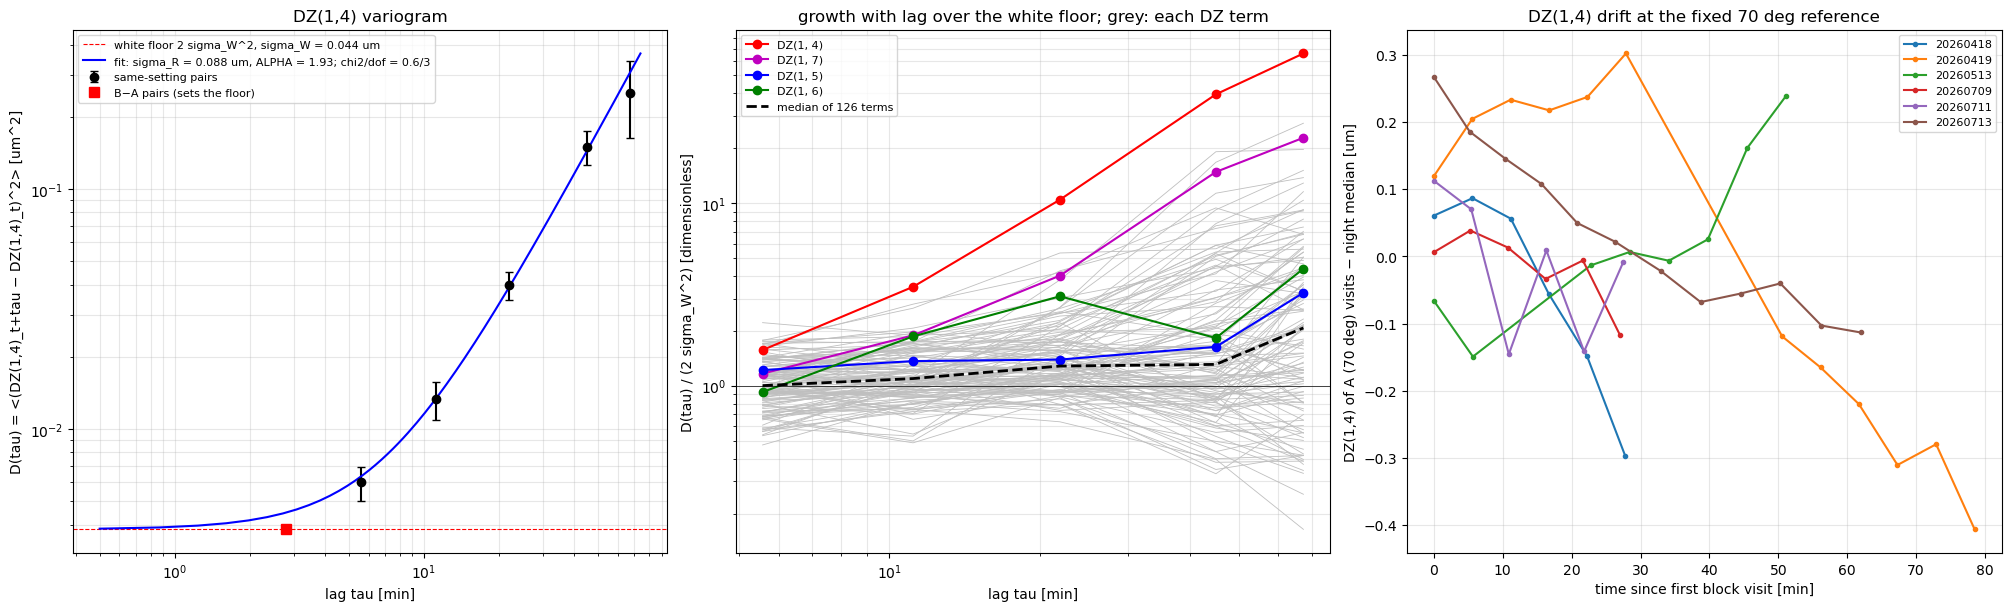

In [6]:
fig_vg, ax = plt.subplots(1, 3, figsize=(20, 6), layout='constrained')
tt_ = np.linspace(0.5, tb.max() * 1.1, 200)
ax[0].errorbar(tb, y, yerr=ey, fmt='ko', capsize=3, label='same-setting pairs')
ax[0].errorbar([pdf_pairs.lag_min.median()], [2 * SW_SD[i14] ** 2], fmt='rs', ms=7,
               label='B−A pairs (sets the floor)')
ax[0].axhline(2 * SW_SD[i14] ** 2, color='r', ls='--', lw=0.8,
              label=f'white floor 2 sigma_W^2, sigma_W = {SW_SD[i14]:.3f} um')
ax[0].plot(tt_, 2 * SW_SD[i14] ** 2 + SR14 ** 2 * (tt_ / T0_MIN) ** ALPHA14, 'b-',
           label=f'fit: sigma_R = {SR14:.3f} um, ALPHA = {ALPHA14:.2f}; chi2/dof = {chi2_r:.1f}/{dof_r}')
ax[0].set_xscale('log'); ax[0].set_yscale('log')
ax[0].set_xlabel('lag tau [min]'); ax[0].set_ylabel('D(tau) = <(DZ(1,4)_t+tau − DZ(1,4)_t)^2> [um^2]')
ax[0].set_title('DZ(1,4) variogram'); ax[0].legend(fontsize=8); ax[0].grid(alpha=0.3, which='both')
for a in range(NT):
    ax[1].plot(tb, ratio[:, a], '-', color='0.75', lw=0.6)
for a, col in [(i14, 'r'), (KJ.index((1, 7)), 'm'), (KJ.index((1, 5)), 'b'), (KJ.index((1, 6)), 'g')]:
    ax[1].plot(tb, ratio[:, a], 'o-', color=col, lw=1.5, label=f'DZ{KJ[a]}')
ax[1].plot(tb, np.median(ratio, 1), 'k--', lw=2, label='median of 126 terms')
ax[1].axhline(1, color='k', lw=0.5)
ax[1].set_xscale('log'); ax[1].set_yscale('log')
ax[1].set_xlabel('lag tau [min]'); ax[1].set_ylabel('D(tau) / (2 sigma_W^2) [dimensionless]')
ax[1].set_title('growth with lag over the white floor; grey: each DZ term')
ax[1].legend(fontsize=8); ax[1].grid(alpha=0.3, which='both')
for d in DAY_OBS:
    g = vv[(vv.night == d) & (vv.grp == 'A')].sort_values('t_min')
    if len(g):
        yy = W[g.row.to_numpy(), i14]
        ax[2].plot(g.t_min, yy - np.median(yy), 'o-', ms=3, color=plt.get_cmap('tab10')(DAY_OBS.index(d)), label=str(d))
ax[2].set_xlabel('time since first block visit [min]')
ax[2].set_ylabel('DZ(1,4) of A (70 deg) visits − night median [um]')
ax[2].set_title('DZ(1,4) drift at the fixed 70 deg reference'); ax[2].legend(fontsize=8); ax[2].grid(alpha=0.3)
plt.show()

<a id='mc'></a>
## A–B–A Δ, RBR and Monte Carlo errors

Per (night, leg):

- ΔDZ is the median over the B visits of the A–B–A differences, term by term.
- ΔDOF = RBR(ΔDZ), and Δv = ΔDOF · T_V.
- For the MC, the visits' DZ vectors are replaced by a draw from the model, with
  the real visit times. The white part has covariance `Σ_W`. DZ(1,4) adds a red
  part with time covariance
  `sigma_R^2 K(t, t')`, `K = (u^ALPHA + u'^ALPHA − |u − u'|^ALPHA) / 2` (u = t / T0).
- Each draw goes through the same A–B–A median, giving a noise draw δ. RBR is
  solved on ΔDZ + δ. The error on every quantity is the sd over N_MC draws.

RBR is nonlinear, so it is solved at the measured ΔDZ, not at 0. This is the
linearisation-free form of `J Σ J^T`.

In [7]:
LW = np.linalg.cholesky(SIG_W + 1e-12 * np.trace(SIG_W) / NT * np.eye(NT))
rng = np.random.default_rng(SEED)
res = {}
t_s = time.time()
for L in legs:
    d, lab = L['night'], L['leg']
    v = leg_visits(d, lab); M = aba_matrix(v); Y = W[v.row.to_numpy()]
    dz = np.median(M @ Y, 0)
    u = (v.t_min.to_numpy() - v.t_min.min()) / T0_MIN
    Kt = 0.5 * (u[:, None] ** ALPHA14 + u[None, :] ** ALPHA14 - np.abs(u[:, None] - u[None, :]) ** ALPHA14)
    Lt = np.linalg.cholesky(Kt + 1e-9 * np.eye(len(u)))
    noise = rng.normal(size=(N_MC, len(v), NT)) @ LW.T
    noise[:, :, i14] += SR14 * rng.normal(size=(N_MC, len(v))) @ Lt.T
    dz_mc = np.median(np.einsum('bi,mik->mbk', M, noise), 1)
    dof = rbr(dz)
    dof_mc = np.array([rbr(dz + x) for x in dz_mc])
    res[(d, lab)] = dict(dz=dz, dz_mc=dz_mc, dz_err=dz_mc.std(0, ddof=1), dof=dof, dof_mc=dof_mc,
                         dof_err=dof_mc.std(0, ddof=1), v=dof @ T_V,
                         v_err=(dof_mc @ T_V).std(0, ddof=1),
                         dof_bias=(dof_mc.mean(0) - dof) / dof_mc.std(0, ddof=1))
print(f'MC: {N_MC} draws × {len(legs)} legs in {time.time() - t_s:.0f} s')
mx_bias = max(np.nanmax(np.abs(r['dof_bias'])) for r in res.values())
print(f'largest |MC mean DOF − nominal DOF| / MC sd over all DOF and legs = {mx_bias:.2f} '
      f'(dimensionless; the RBR nonlinearity)')
rows = []
for L in legs:
    r = res[(L['night'], L['leg'])]
    rows.append({'night': L['night'], 'leg': L['leg'], 'b_value_deg': L['b_value_deg'],
                 'dDZ_1_4_um': r['dz'][i14], 'dDZ_1_4_err_um': r['dz_err'][i14],
                 'dv1': r['v'][0], 'dv1_err': r['v_err'][0],
                 'dM2_dz_um': r['dof'][0], 'dM2_dz_err_um': r['dof_err'][0],
                 'dCam_dz_um': r['dof'][5], 'dCam_dz_err_um': r['dof_err'][5],
                 'corr_M2dz_Camdz': np.corrcoef(r['dof_mc'][:, 0], r['dof_mc'][:, 5])[0, 1]})
key = pd.DataFrame(rows)
key.round(4)

MC: 1000 draws × 7 legs in 24 s
largest |MC mean DOF − nominal DOF| / MC sd over all DOF and legs = 1.44 (dimensionless; the RBR nonlinearity)


,night,leg,b_value_deg,dDZ_1_4_um,dDZ_1_4_err_um,dv1,dv1_err,dM2_dz_um,dM2_dz_err_um,dCam_dz_um,dCam_dz_err_um,corr_M2dz_Camdz
0,20260418,Elev=40,40.0,-0.0682,0.0308,-0.0075,0.0020,-70.2946,18.2861,57.0766,17.4721,-0.9924
1,20260419,Elev=40,40.0,-0.1219,0.0233,-0.0113,0.0016,-38.9478,14.1291,31.8564,13.4376,-0.9919
2,20260513,Elev=40,40.0,0.0086,0.0272,-0.0030,0.0018,-41.3845,18.7734,28.1129,16.5028,-0.9891
3,20260709,Elev=60,60.0,0.0703,0.0399,0.0064,0.0026,60.4782,26.0858,-51.2353,23.6545,-0.9890
4,20260711,Elev=50,50.0,0.1751,0.0306,0.0142,0.0020,-84.9448,27.6215,72.0010,23.8119,-0.9935
5,20260713,Elev=30,30.0,0.3660,0.0314,0.0195,0.0020,-30.4829,26.7858,0.8263,22.7644,-0.9910
6,20260713,Elev=75,75.0,0.0146,0.0275,0.0011,0.0018,-0.0861,29.8865,0.4652,24.8804,-0.9947


<a id='dofsplit'></a>
## Why the DOF do not show the v1 pattern

v1 = 1 is M2_dz = −464 um with Cam_dz = −646 um: mostly the two hexapod dz
moving together, which is focus. The difference of the two (M2 dz against
camera dz at fixed focus) is poorly constrained by the wavefront. So the noise
puts the two DOF on a long anticorrelated line.

Each DOF alone has a large error, and the measured values scatter along that
line. Their weighted sum, v1, is well measured. Below are the two hexapod dz
values per leg, with the MC 1-sigma ellipse and the line of constant v1 through
each point.

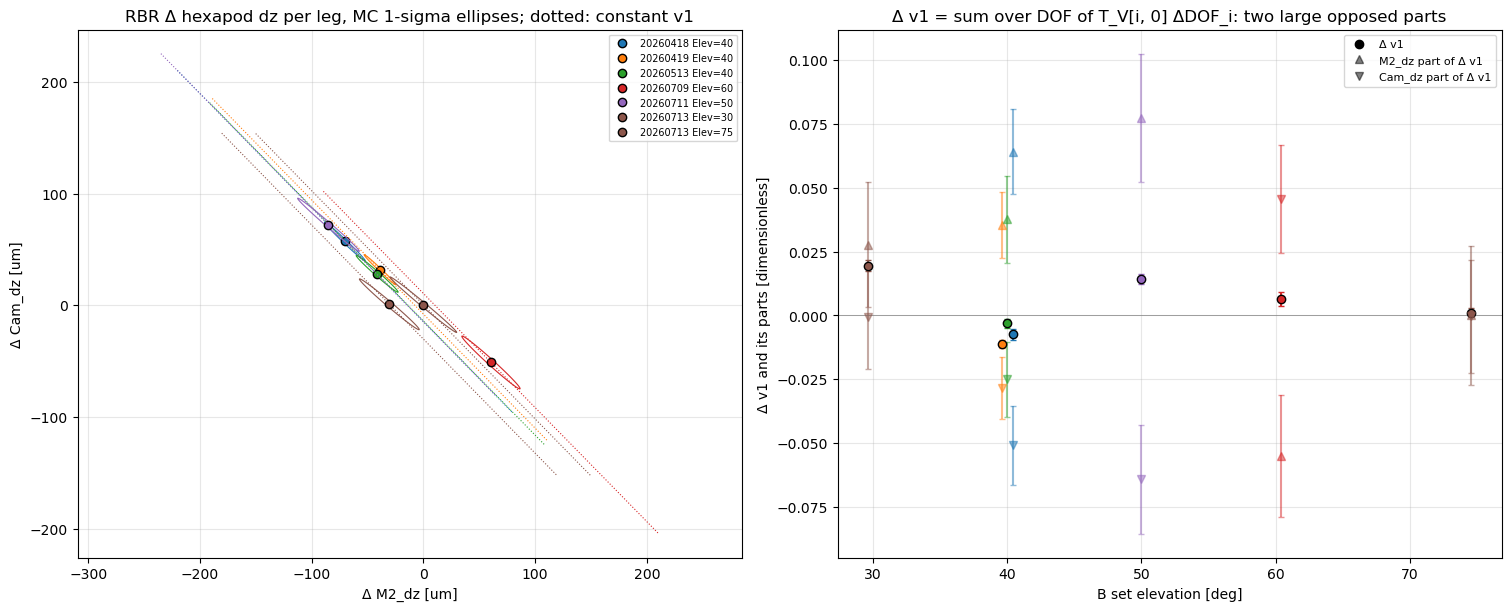

In [8]:
ncol = {n: plt.get_cmap('tab10')(i % 10) for i, n in enumerate(sorted({L['night'] for L in legs}))}
fig_split, ax = plt.subplots(1, 2, figsize=(15, 6), layout='constrained')
for L in legs:
    r = res[(L['night'], L['leg'])]; c = ncol[L['night']]
    x, y = r['dof'][0], r['dof'][5]
    C2 = np.cov(r['dof_mc'][:, [0, 5]].T); e, U = np.linalg.eigh(C2)
    th = np.linspace(0, 2 * np.pi, 100); el = U @ (np.sqrt(e)[:, None] * np.array([np.cos(th), np.sin(th)]))
    ax[0].plot(x + el[0], y + el[1], '-', color=c, lw=0.8)
    ax[0].plot(x, y, 'o', color=c, mec='k', label=f'{L["night"]} {L["leg"]}')
    s = np.linspace(-150, 150, 2)
    ax[0].plot(x + s, y - s * T_V[0, 0] / T_V[5, 0], ':', color=c, lw=0.8)
ax[0].set_xlabel('Δ M2_dz [um]'); ax[0].set_ylabel('Δ Cam_dz [um]')
ax[0].set_title('RBR Δ hexapod dz per leg, MC 1-sigma ellipses; dotted: constant v1')
ax[0].legend(fontsize=7); ax[0].grid(alpha=0.3); ax[0].axis('equal')
for L in legs:
    r = res[(L['night'], L['leg'])]
    ax[1].errorbar(L['b_value_deg'] + 0.4 * (L['night'] % 3 - 1), r['v'][0], yerr=r['v_err'][0], fmt='o',
                   color=ncol[L['night']], mec='k', capsize=2)
    ax[1].errorbar(L['b_value_deg'] + 0.4 * (L['night'] % 3 - 1),
                   r['dof'][0] * T_V[0, 0], yerr=r['dof_err'][0] * abs(T_V[0, 0]), fmt='^',
                   color=ncol[L['night']], alpha=0.5, capsize=2)
    ax[1].errorbar(L['b_value_deg'] + 0.4 * (L['night'] % 3 - 1),
                   r['dof'][5] * T_V[5, 0], yerr=r['dof_err'][5] * abs(T_V[5, 0]), fmt='v',
                   color=ncol[L['night']], alpha=0.5, capsize=2)
ax[1].plot([], [], 'ko', label='Δ v1'); ax[1].plot([], [], 'k^', alpha=0.5, label='M2_dz part of Δ v1')
ax[1].plot([], [], 'kv', alpha=0.5, label='Cam_dz part of Δ v1')
ax[1].axhline(0, color='gray', lw=0.5); ax[1].legend(fontsize=8); ax[1].grid(alpha=0.3)
ax[1].set_xlabel('B set elevation [deg]'); ax[1].set_ylabel('Δ v1 and its parts [dimensionless]')
ax[1].set_title('Δ v1 = sum over DOF of T_V[i, 0] ΔDOF_i: two large opposed parts')
plt.show()

<a id='plots'></a>
## Plots: DZ, v-modes, DOF vs elevation

One point per (night, leg), with its MC error. The three 40 deg nights are
offset by ±0.6 deg in x so they do not overlap. Each panel title gives
chi2/dof of the three 40 deg nights about their weighted mean (dof = 2). It is
a consistency test of the 40 deg nights in that quantity.

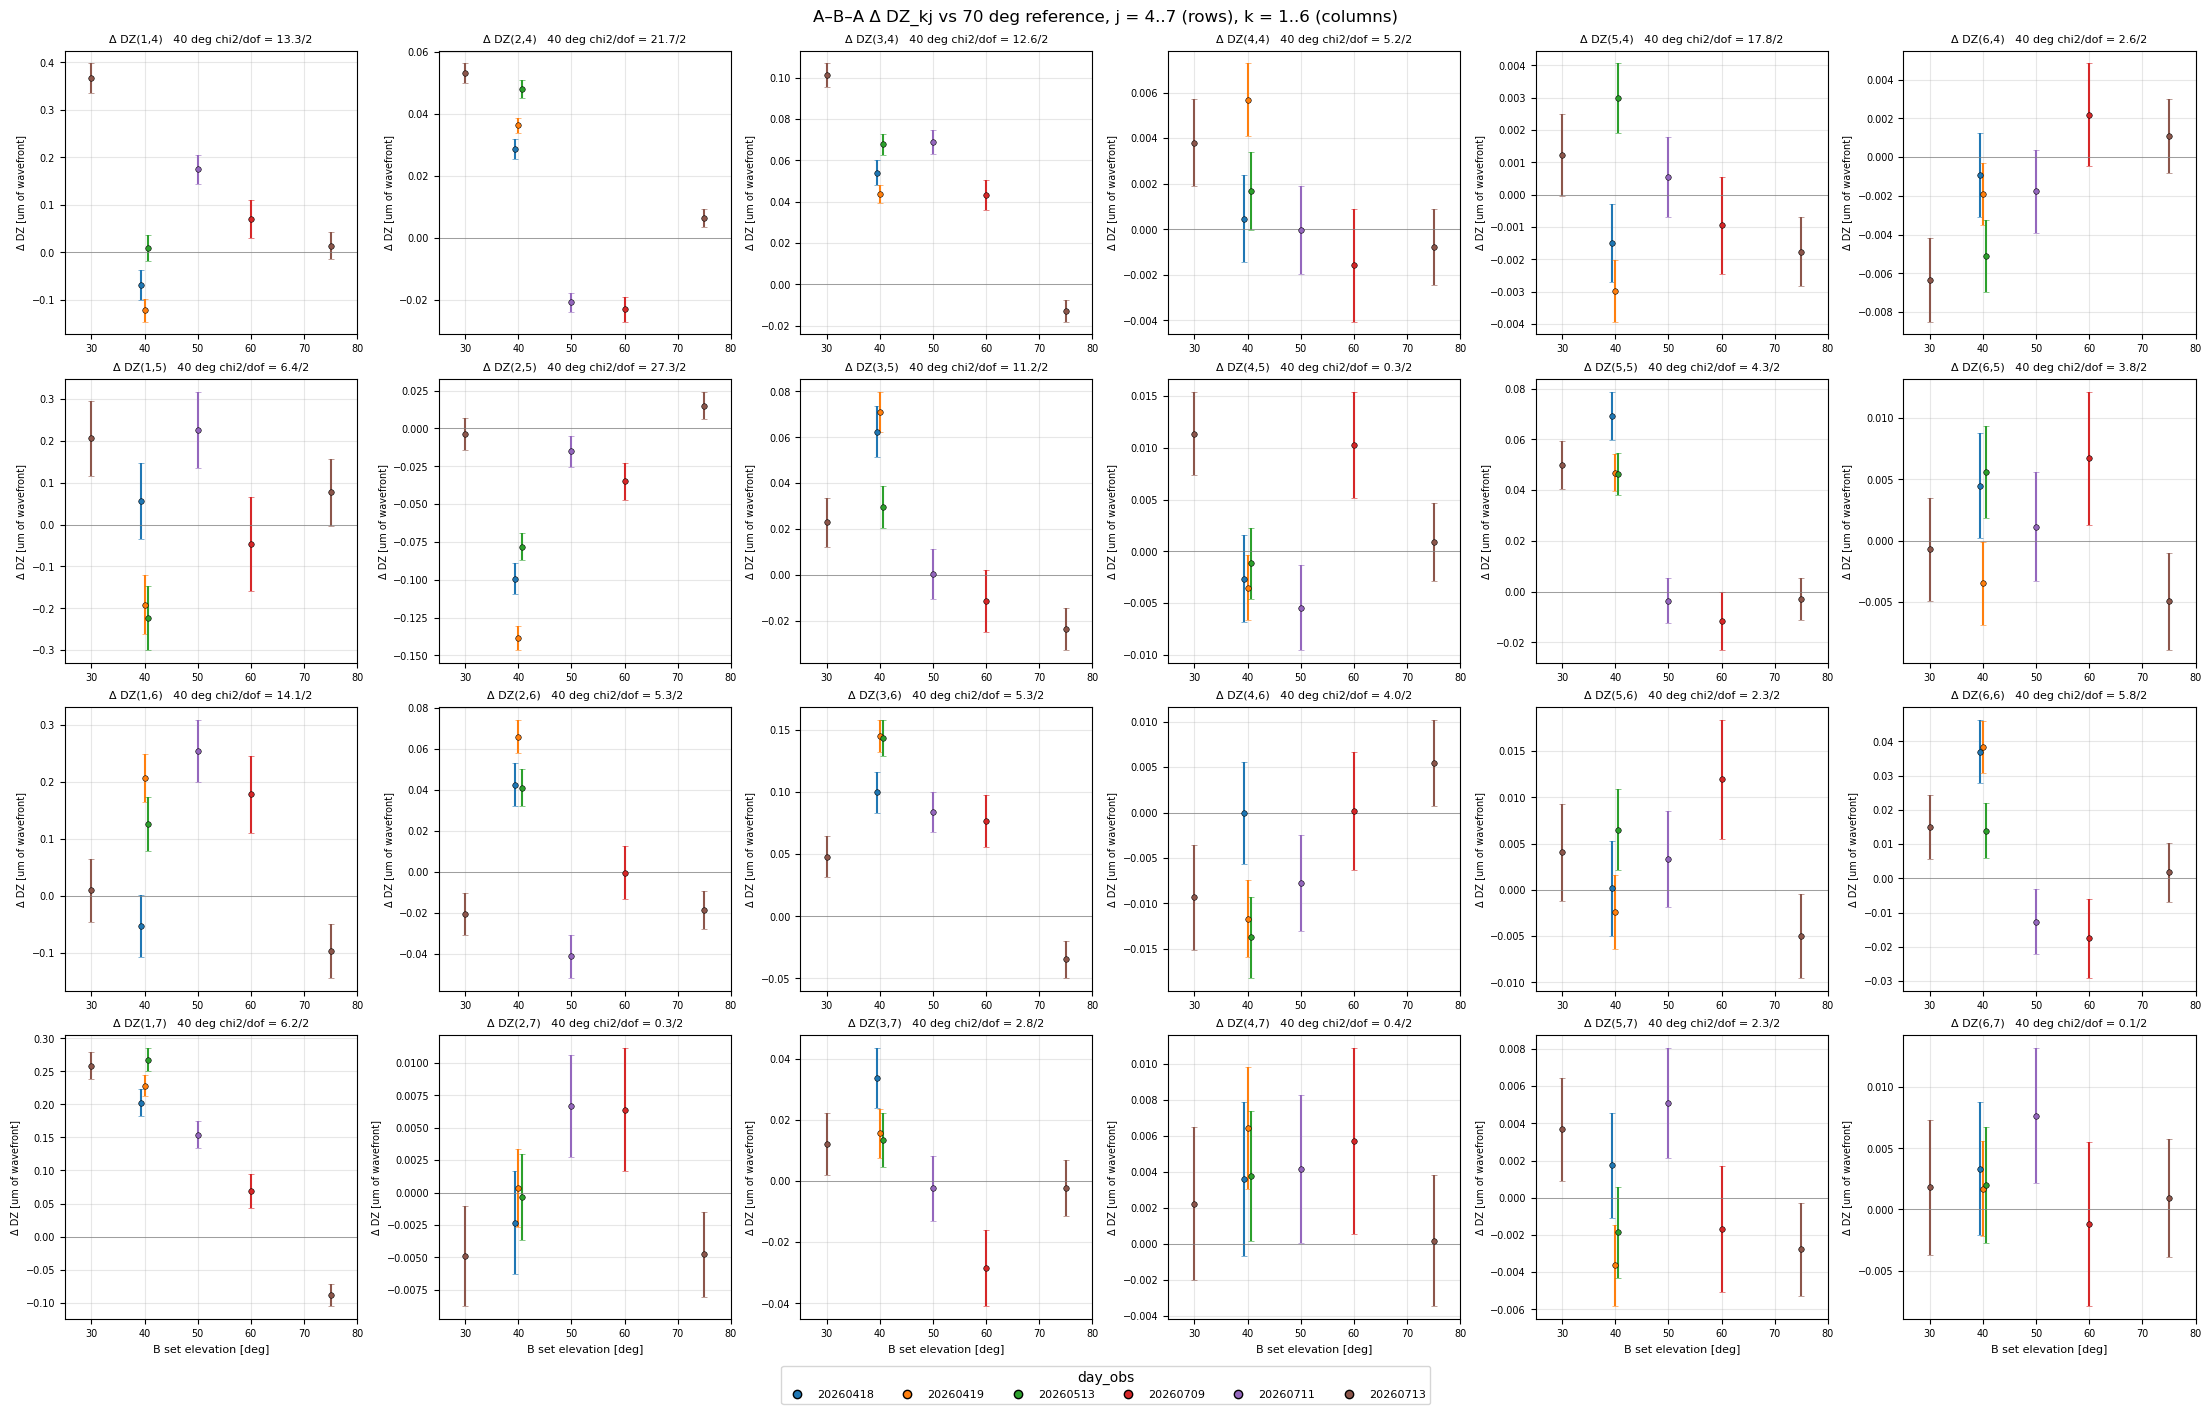

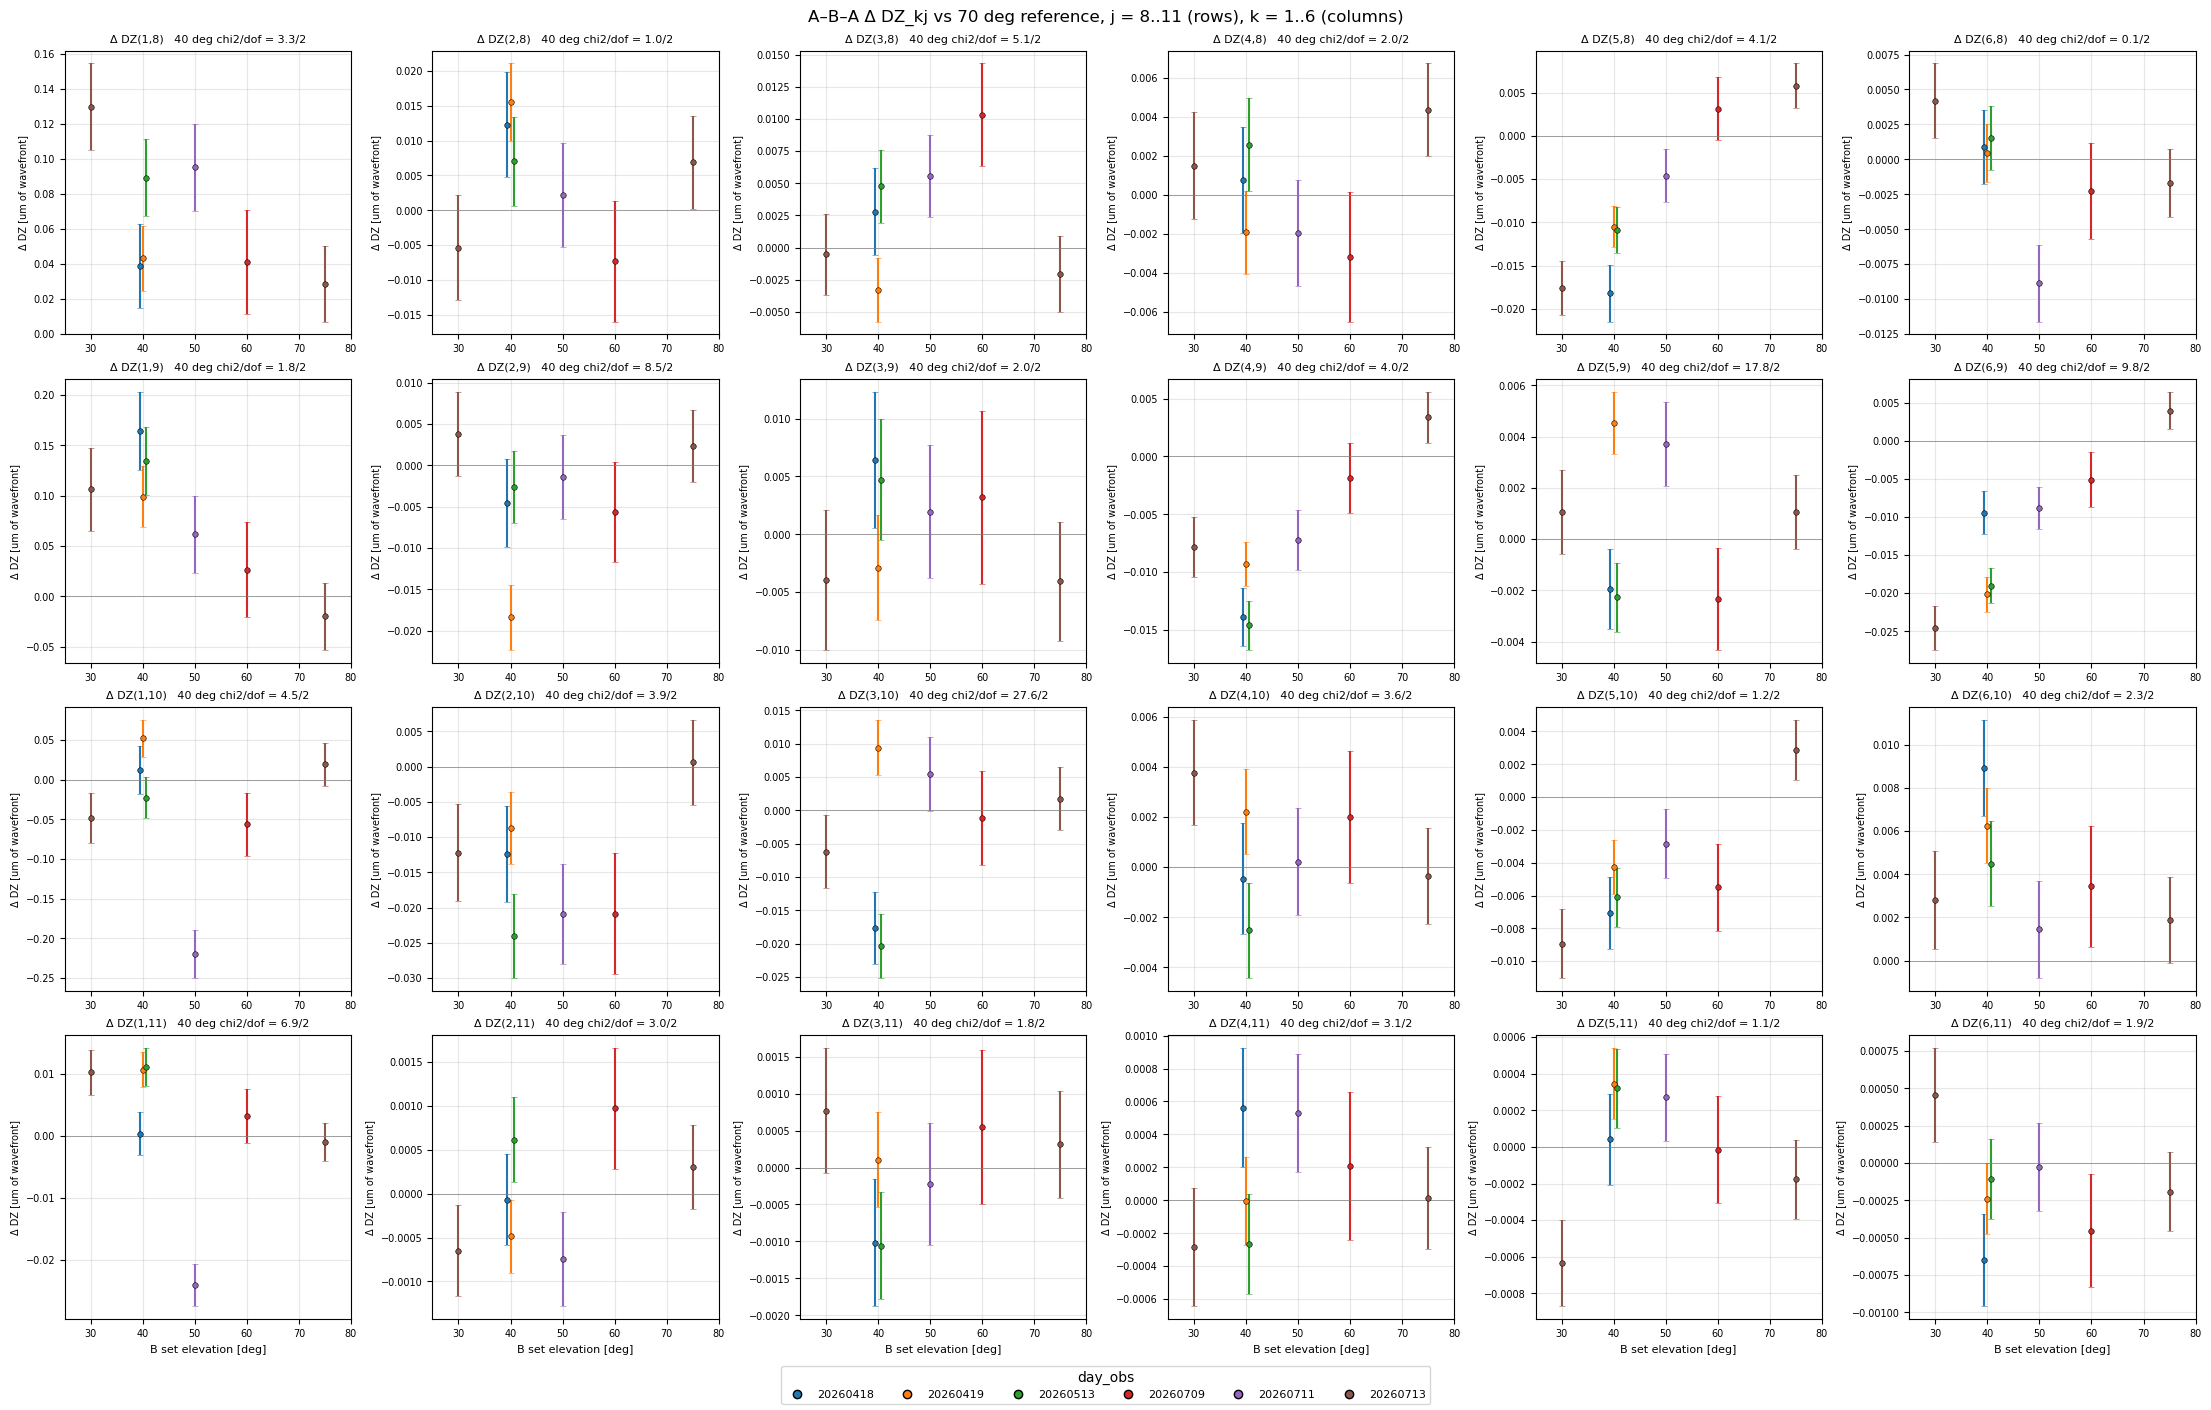

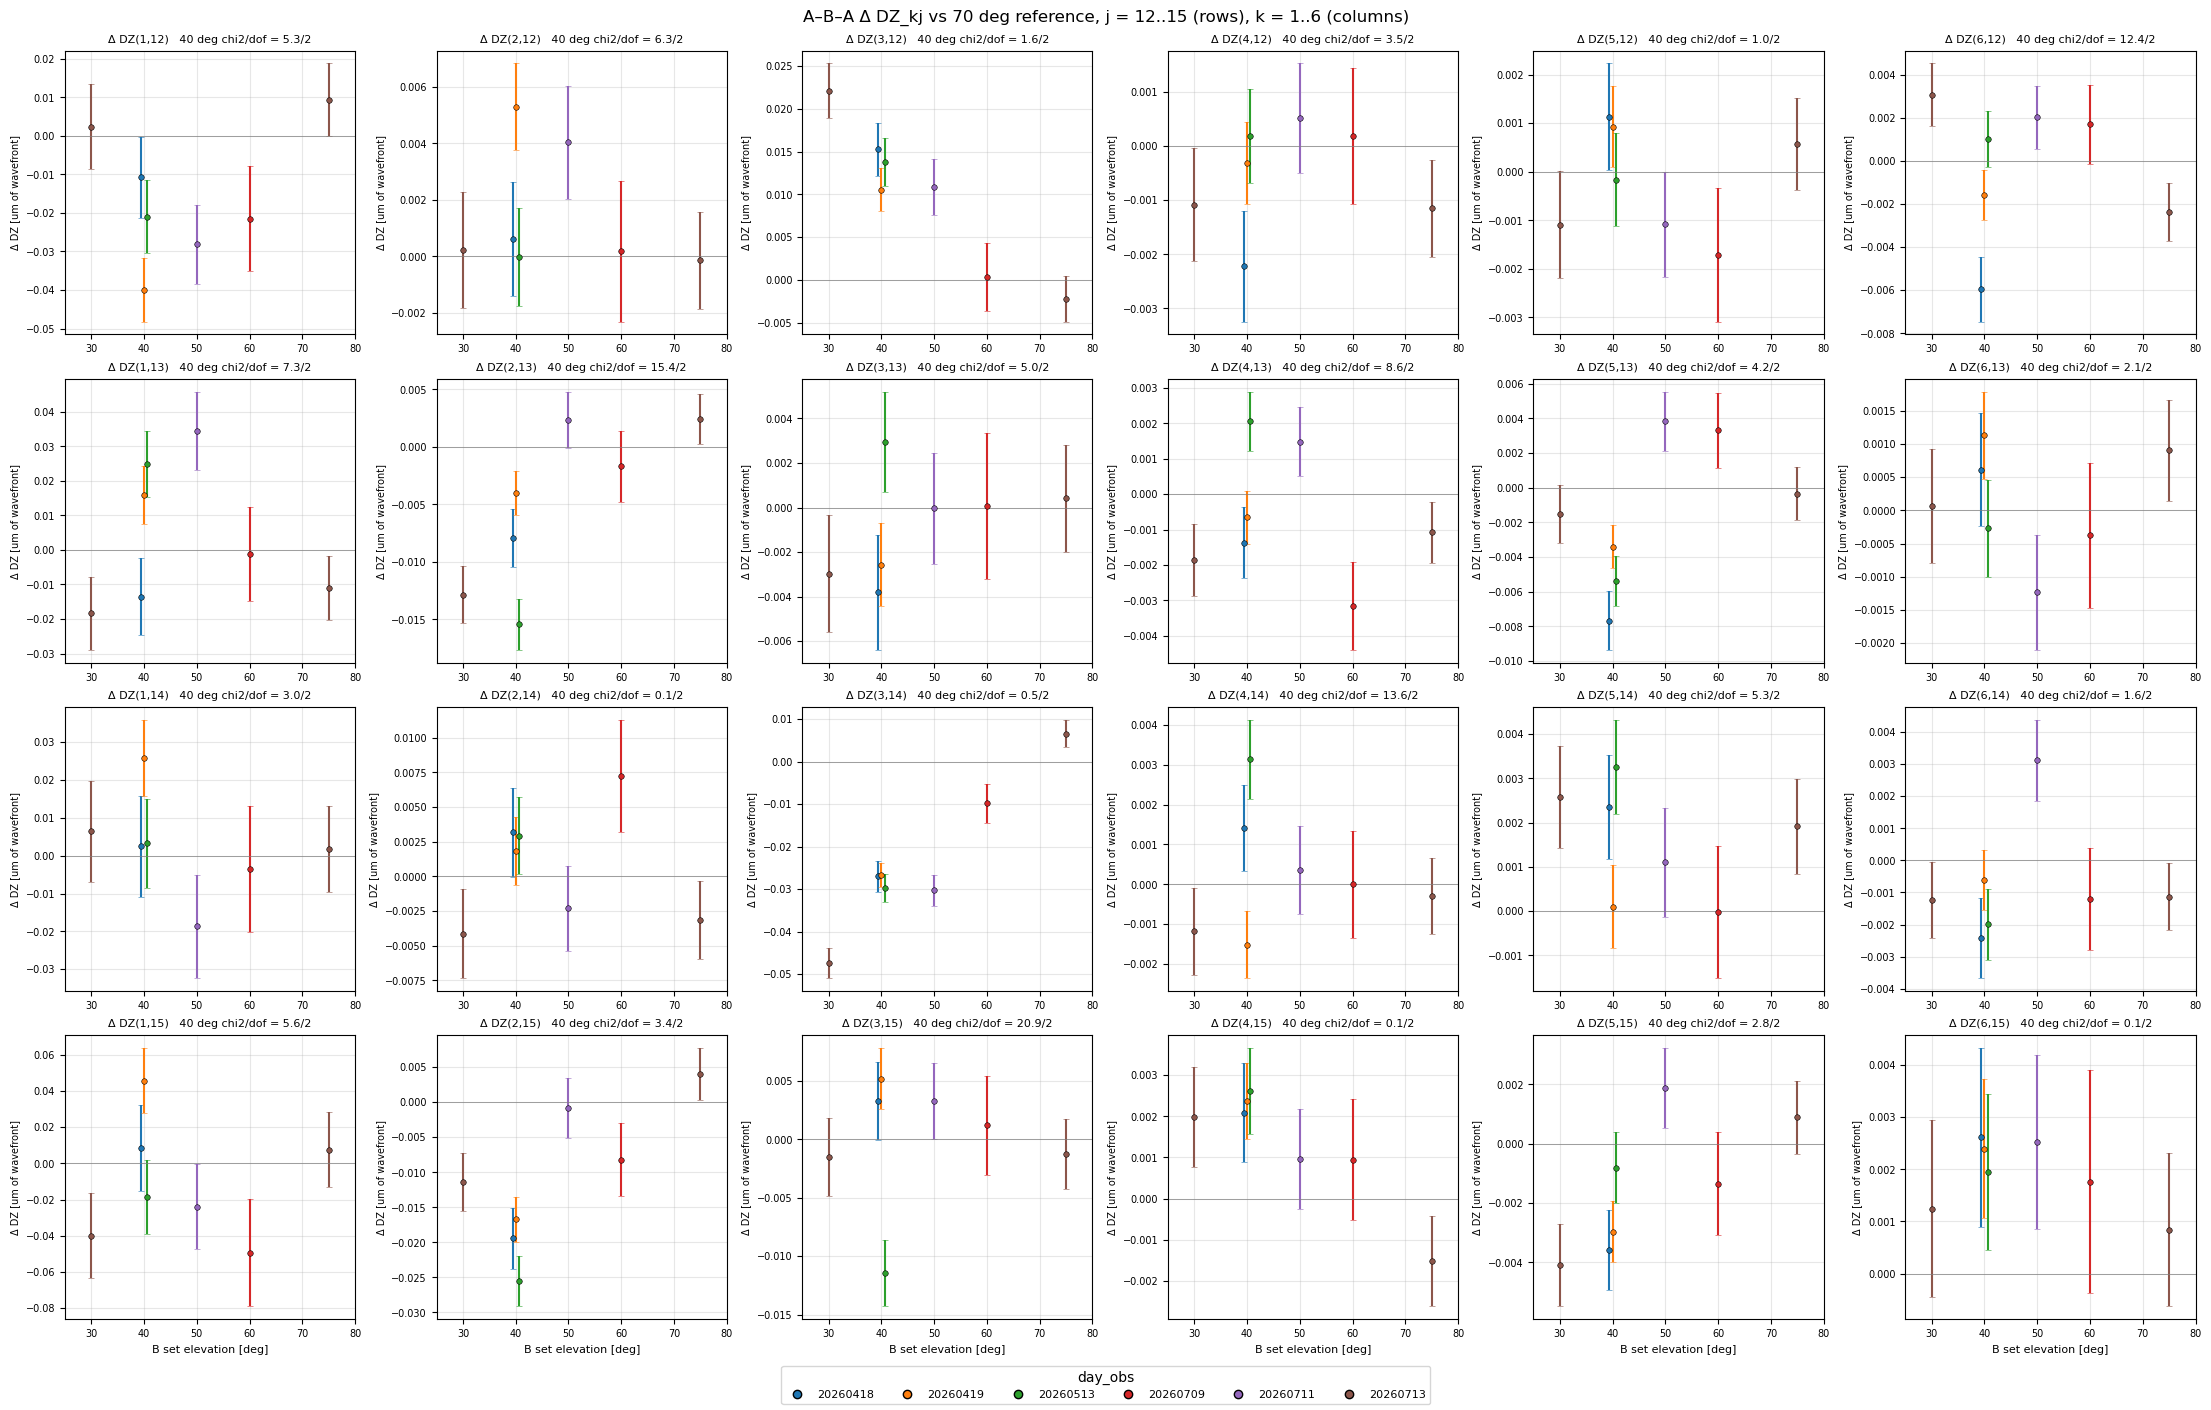

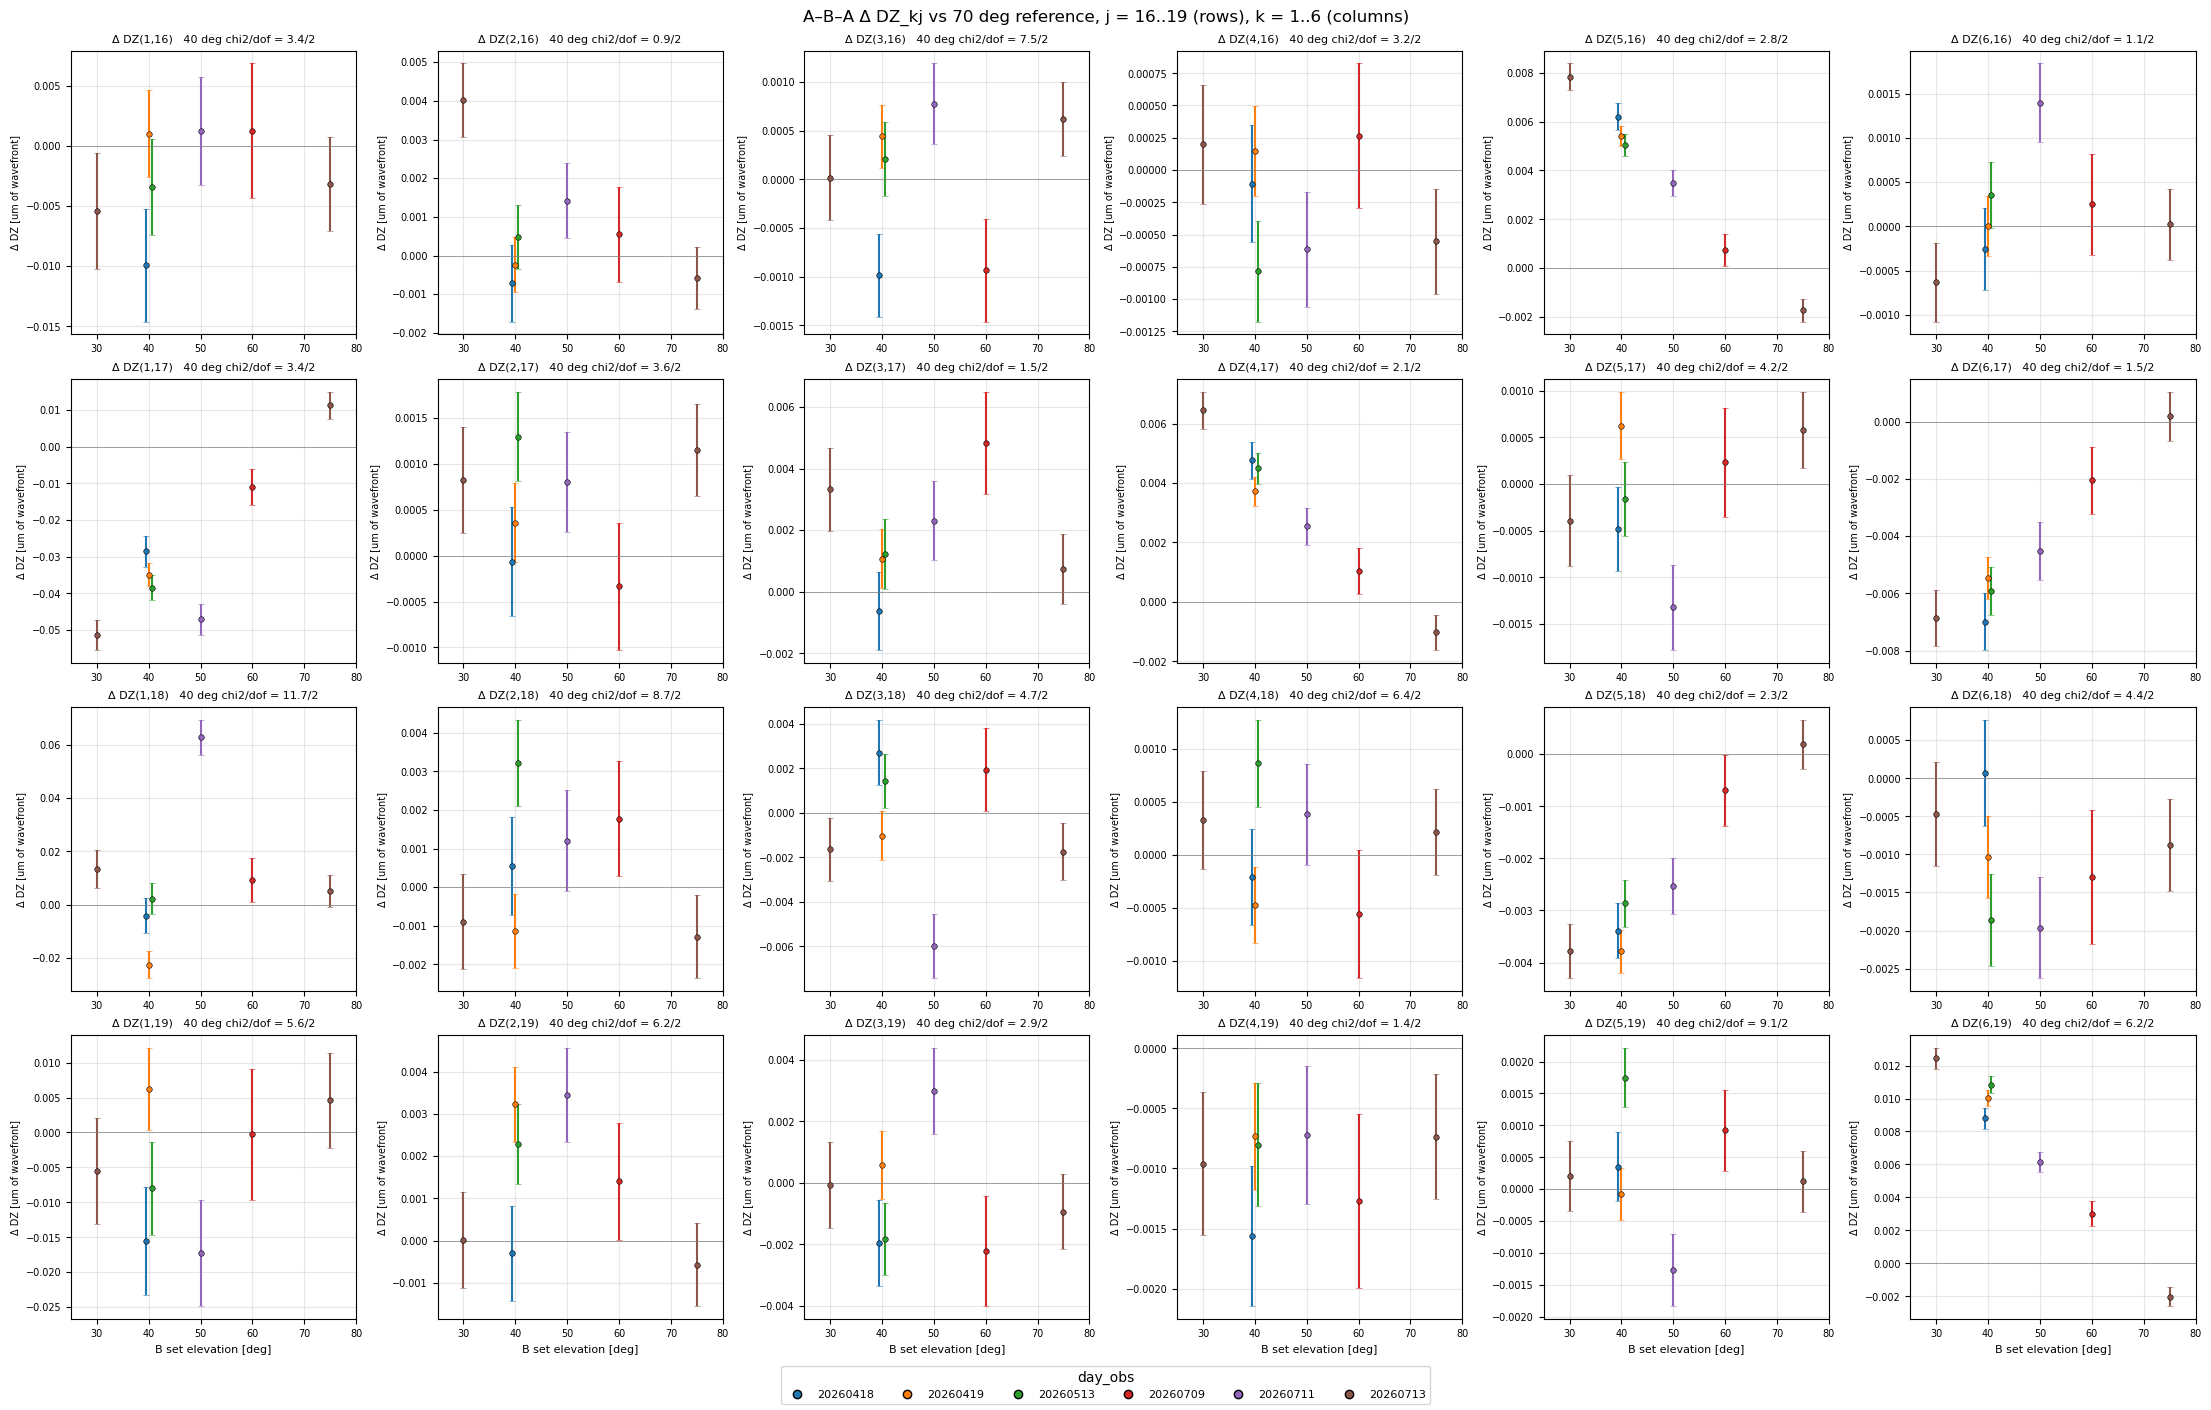

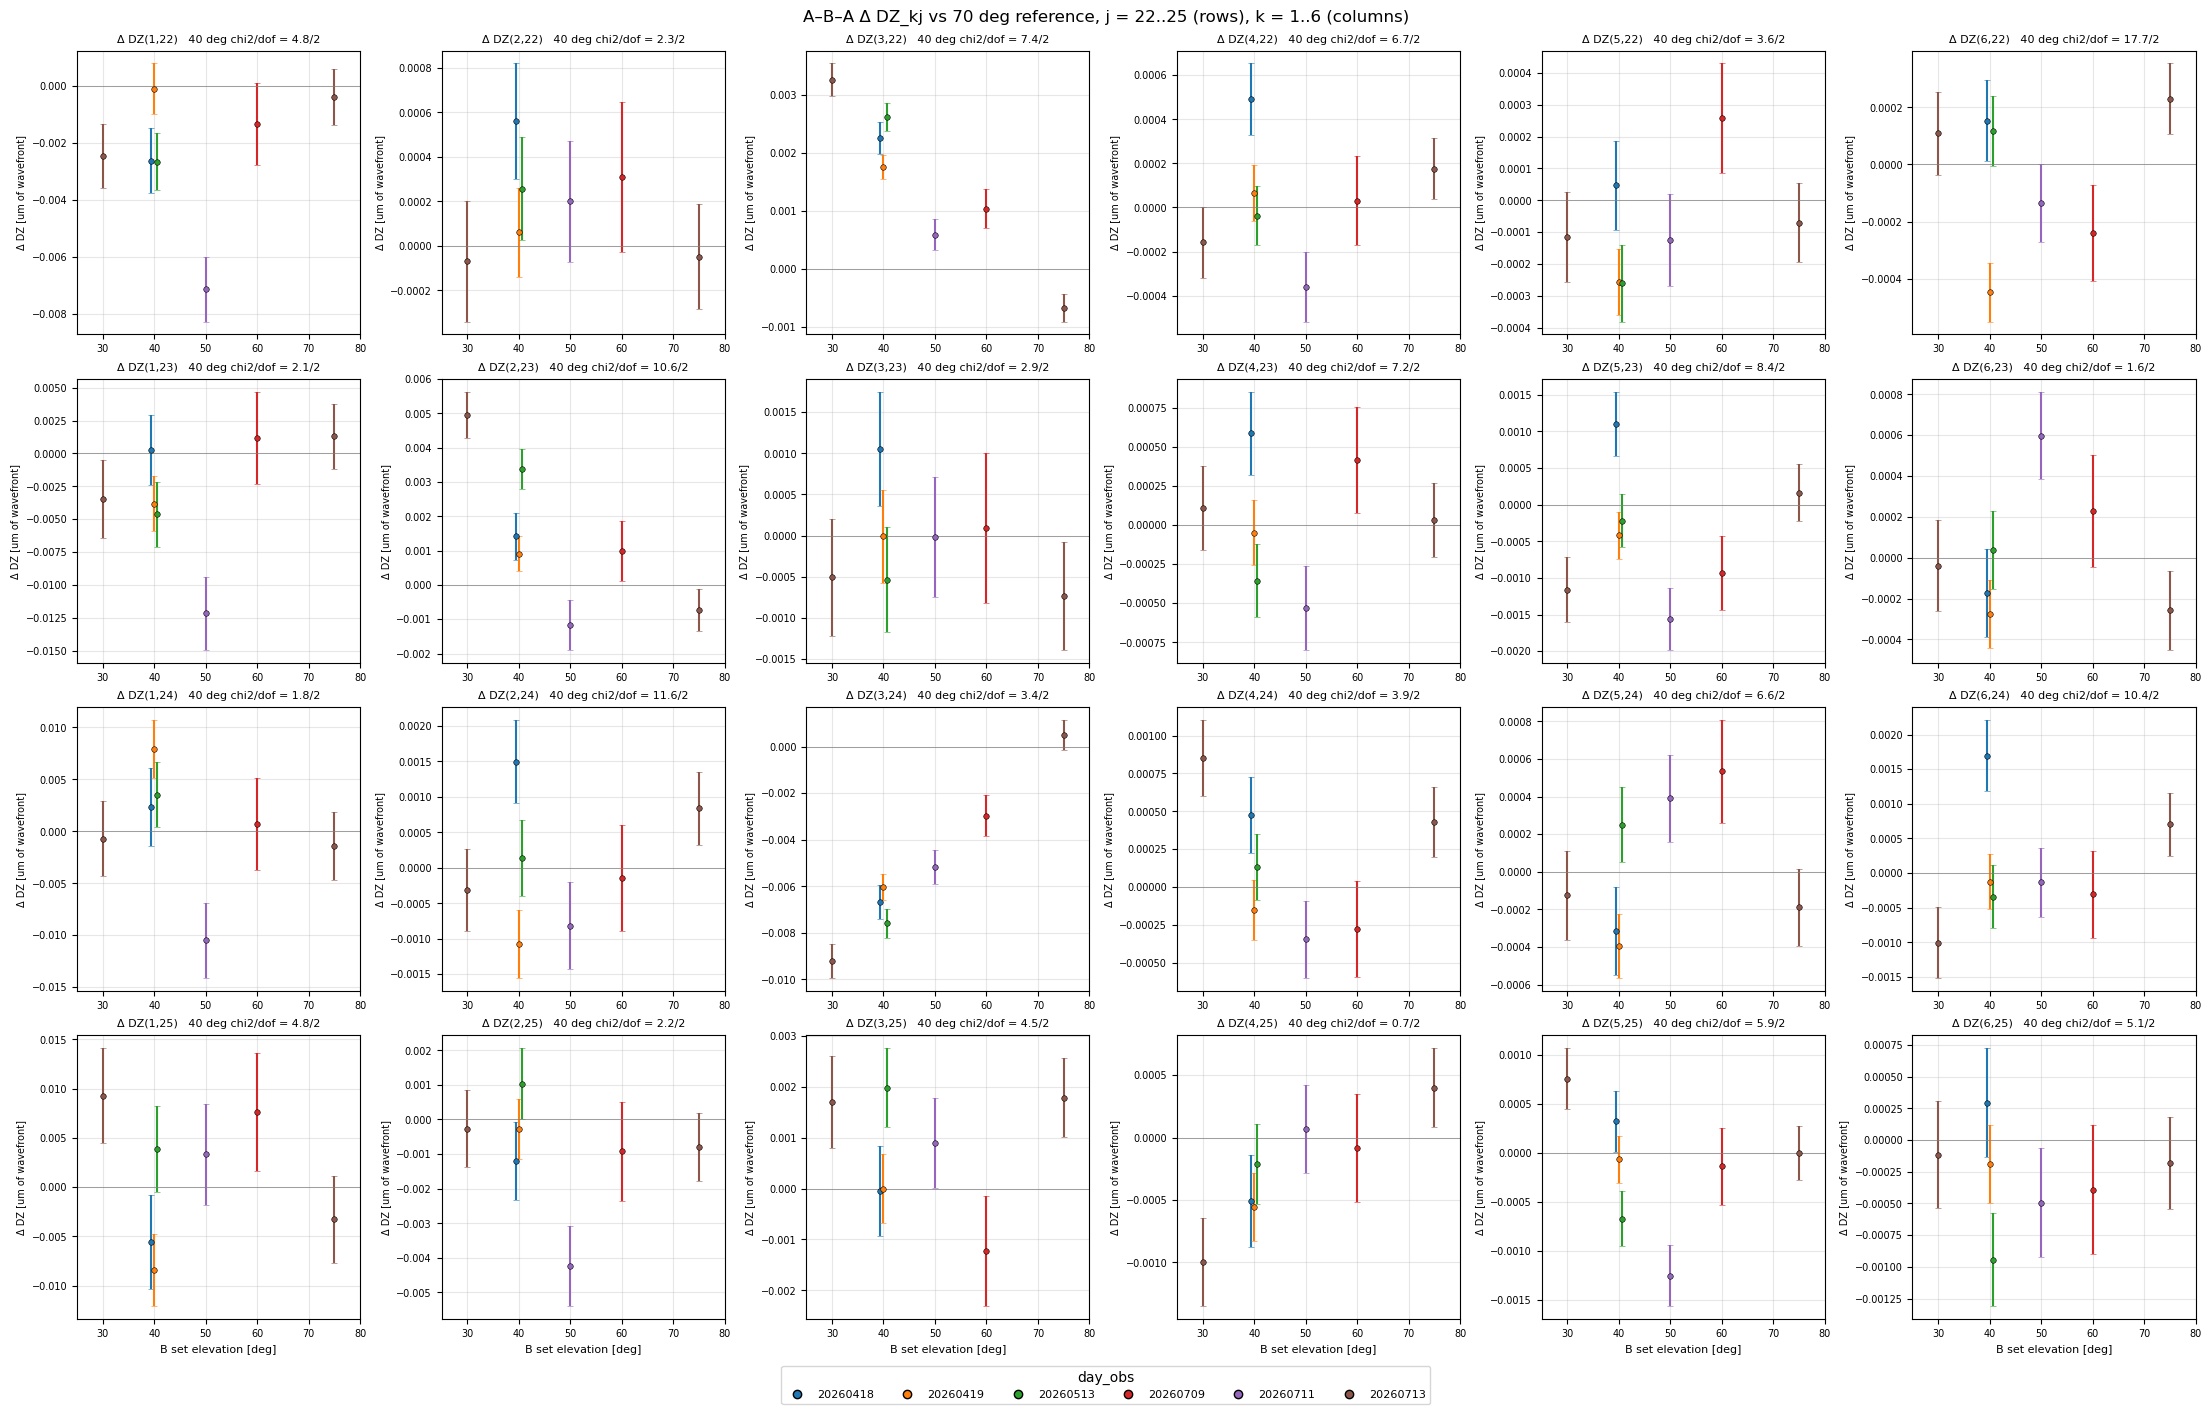

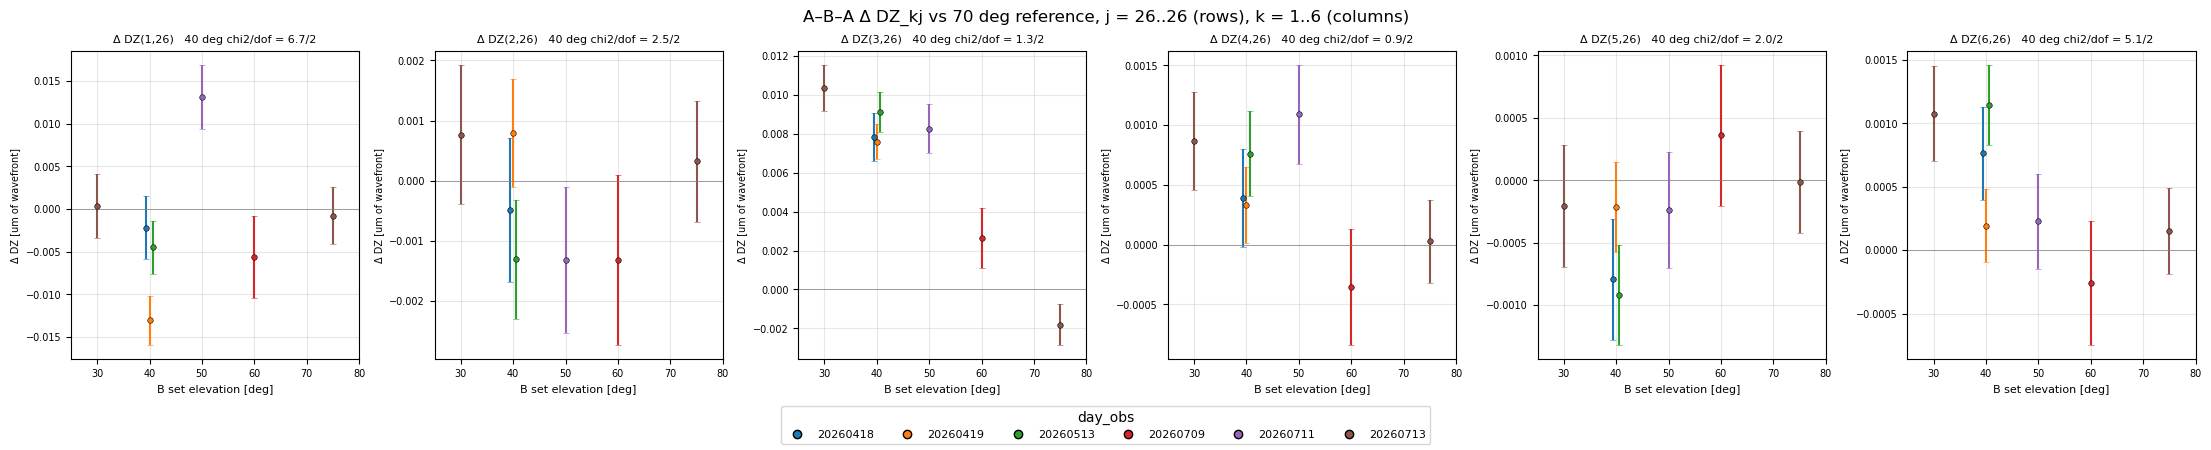

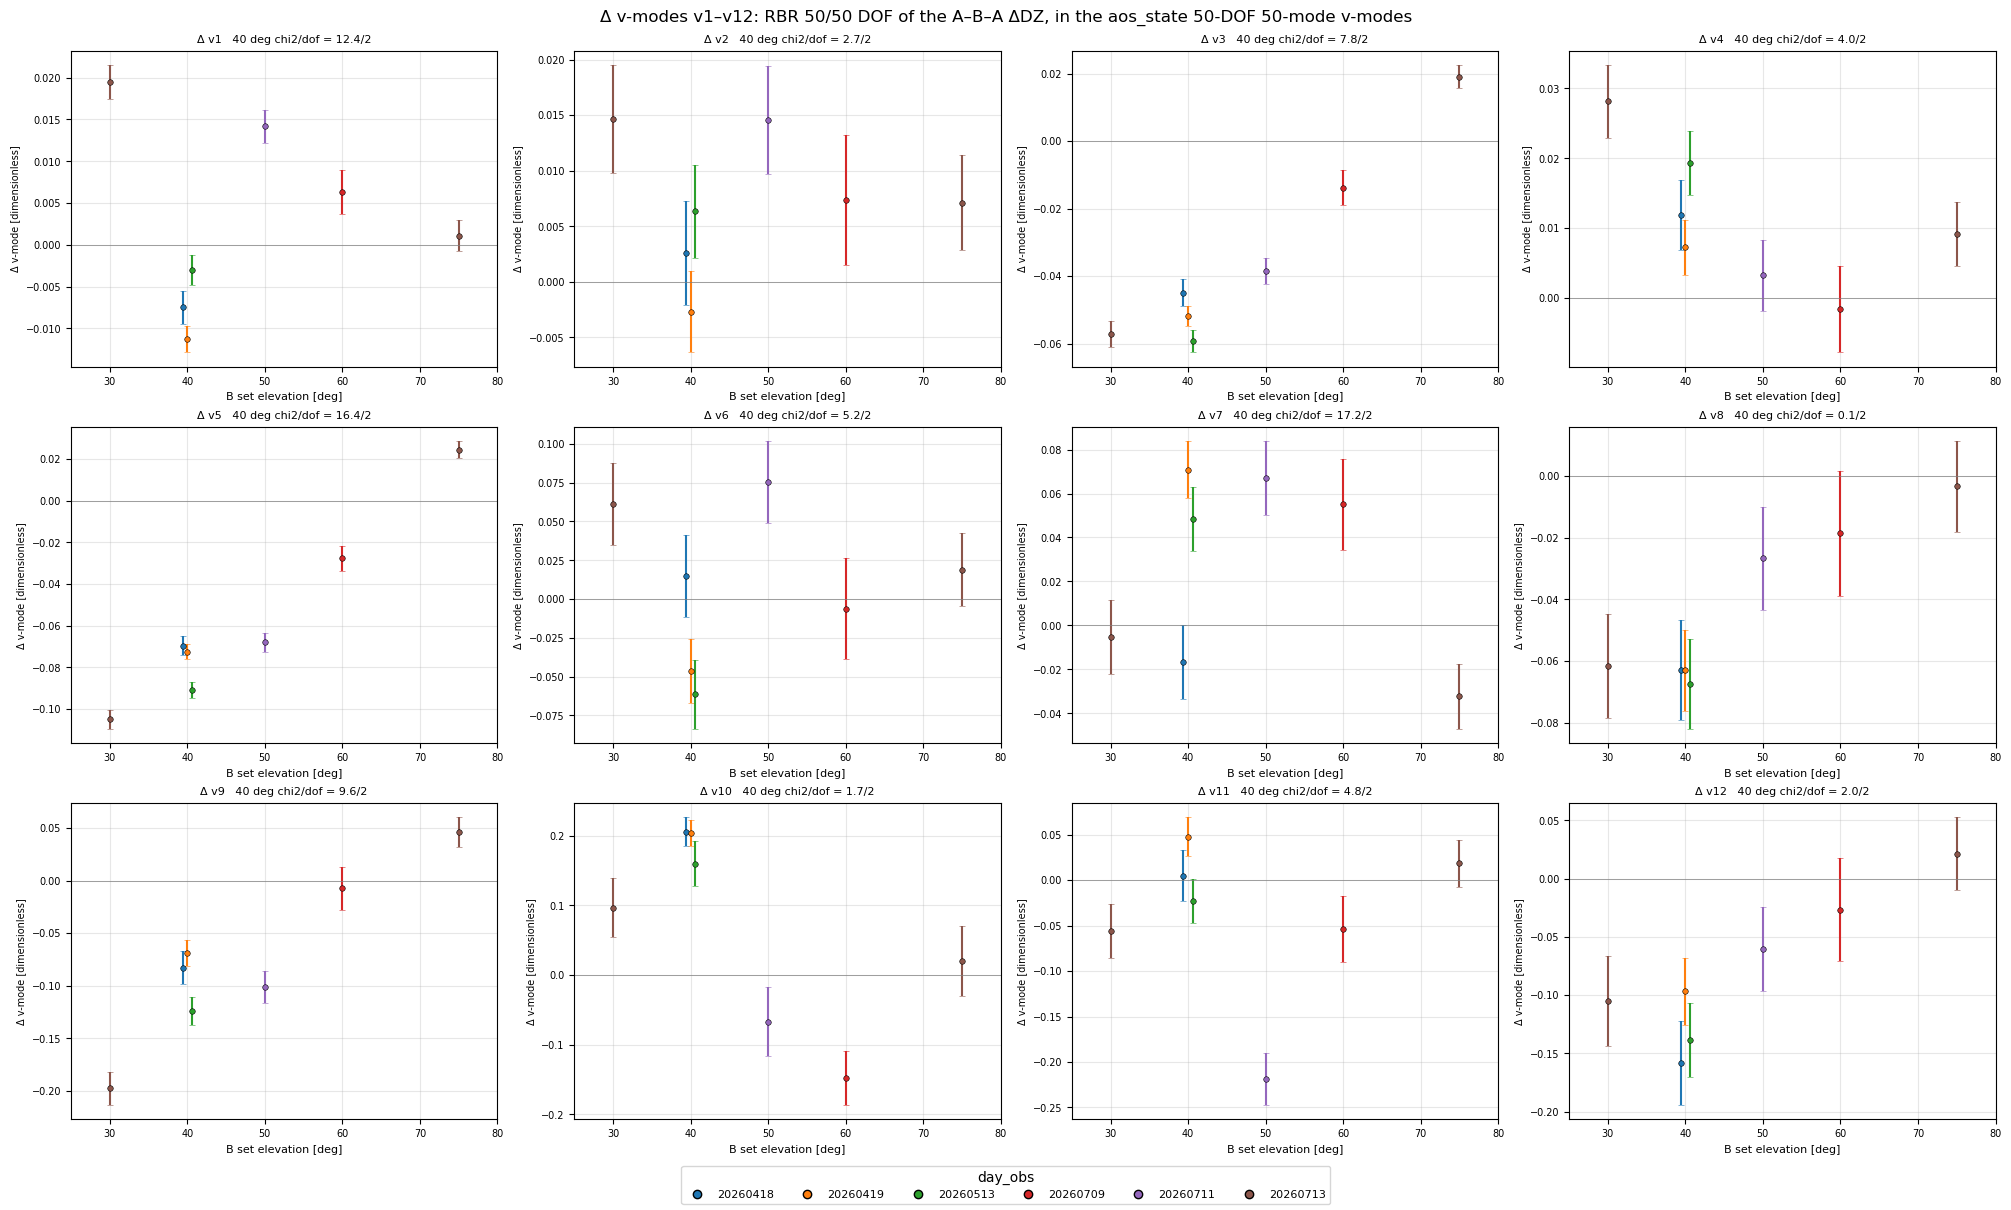

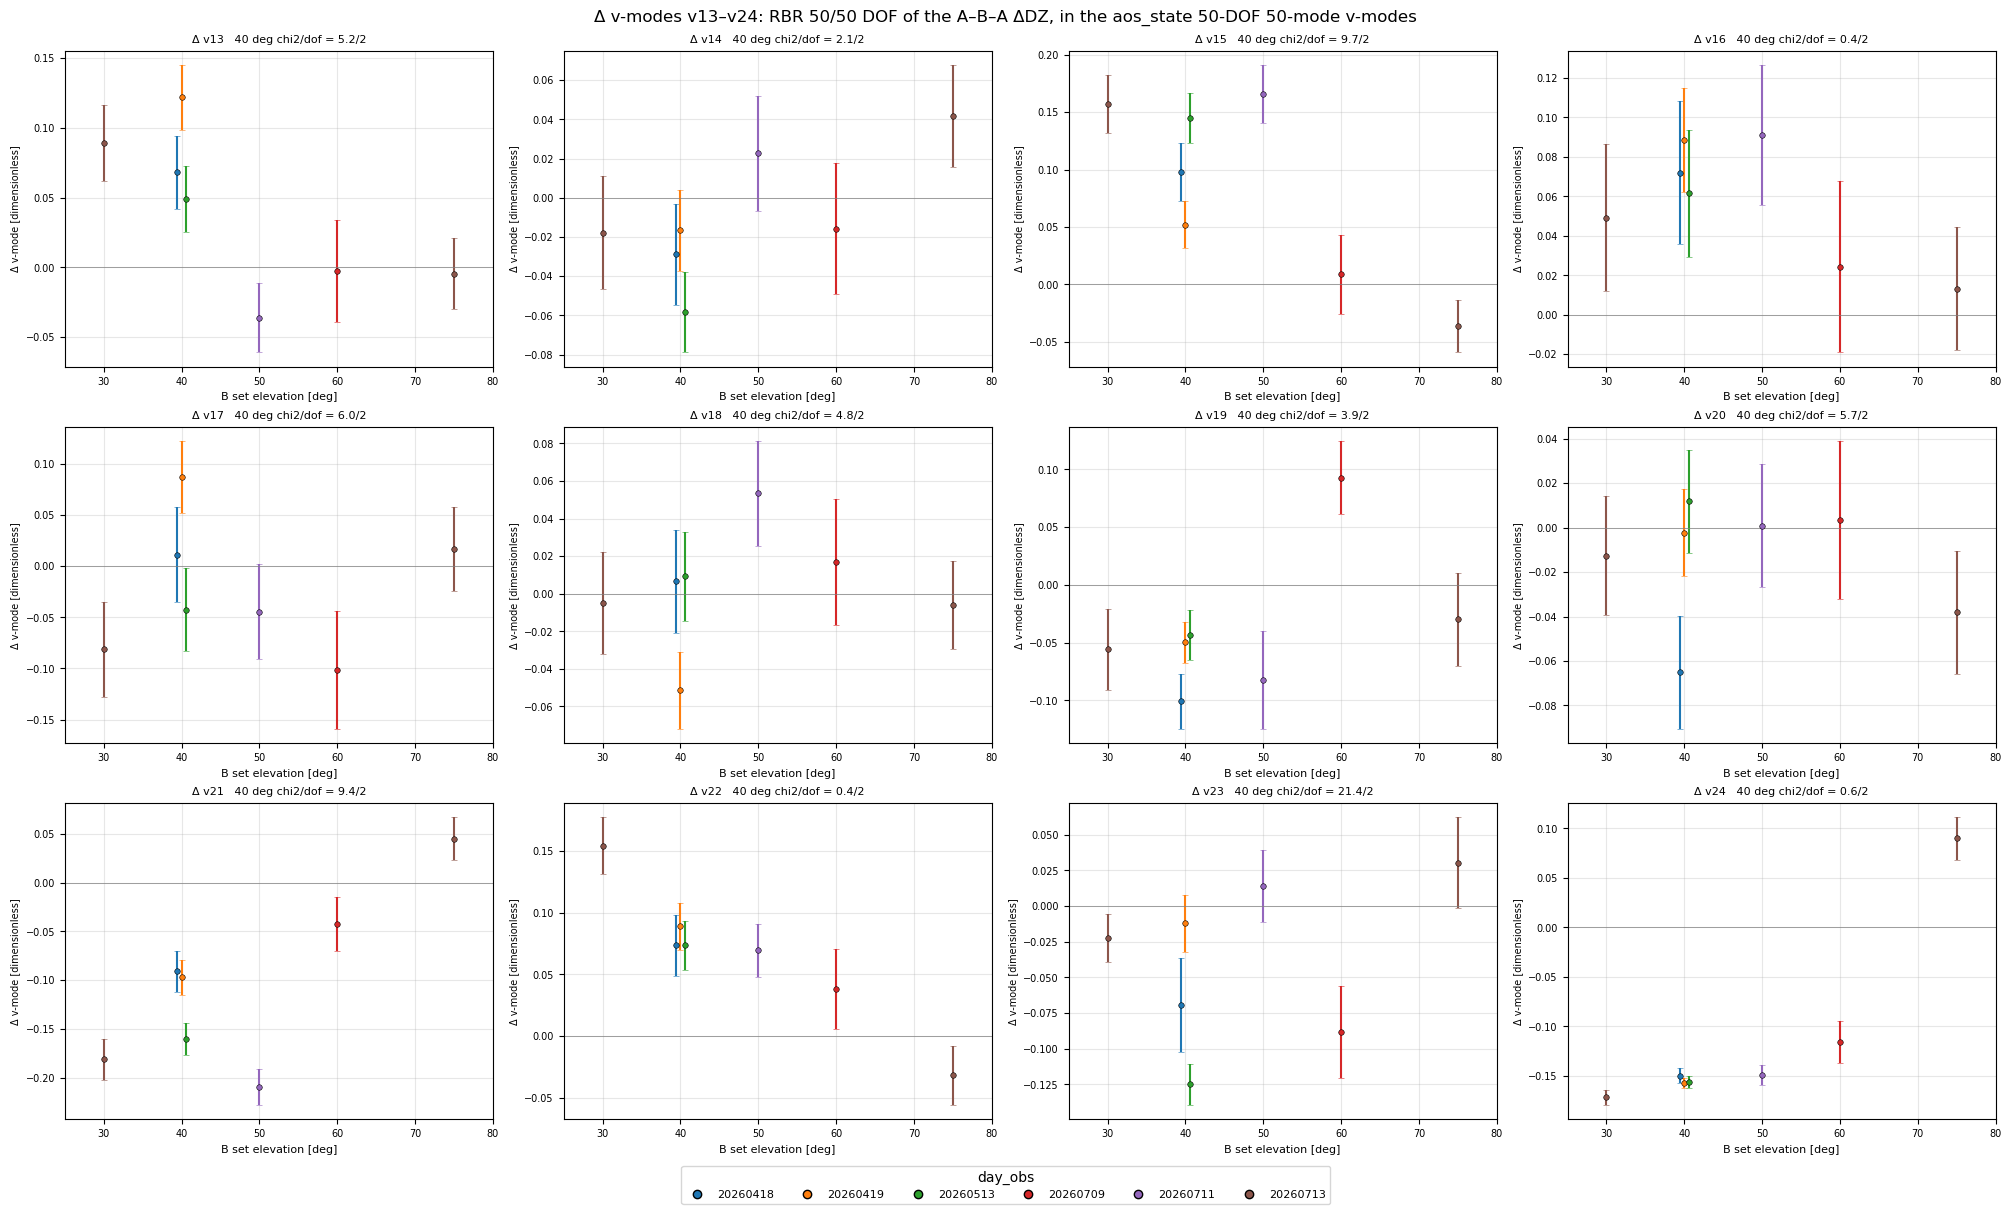

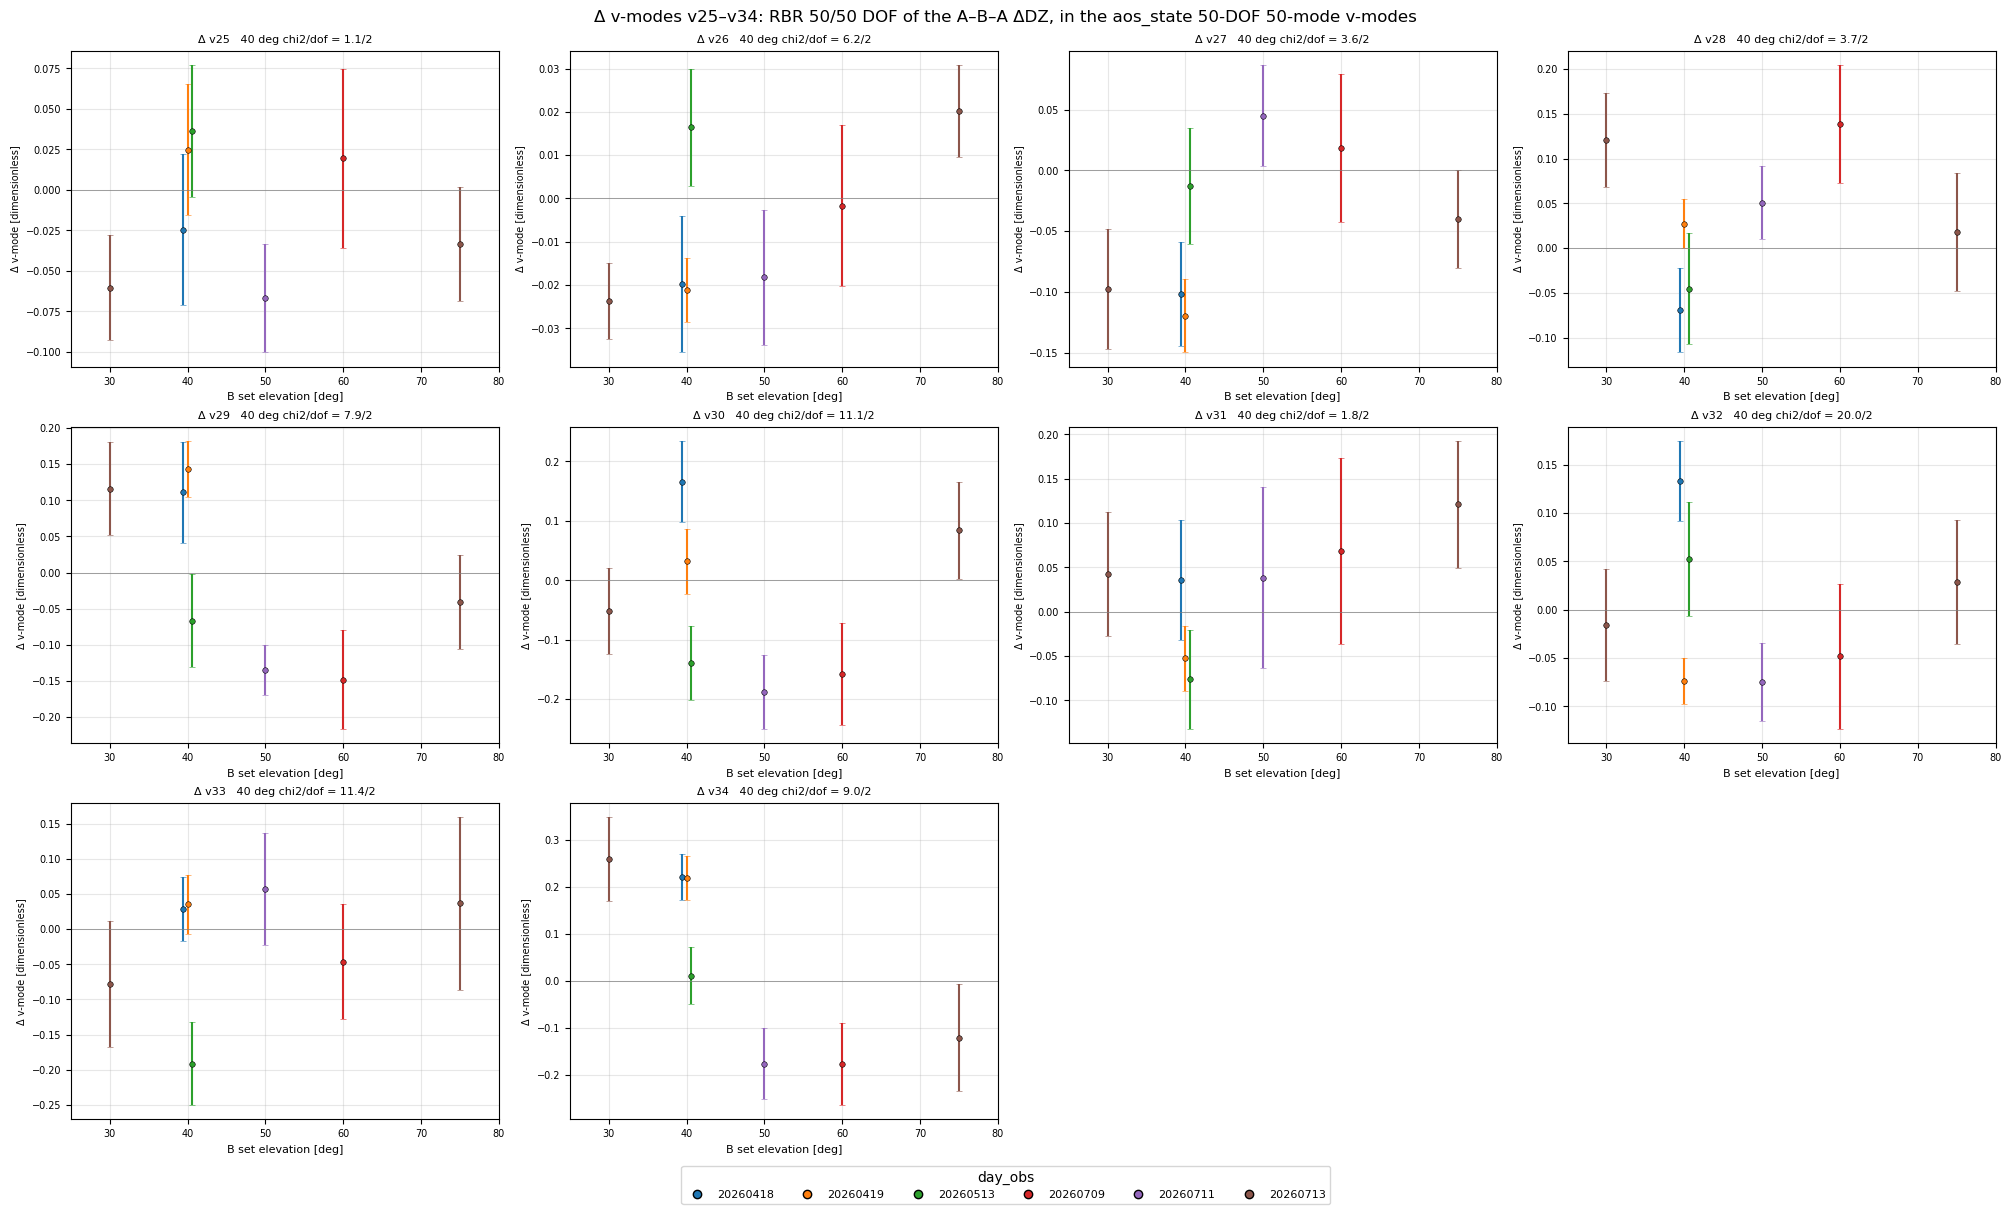

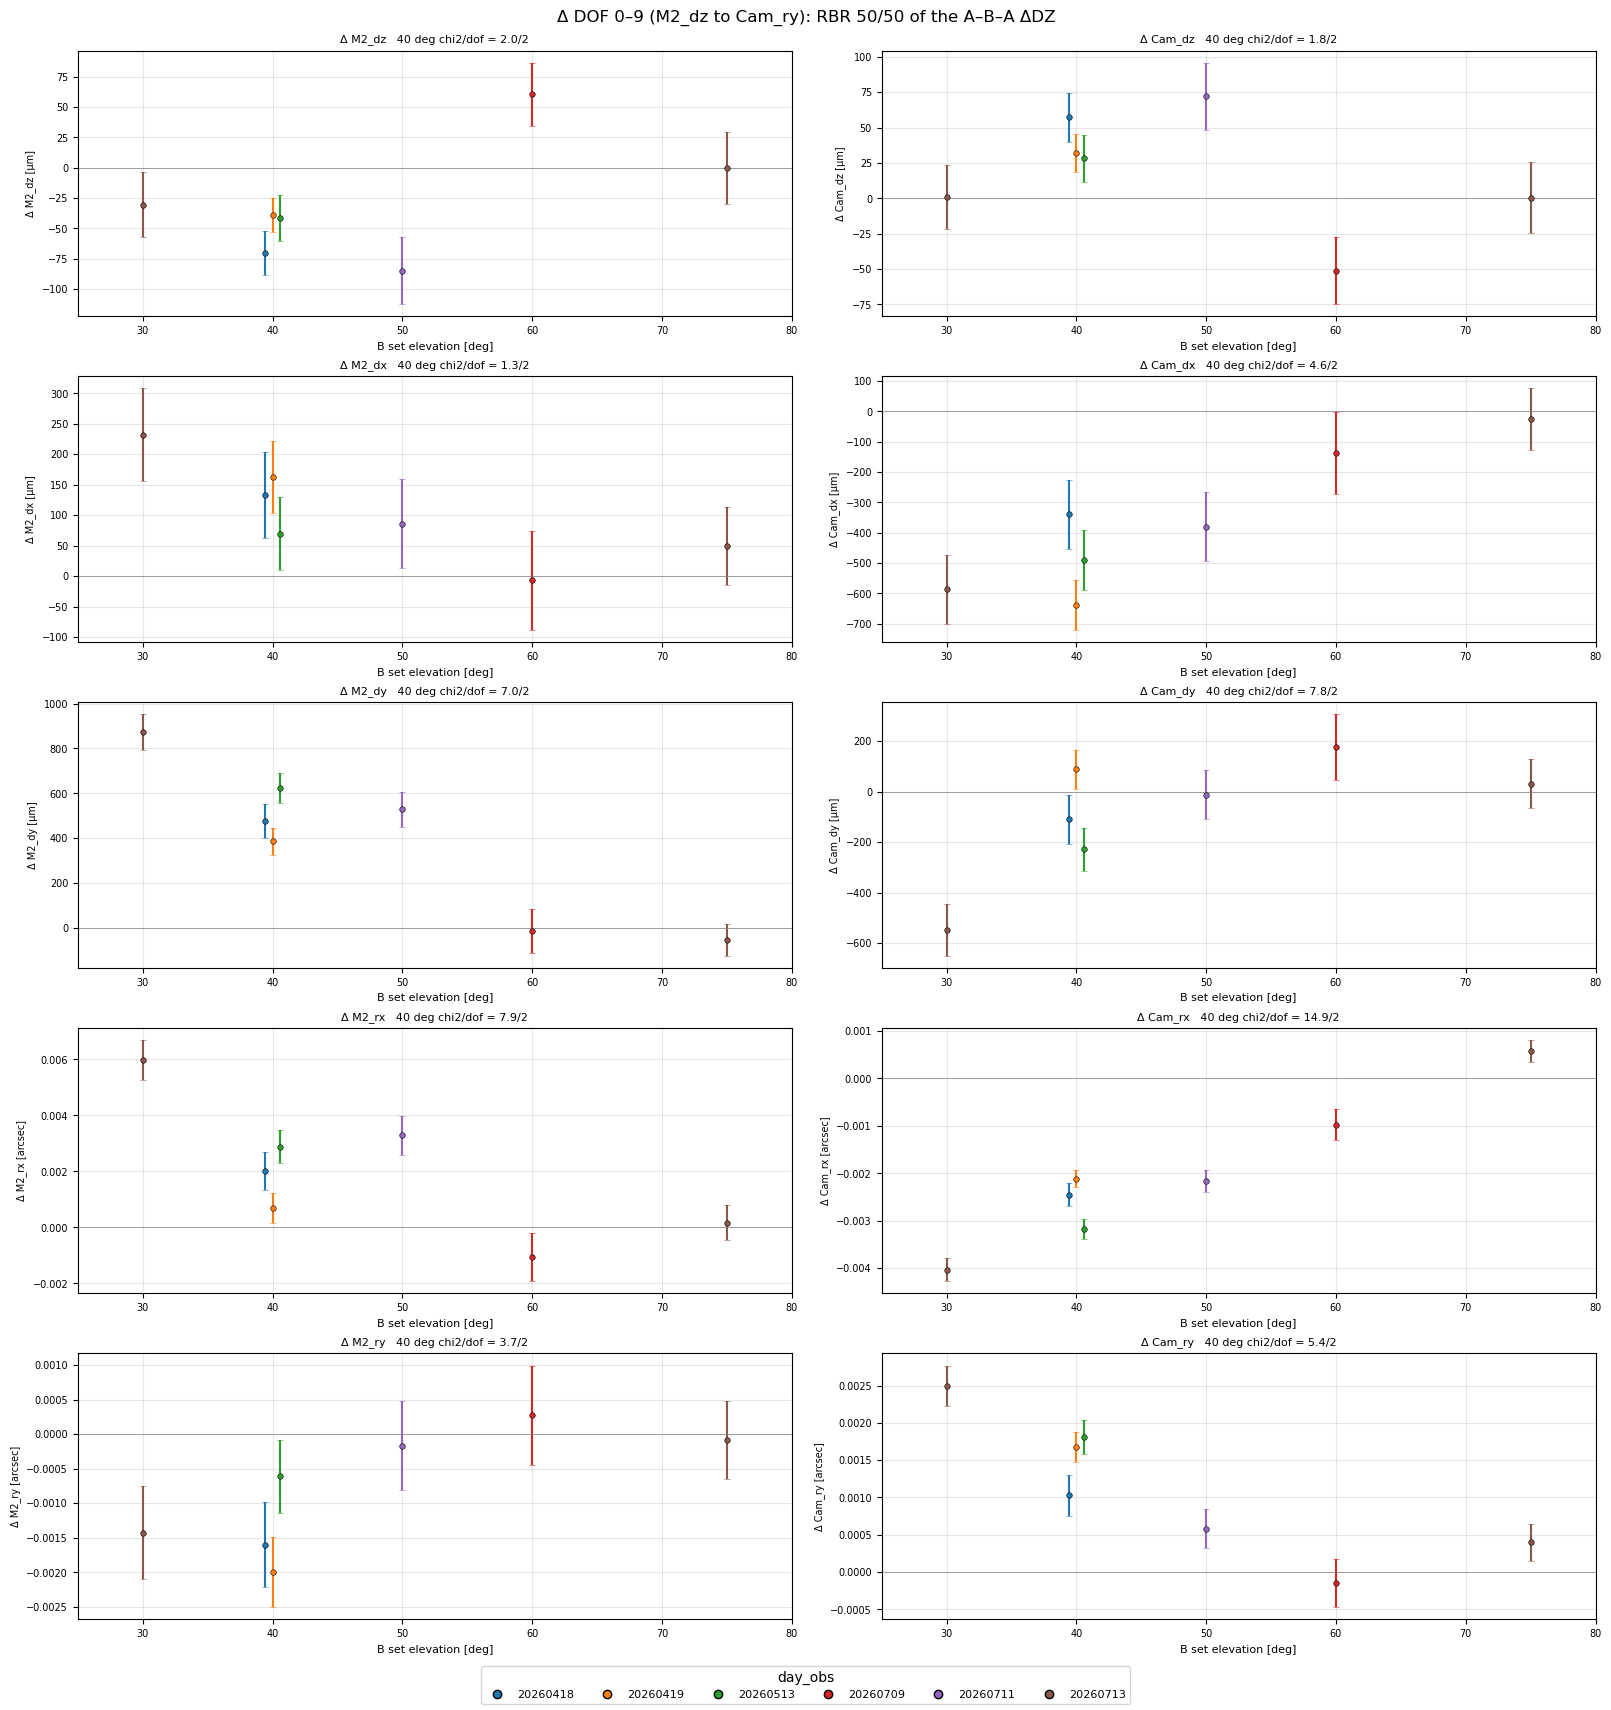

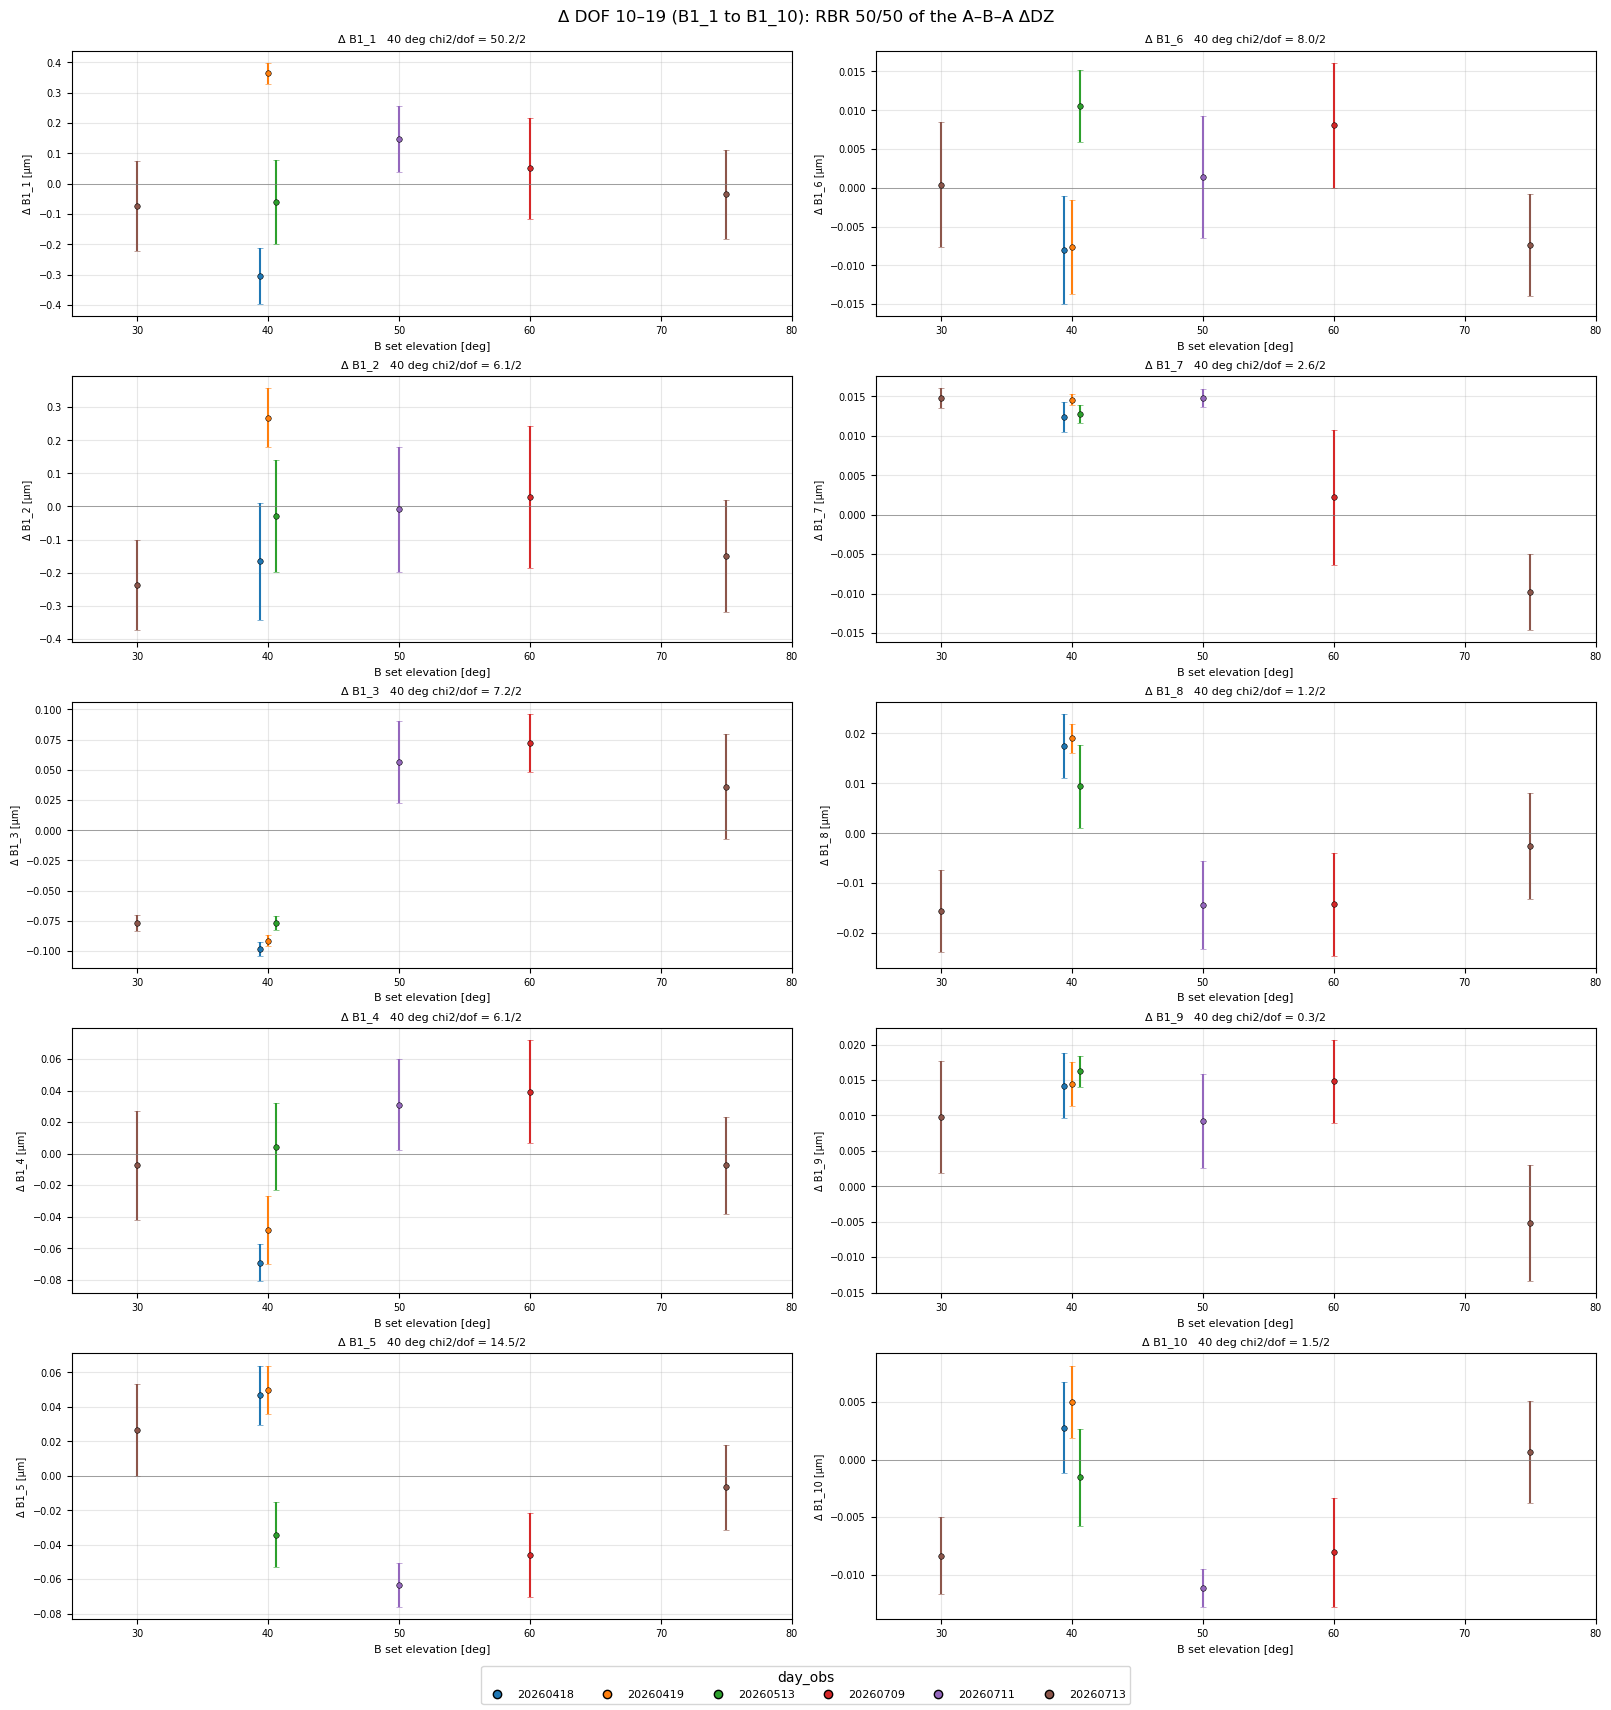

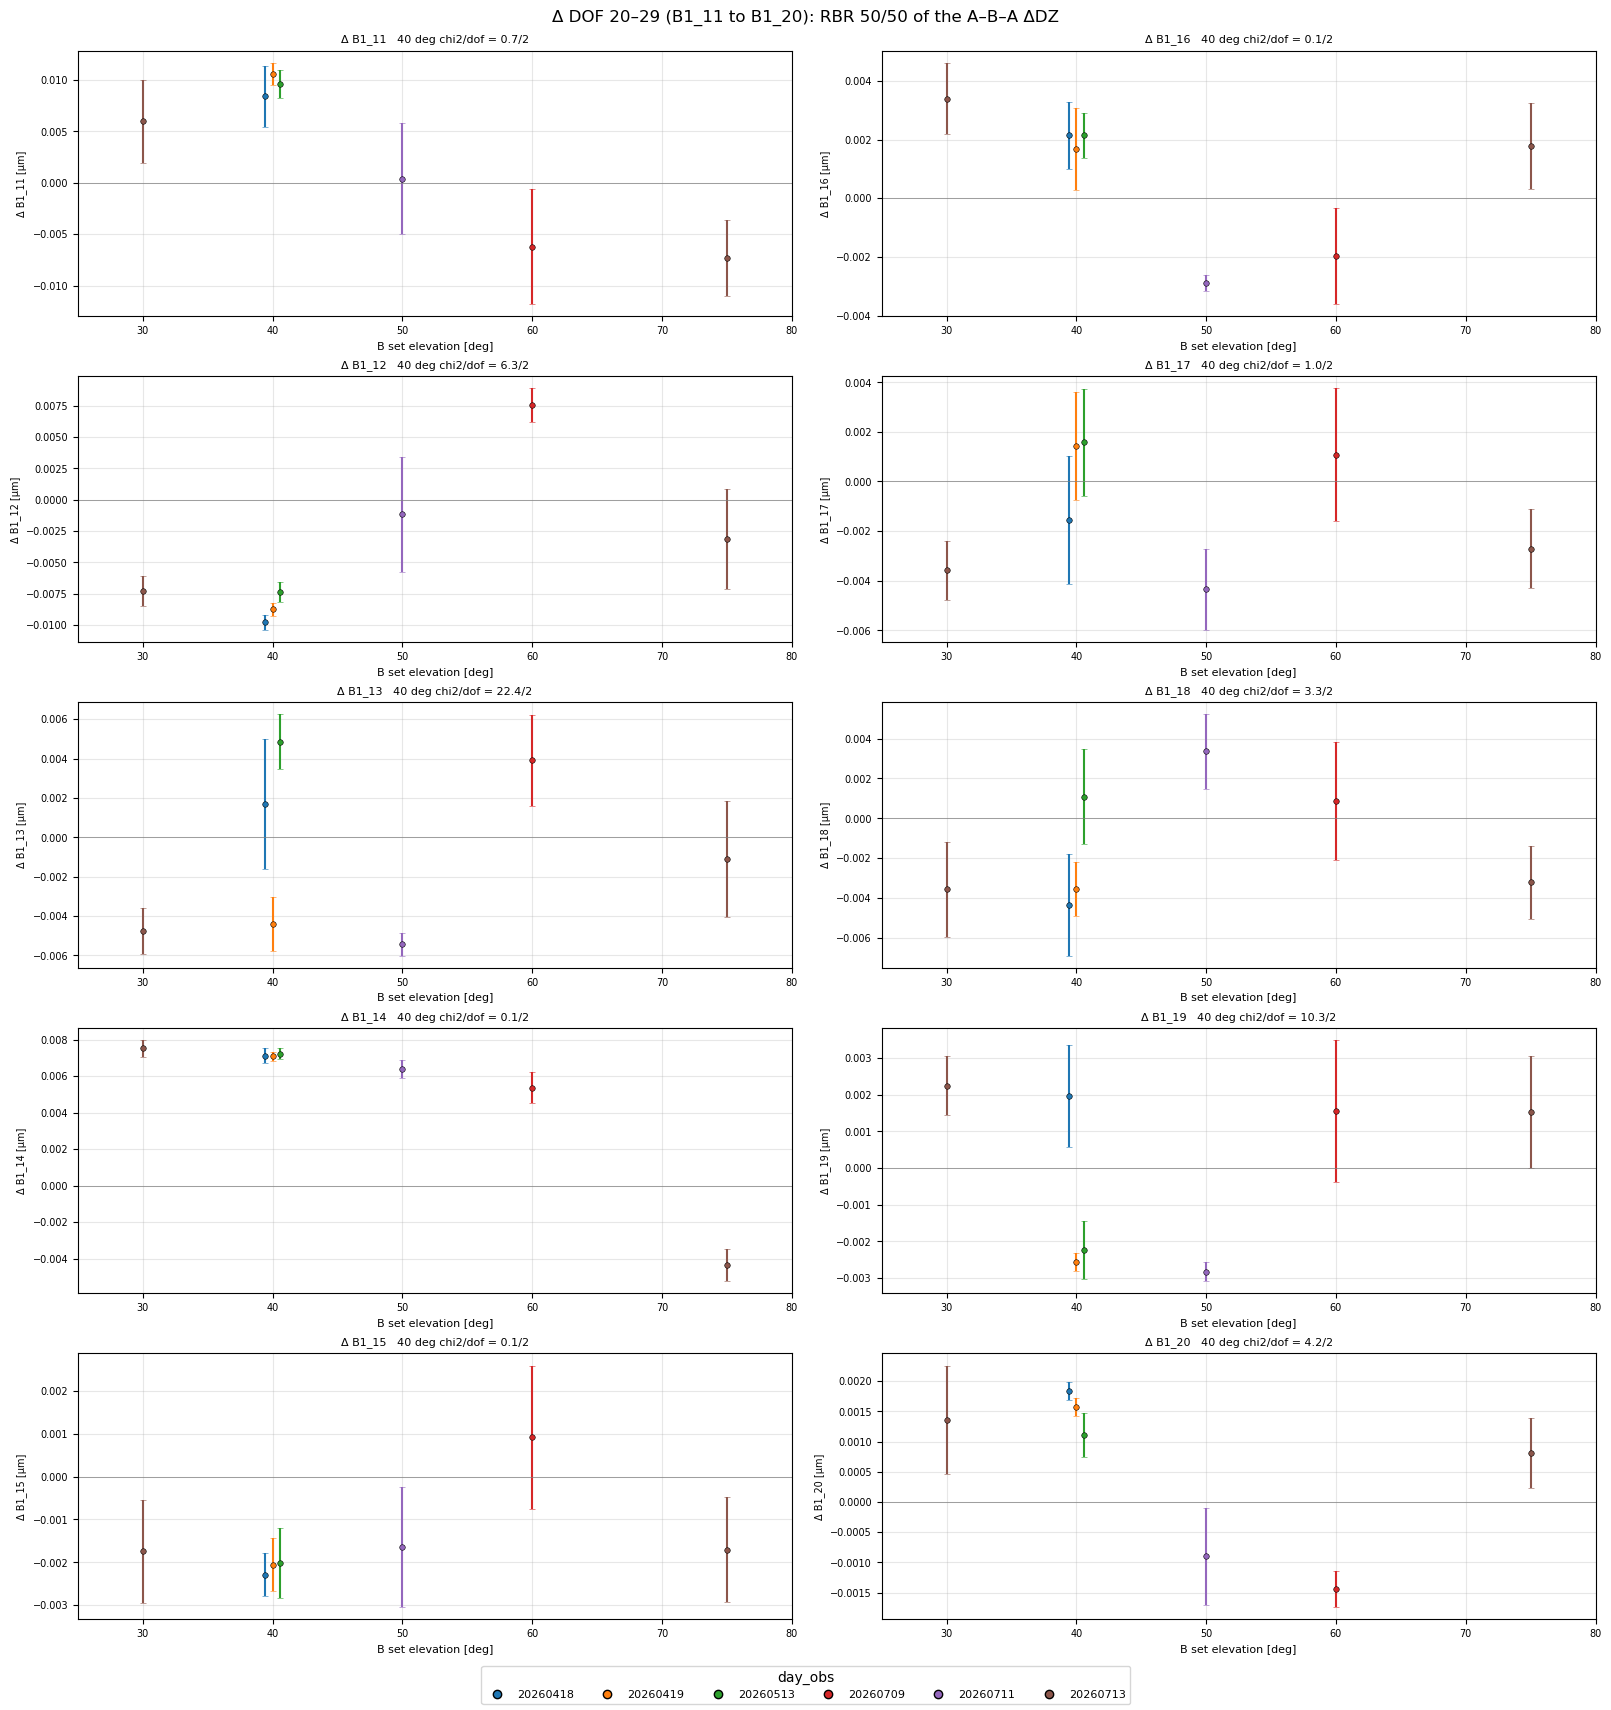

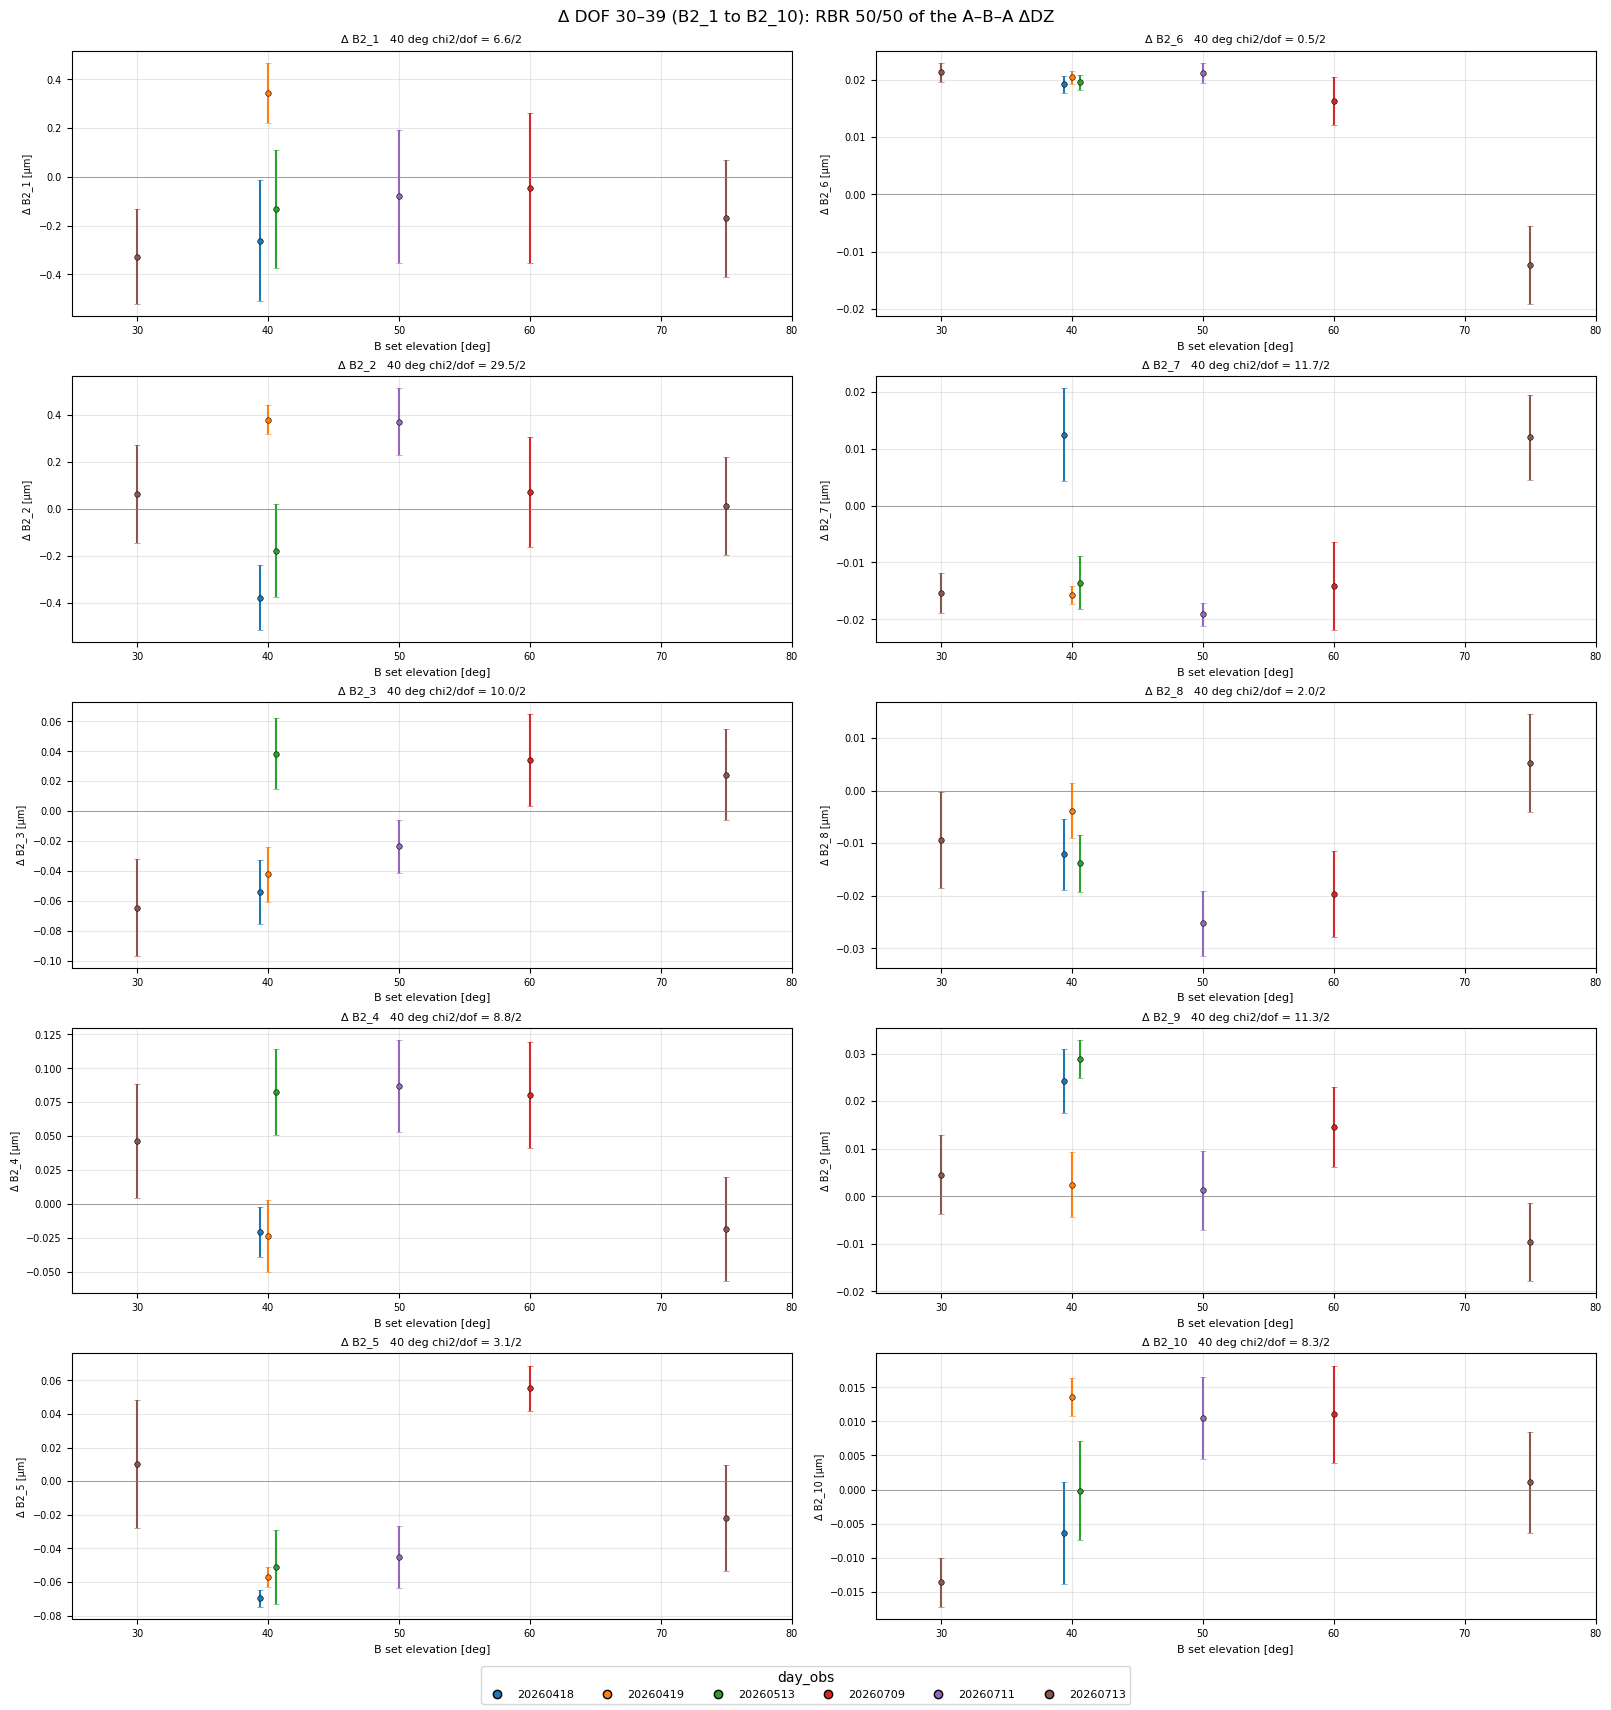

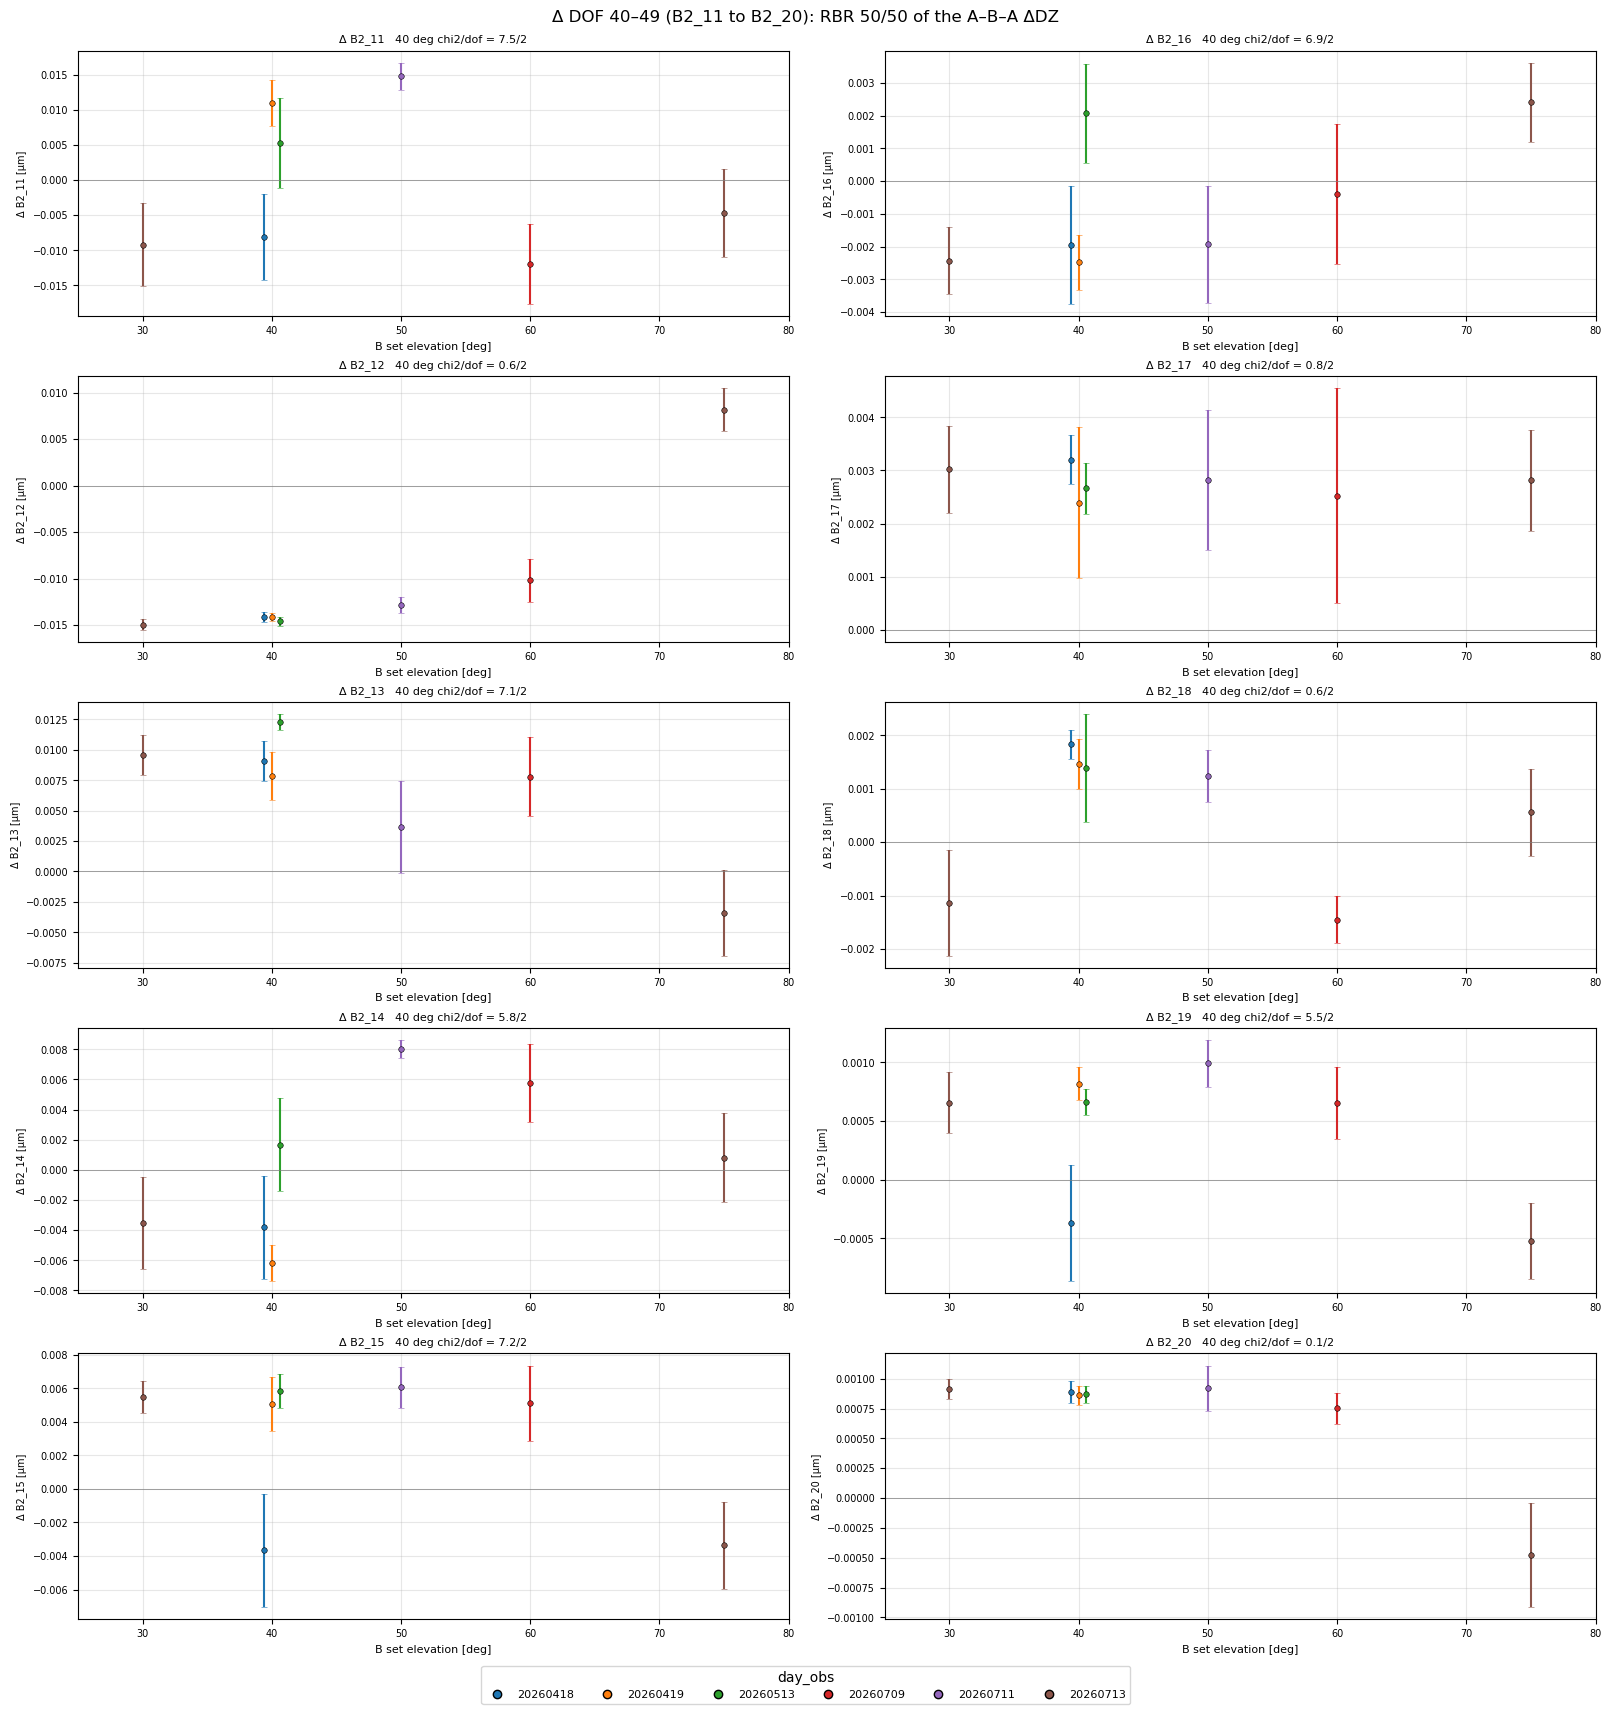

In [9]:
xoff = {n: o for n, o in zip([20260418, 20260419, 20260513], [-0.6, 0.0, 0.6])}


def chi2_40(vals, errs, bvals):
    m = bvals == 40.0
    x, e = vals[m], errs[m]
    if m.sum() < 2 or not np.all(e > 0):
        return np.nan
    w = 1 / e ** 2; mu = np.sum(w * x) / np.sum(w)
    return float(np.sum(w * (x - mu) ** 2))


bvals = np.array([L['b_value_deg'] for L in legs])


def panel(a_, getv, gete, title, ylabel):
    vals = np.array([getv(res[(L['night'], L['leg'])]) for L in legs])
    errs = np.array([gete(res[(L['night'], L['leg'])]) for L in legs])
    for L, y, e in zip(legs, vals, errs):
        a_.errorbar(L['b_value_deg'] + xoff.get(L['night'], 0.0), y, yerr=e, fmt='o', ms=4,
                    color=ncol[L['night']], mec='k', mew=0.4, capsize=2)
    a_.axhline(0, color='gray', lw=0.5); a_.grid(alpha=0.3)
    c2 = chi2_40(vals, errs, bvals)
    a_.set_title(f'{title}   40 deg chi2/dof = {c2:.1f}/2', fontsize=8)
    a_.set_ylabel(ylabel, fontsize=7); a_.tick_params(labelsize=7)
    a_.set_xlim(25, 80)


def legend_fig(fig):
    h = [plt.Line2D([], [], marker='o', ls='', color=ncol[n], mec='k', label=str(n)) for n in ncol]
    fig.legend(handles=h, loc='outside lower center', ncols=len(ncol), fontsize=8, title='day_obs')


ks = sorted({k for k, _ in KJ})
figs_dz = []
for p0 in range(0, len(iZs), J_PER_PAGE):
    js = iZs[p0:p0 + J_PER_PAGE]
    fig, axs = plt.subplots(len(js), len(ks), figsize=(22, 3.2 * len(js) + 1.2), layout='constrained',
                            squeeze=False)
    for ri, j in enumerate(js):
        for ci, k in enumerate(ks):
            ix = KJ.index((k, j))
            panel(axs[ri, ci], lambda r: r['dz'][ix], lambda r: r['dz_err'][ix], f'Δ DZ({k},{j})',
                  'Δ DZ [um of wavefront]')
            if ri == len(js) - 1:
                axs[ri, ci].set_xlabel('B set elevation [deg]', fontsize=8)
    fig.suptitle(f'A–B–A Δ DZ_kj vs 70 deg reference, j = {js[0]}..{js[-1]} (rows), k = 1..6 (columns)')
    legend_fig(fig); figs_dz.append(fig); plt.show()

figs_v = []
for p0 in range(0, N_VMODES_SHOW, VMODES_PER_PAGE):
    ms = list(range(p0, min(p0 + VMODES_PER_PAGE, N_VMODES_SHOW)))
    fig, axs = plt.subplots(3, 4, figsize=(20, 12), layout='constrained')
    for a_, m in zip(axs.flat, ms + [None] * (12 - len(ms))):
        if m is None:
            a_.set_visible(False); continue
        panel(a_, lambda r: r['v'][m], lambda r: r['v_err'][m], f'Δ v{m + 1}',
              'Δ v-mode [dimensionless]')
        a_.set_xlabel('B set elevation [deg]', fontsize=8)
    fig.suptitle(f'Δ v-modes v{ms[0] + 1}–v{ms[-1] + 1}: RBR 50/50 DOF of the A–B–A ΔDZ, '
                 'in the aos_state 50-DOF 50-mode v-modes')
    legend_fig(fig); figs_v.append(fig); plt.show()

figs_dof = []
for p0 in range(0, 50, DOF_PER_PAGE):
    fig, axs = plt.subplots(5, 2, figsize=(16, 17), layout='constrained')
    for a_, i in zip(axs.T.flat, range(p0, p0 + DOF_PER_PAGE)):
        panel(a_, lambda r: r['dof'][i], lambda r: r['dof_err'][i], f'Δ {LABELS_50DOF[i]}',
              f'Δ {LABELS_50DOF[i]} [{DOF_UNITS_50[i]}]')
        a_.set_xlabel('B set elevation [deg]', fontsize=8)
    fig.suptitle(f'Δ DOF {p0}–{p0 + DOF_PER_PAGE - 1} ({LABELS_50DOF[p0]} to {LABELS_50DOF[p0 + DOF_PER_PAGE - 1]}): '
                 'RBR 50/50 of the A–B–A ΔDZ')
    legend_fig(fig); figs_dof.append(fig); plt.show()

## Errors: v2 against v1

The ratio of each error to the v1 (shared-ALPHA) error, per (night, leg).

median err_v2 / err_v1 (dimensionless) by kind:
       count  mean   std   min   10%   50%   90%   max
kind                                                  
DOF    350.0  0.95  0.13  0.66  0.81  0.94  1.12  1.45
DZ     882.0  0.90  0.12  0.64  0.75  0.89  1.06  1.26
vmode  238.0  0.94  0.14  0.69  0.76  0.91  1.12  1.39


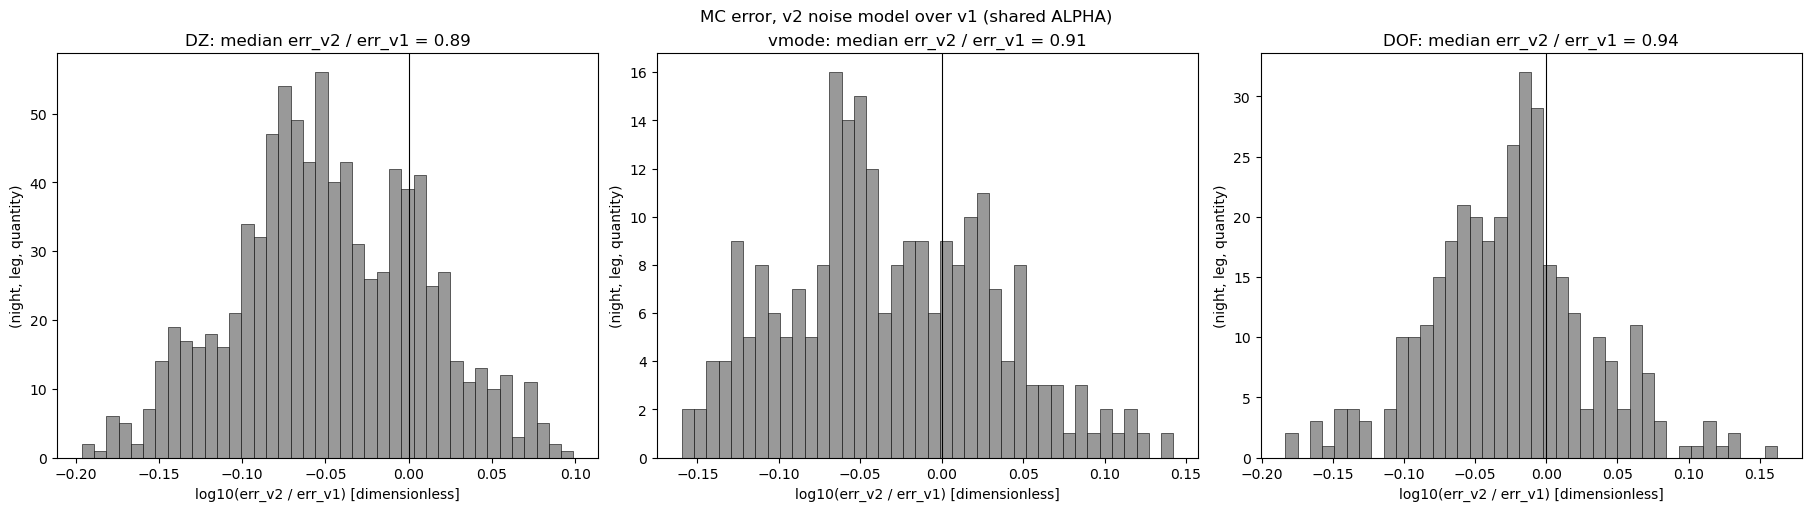

err_v1          err_v2        
name             DZ(1,4)      v1 DZ(1,4)      v1
night    leg                                    
20260418 Elev=40  0.0261  0.0018  0.0308  0.0020
20260419 Elev=40  0.0212  0.0014  0.0233  0.0016
20260513 Elev=40  0.0238  0.0016  0.0272  0.0018
20260709 Elev=60  0.0340  0.0022  0.0399  0.0026
20260711 Elev=50  0.0266  0.0018  0.0306  0.0020
20260713 Elev=30  0.0273  0.0019  0.0314  0.0020
         Elev=75  0.0231  0.0015  0.0275  0.0018

In [10]:
v1t = pd.read_csv(run.path.parent / V1_RUN / 'bounce_aba_optical_state.csv')
v1e = v1t.set_index(['night', 'leg', 'name']).err
cmp_rows = []
for L in legs:
    r = res[(L['night'], L['leg'])]
    names = ([(f'DZ({k},{j})', 'DZ', r['dz_err'][a]) for a, (k, j) in enumerate(KJ)]
             + [(f'v{m + 1}', 'vmode', r['v_err'][m]) for m in range(N_VMODES_SHOW)]
             + [(LABELS_50DOF[i], 'DOF', r['dof_err'][i]) for i in range(50)])
    for nm, kind, e in names:
        cmp_rows.append({'night': L['night'], 'leg': L['leg'], 'kind': kind, 'name': nm,
                         'err_v2': e, 'err_v1': v1e[(L['night'], L['leg'], nm)]})
cmp = pd.DataFrame(cmp_rows); cmp['ratio'] = cmp.err_v2 / cmp.err_v1
print('median err_v2 / err_v1 (dimensionless) by kind:')
print(cmp.groupby('kind').ratio.describe(percentiles=[0.1, 0.5, 0.9]).round(2))
fig_cmp, ax = plt.subplots(1, 3, figsize=(18, 5), layout='constrained')
for a_, kind in zip(ax, ['DZ', 'vmode', 'DOF']):
    m = cmp.kind == kind
    a_.hist(np.log10(cmp[m].ratio), bins=40, color='0.6', ec='k', lw=0.4)
    a_.axvline(0, color='k', lw=0.8)
    a_.set_xlabel('log10(err_v2 / err_v1) [dimensionless]'); a_.set_ylabel('(night, leg, quantity)')
    a_.set_title(f'{kind}: median err_v2 / err_v1 = {cmp[m].ratio.median():.2f}')
fig_cmp.suptitle('MC error, v2 noise model over v1 (shared ALPHA)')
plt.show()
key_cmp = cmp[cmp.name.isin(['DZ(1,4)', 'v1'])].pivot(index=['night', 'leg'], columns='name',
                                                       values=['err_v1', 'err_v2'])
key_cmp.round(4)

<a id='resid'></a>
## DZ after the RBR correction

The fitted DZ of a leg is `S · ΔDOF`, with S from `estimator.forward_operator()`
(µm of wavefront per µm or arcsec of DOF, all 50 modes kept). The residual is
`ΔDZ − S · ΔDOF`. RBR has a range barrier, so the fit is not the plain
projection: a residual can be left in terms the DOF could reach.

Errors come from the same MC draws: per draw, `(ΔDZ + δ) − S · RBR(ΔDZ + δ)`.

The fitted DZ(1,4) is a sum over DOF, `S[(1,4), i] ΔDOF_i`. It is also a sum
over v-modes, `Δv_m G_m`, with `G = T_V^-1 S[(1,4), :]`.

In [11]:
F = svd.estimator.forward_operator()                  # (kj, DOF) um of wavefront per DOF unit
r0 = res[(legs[0]['night'], legs[0]['leg'])]
print(f'max |S·ΔDOF − wavefront_from_dof(ΔDOF)| = '
      f'{np.abs(F @ r0["dof"] - svd.estimator.wavefront_from_dof(r0["dof"])).max():.2e} um')
G14 = np.linalg.solve(T_V, F[i14])                    # DZ(1,4) per unit v-mode, um
FOCUS = [('M2_dz', 0), ('Cam_dz', 5), ('B1_3', 12), ('B2_5', 34)]
for r in res.values():
    fit_mc = r['dof_mc'] @ F.T
    resid_mc = r['dz'] + r['dz_mc'] - fit_mc
    r['fit'] = F @ r['dof']; r['resid'] = r['dz'] - r['fit']
    r['fit_err'] = fit_mc.std(0, ddof=1); r['resid_err'] = resid_mc.std(0, ddof=1)
    r['c14'] = F[i14] * r['dof']; c14_mc = r['dof_mc'] * F[i14]
    r['c14_err'] = c14_mc.std(0, ddof=1)
    oth = np.ones(50, bool); oth[[i for _, i in FOCUS]] = False
    r['c14_oth'] = r['c14'][oth].sum(); r['c14_oth_err'] = c14_mc[:, oth].sum(1).std(ddof=1)
    r['c14_hex'] = r['c14'][[0, 5]].sum(); r['c14_hex_err'] = c14_mc[:, [0, 5]].sum(1).std(ddof=1)
    vm_mc = r['dof_mc'] @ T_V
    r['cv14'] = r['v'] * G14; cv_mc = vm_mc * G14
    r['cv14_err'] = cv_mc.std(0, ddof=1)
    r['cv14_rest'] = r['cv14'][1:].sum(); r['cv14_rest_err'] = cv_mc[:, 1:].sum(1).std(ddof=1)
rows = []
for L in legs:
    r = res[(L['night'], L['leg'])]
    rows.append({'night': L['night'], 'leg': L['leg'], 'dDZ14_um': r['dz'][i14], 'fit_um': r['fit'][i14],
                 'resid_um': r['resid'][i14], 'resid_err_um': r['resid_err'][i14],
                 **{f'{n}_um': r['c14'][i] for n, i in FOCUS}, 'other46_um': r['c14_oth'],
                 'v1_part_um': r['cv14'][0], 'v2_50_part_um': r['cv14_rest']})
dz14 = pd.DataFrame(rows)
print('DZ(1,4) per leg: measured, fitted, residual, and the fitted part from each DOF and v-mode [um]')
dz14.round(4)

max |S·ΔDOF − wavefront_from_dof(ΔDOF)| = 2.36e-16 um
DZ(1,4) per leg: measured, fitted, residual, and the fitted part from each DOF and v-mode [um]


,night,leg,dDZ14_um,fit_um,resid_um,resid_err_um,M2_dz_um,Cam_dz_um,B1_3_um,B2_5_um,other46_um,v1_part_um,v2_50_part_um
0,20260418,Elev=40,-0.0682,-0.0680,-0.0002,0.0001,1.0784,-0.9083,-0.1400,-0.1022,0.0042,-0.1302,0.0622
1,20260419,Elev=40,-0.1219,-0.1218,-0.0001,0.0001,0.5975,-0.5070,-0.1301,-0.0834,0.0012,-0.1969,0.0750
2,20260513,Elev=40,0.0086,0.0086,0.0000,0.0001,0.6349,-0.4474,-0.1092,-0.0748,0.0051,-0.0522,0.0608
3,20260709,Elev=60,0.0703,0.0702,0.0001,0.0001,-0.9278,0.8153,0.1027,0.0810,-0.0010,0.1108,-0.0406
4,20260711,Elev=50,0.1751,0.1752,-0.0001,0.0000,1.3031,-1.1458,0.0810,-0.0659,0.0027,0.2468,-0.0717
5,20260713,Elev=30,0.3660,0.3660,0.0001,0.0002,0.4676,-0.0131,-0.1095,0.0150,0.0060,0.3396,0.0263
6,20260713,Elev=75,0.0146,0.0146,-0.0000,0.0000,0.0013,-0.0074,0.0511,-0.0320,0.0016,0.0194,-0.0047


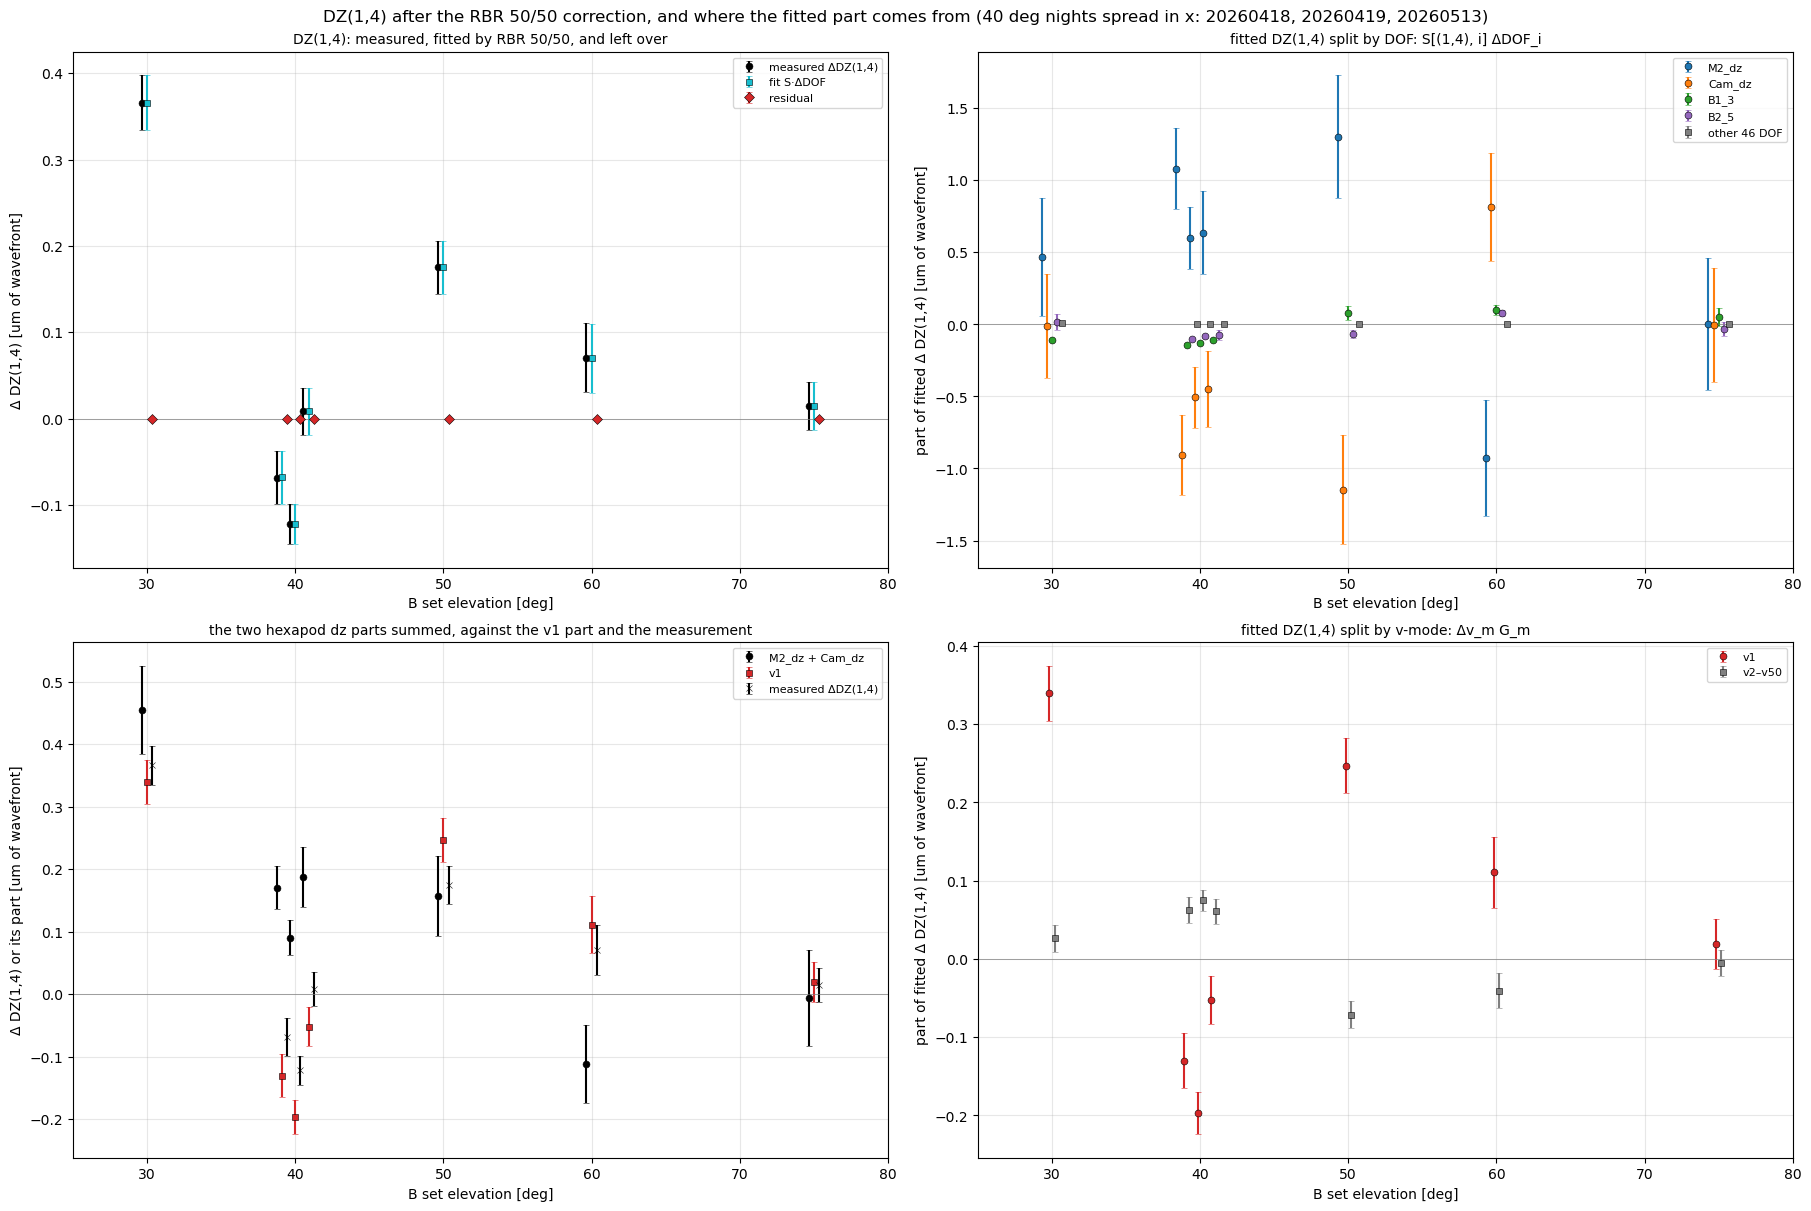

In [12]:
S_COL = {'M2_dz': 'tab:blue', 'Cam_dz': 'tab:orange', 'B1_3': 'tab:green', 'B2_5': 'tab:purple',
         'other 46 DOF': '0.5', 'M2_dz + Cam_dz': 'k', 'v1': 'tab:red', 'v2–v50': '0.5'}


def series(a_, items, title):
    n = len(items)
    for si, (lab, getv, gete, mk) in enumerate(items):
        for L in legs:
            r = res[(L['night'], L['leg'])]
            x = L['b_value_deg'] + xoff.get(L['night'], 0.0) * 1.5 + (si - (n - 1) / 2) * 0.35
            a_.errorbar(x, getv(r), yerr=gete(r), fmt=mk, ms=5, color=S_COL.get(lab, 'k'),
                        mec='k', mew=0.4, capsize=2, label=lab if L is legs[0] else None)
    a_.axhline(0, color='gray', lw=0.5); a_.grid(alpha=0.3); a_.set_xlim(25, 80)
    a_.set_xlabel('B set elevation [deg]'); a_.set_title(title, fontsize=10); a_.legend(fontsize=8)


S_COL.update({'measured ΔDZ(1,4)': 'k', 'fit S·ΔDOF': 'tab:cyan', 'residual': 'tab:red'})
fig_focus, ax = plt.subplots(2, 2, figsize=(18, 12), layout='constrained')
series(ax[0, 0], [('measured ΔDZ(1,4)', lambda r: r['dz'][i14], lambda r: r['dz_err'][i14], 'o'),
                  ('fit S·ΔDOF', lambda r: r['fit'][i14], lambda r: r['fit_err'][i14], 's'),
                  ('residual', lambda r: r['resid'][i14], lambda r: r['resid_err'][i14], 'D')],
       'DZ(1,4): measured, fitted by RBR 50/50, and left over')
ax[0, 0].set_ylabel('Δ DZ(1,4) [um of wavefront]')
series(ax[0, 1], [(n, (lambda r, i=i: r['c14'][i]), (lambda r, i=i: r['c14_err'][i]), 'o') for n, i in FOCUS]
       + [('other 46 DOF', lambda r: r['c14_oth'], lambda r: r['c14_oth_err'], 's')],
       'fitted DZ(1,4) split by DOF: S[(1,4), i] ΔDOF_i')
ax[0, 1].set_ylabel('part of fitted Δ DZ(1,4) [um of wavefront]')
series(ax[1, 0], [('M2_dz + Cam_dz', lambda r: r['c14_hex'], lambda r: r['c14_hex_err'], 'o'),
                  ('v1', lambda r: r['cv14'][0], lambda r: r['cv14_err'][0], 's'),
                  ('measured ΔDZ(1,4)', lambda r: r['dz'][i14], lambda r: r['dz_err'][i14], 'x')],
       'the two hexapod dz parts summed, against the v1 part and the measurement')
ax[1, 0].set_ylabel('Δ DZ(1,4) or its part [um of wavefront]')
series(ax[1, 1], [('v1', lambda r: r['cv14'][0], lambda r: r['cv14_err'][0], 'o'),
                  ('v2–v50', lambda r: r['cv14_rest'], lambda r: r['cv14_rest_err'], 's')],
       'fitted DZ(1,4) split by v-mode: Δv_m G_m')
ax[1, 1].set_ylabel('part of fitted Δ DZ(1,4) [um of wavefront]')
fig_focus.suptitle('DZ(1,4) after the RBR 50/50 correction, and where the fitted part comes from '
                   '(40 deg nights spread in x: 20260418, 20260419, 20260513)')
plt.show()

DZ(1,4): residual power fraction = 0.000 (dimensionless; residual^2 over ΔDZ^2 summed over legs); residual chi2/dof = 13.5/7
largest residual chi2/dof (dof = 7): [('DZ(6, 19)', np.float64(1222.2)), ('DZ(5, 16)', np.float64(608.5)), ('DZ(3, 24)', np.float64(309.1)), ('DZ(3, 22)', np.float64(276.5)), ('DZ(4, 17)', np.float64(254.1)), ('DZ(3, 14)', np.float64(240.1)), ('DZ(3, 11)', np.float64(220.1)), ('DZ(6, 17)', np.float64(209.0)), ('DZ(3, 26)', np.float64(142.5)), ('DZ(5, 5)', np.float64(118.1))]


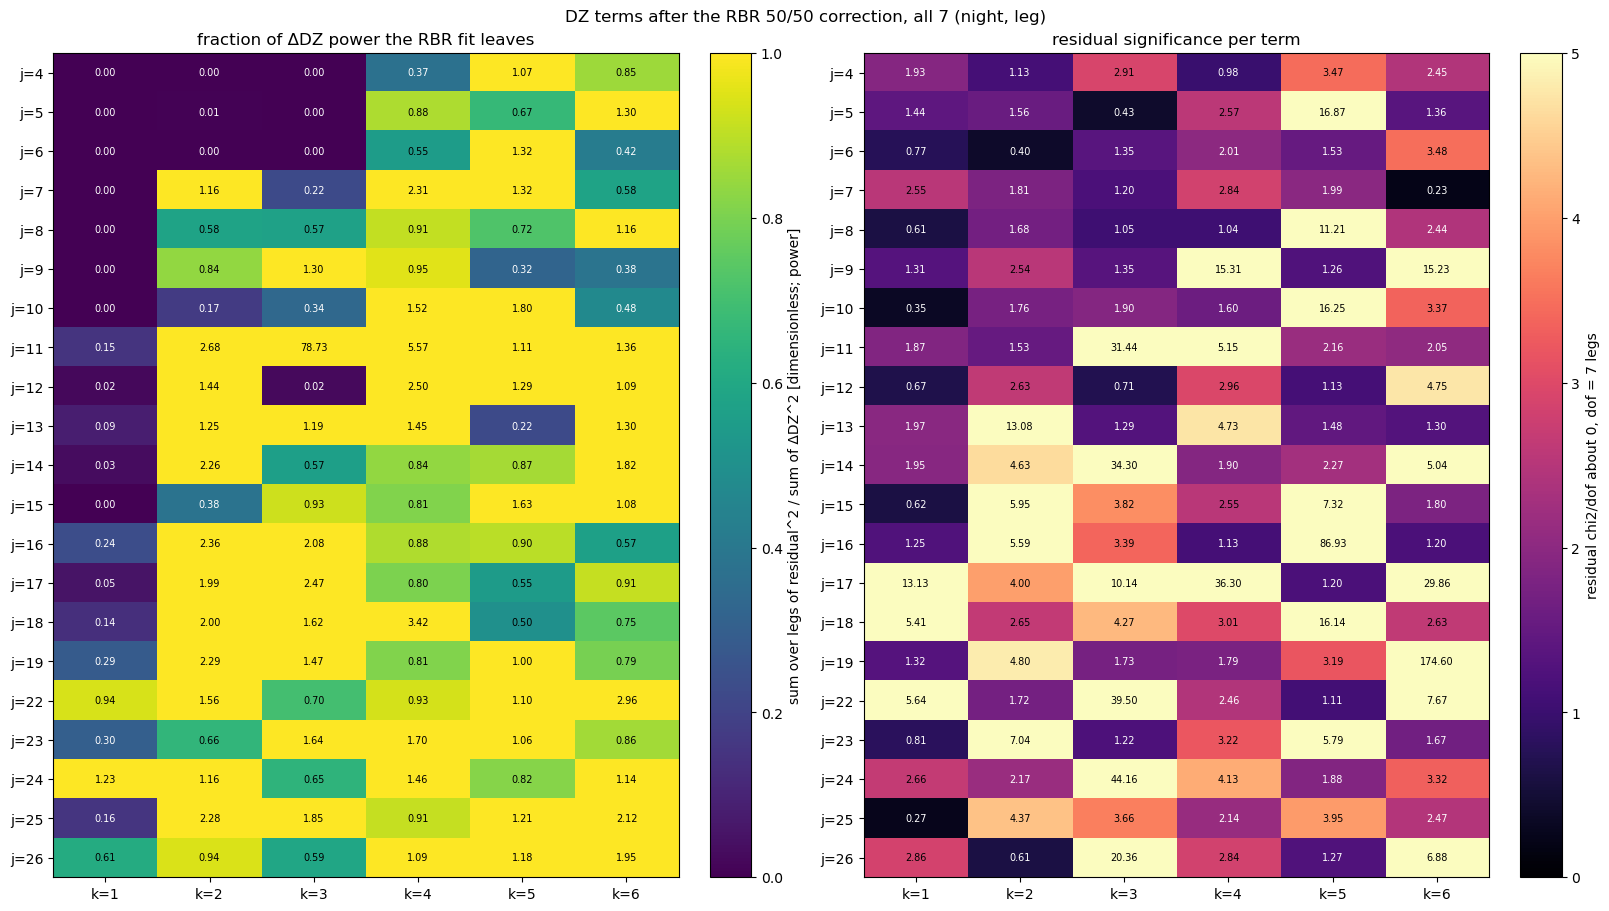

In [13]:
rs = np.array([res[(L['night'], L['leg'])]['resid'] for L in legs])
re_ = np.array([res[(L['night'], L['leg'])]['resid_err'] for L in legs])
dzs = np.array([res[(L['night'], L['leg'])]['dz'] for L in legs])
pfrac = (rs ** 2).sum(0) / (dzs ** 2).sum(0)
c2r = ((rs / re_) ** 2).sum(0)
grid = lambda q: np.array([[q[KJ.index((k, j))] for k in ks] for j in iZs])
fig_rsum, ax = plt.subplots(1, 2, figsize=(16, 9), layout='constrained')
for a_, q, lab, kw in [(ax[0], pfrac, 'sum over legs of residual^2 / sum of ΔDZ^2 [dimensionless; power]',
                        dict(vmin=0, vmax=1, cmap='viridis')),
                       (ax[1], c2r / len(legs), f'residual chi2/dof about 0, dof = {len(legs)} legs',
                        dict(vmin=0, vmax=5, cmap='magma'))]:
    im = a_.imshow(grid(q), aspect='auto', **kw)
    a_.set_xticks(range(len(ks)), [f'k={k}' for k in ks]); a_.set_yticks(range(len(iZs)), [f'j={j}' for j in iZs])
    for (yi, xi), val in np.ndenumerate(grid(q)):
        a_.text(xi, yi, f'{val:.2f}', ha='center', va='center', fontsize=7, color='w' if val < 0.5 * kw['vmax'] else 'k')
    fig_rsum.colorbar(im, ax=a_, label=lab)
ax[0].set_title('fraction of ΔDZ power the RBR fit leaves')
ax[1].set_title('residual significance per term')
fig_rsum.suptitle('DZ terms after the RBR 50/50 correction, all 7 (night, leg)')
print(f'DZ(1,4): residual power fraction = {pfrac[i14]:.3f} (dimensionless; residual^2 over ΔDZ^2 summed over legs); '
      f'residual chi2/dof = {c2r[i14]:.1f}/{len(legs)}')
order = np.argsort(-c2r)[:10]
print('largest residual chi2/dof (dof = 7):', [(f'DZ{KJ[a]}', round(c2r[a], 1)) for a in order])
plt.show()

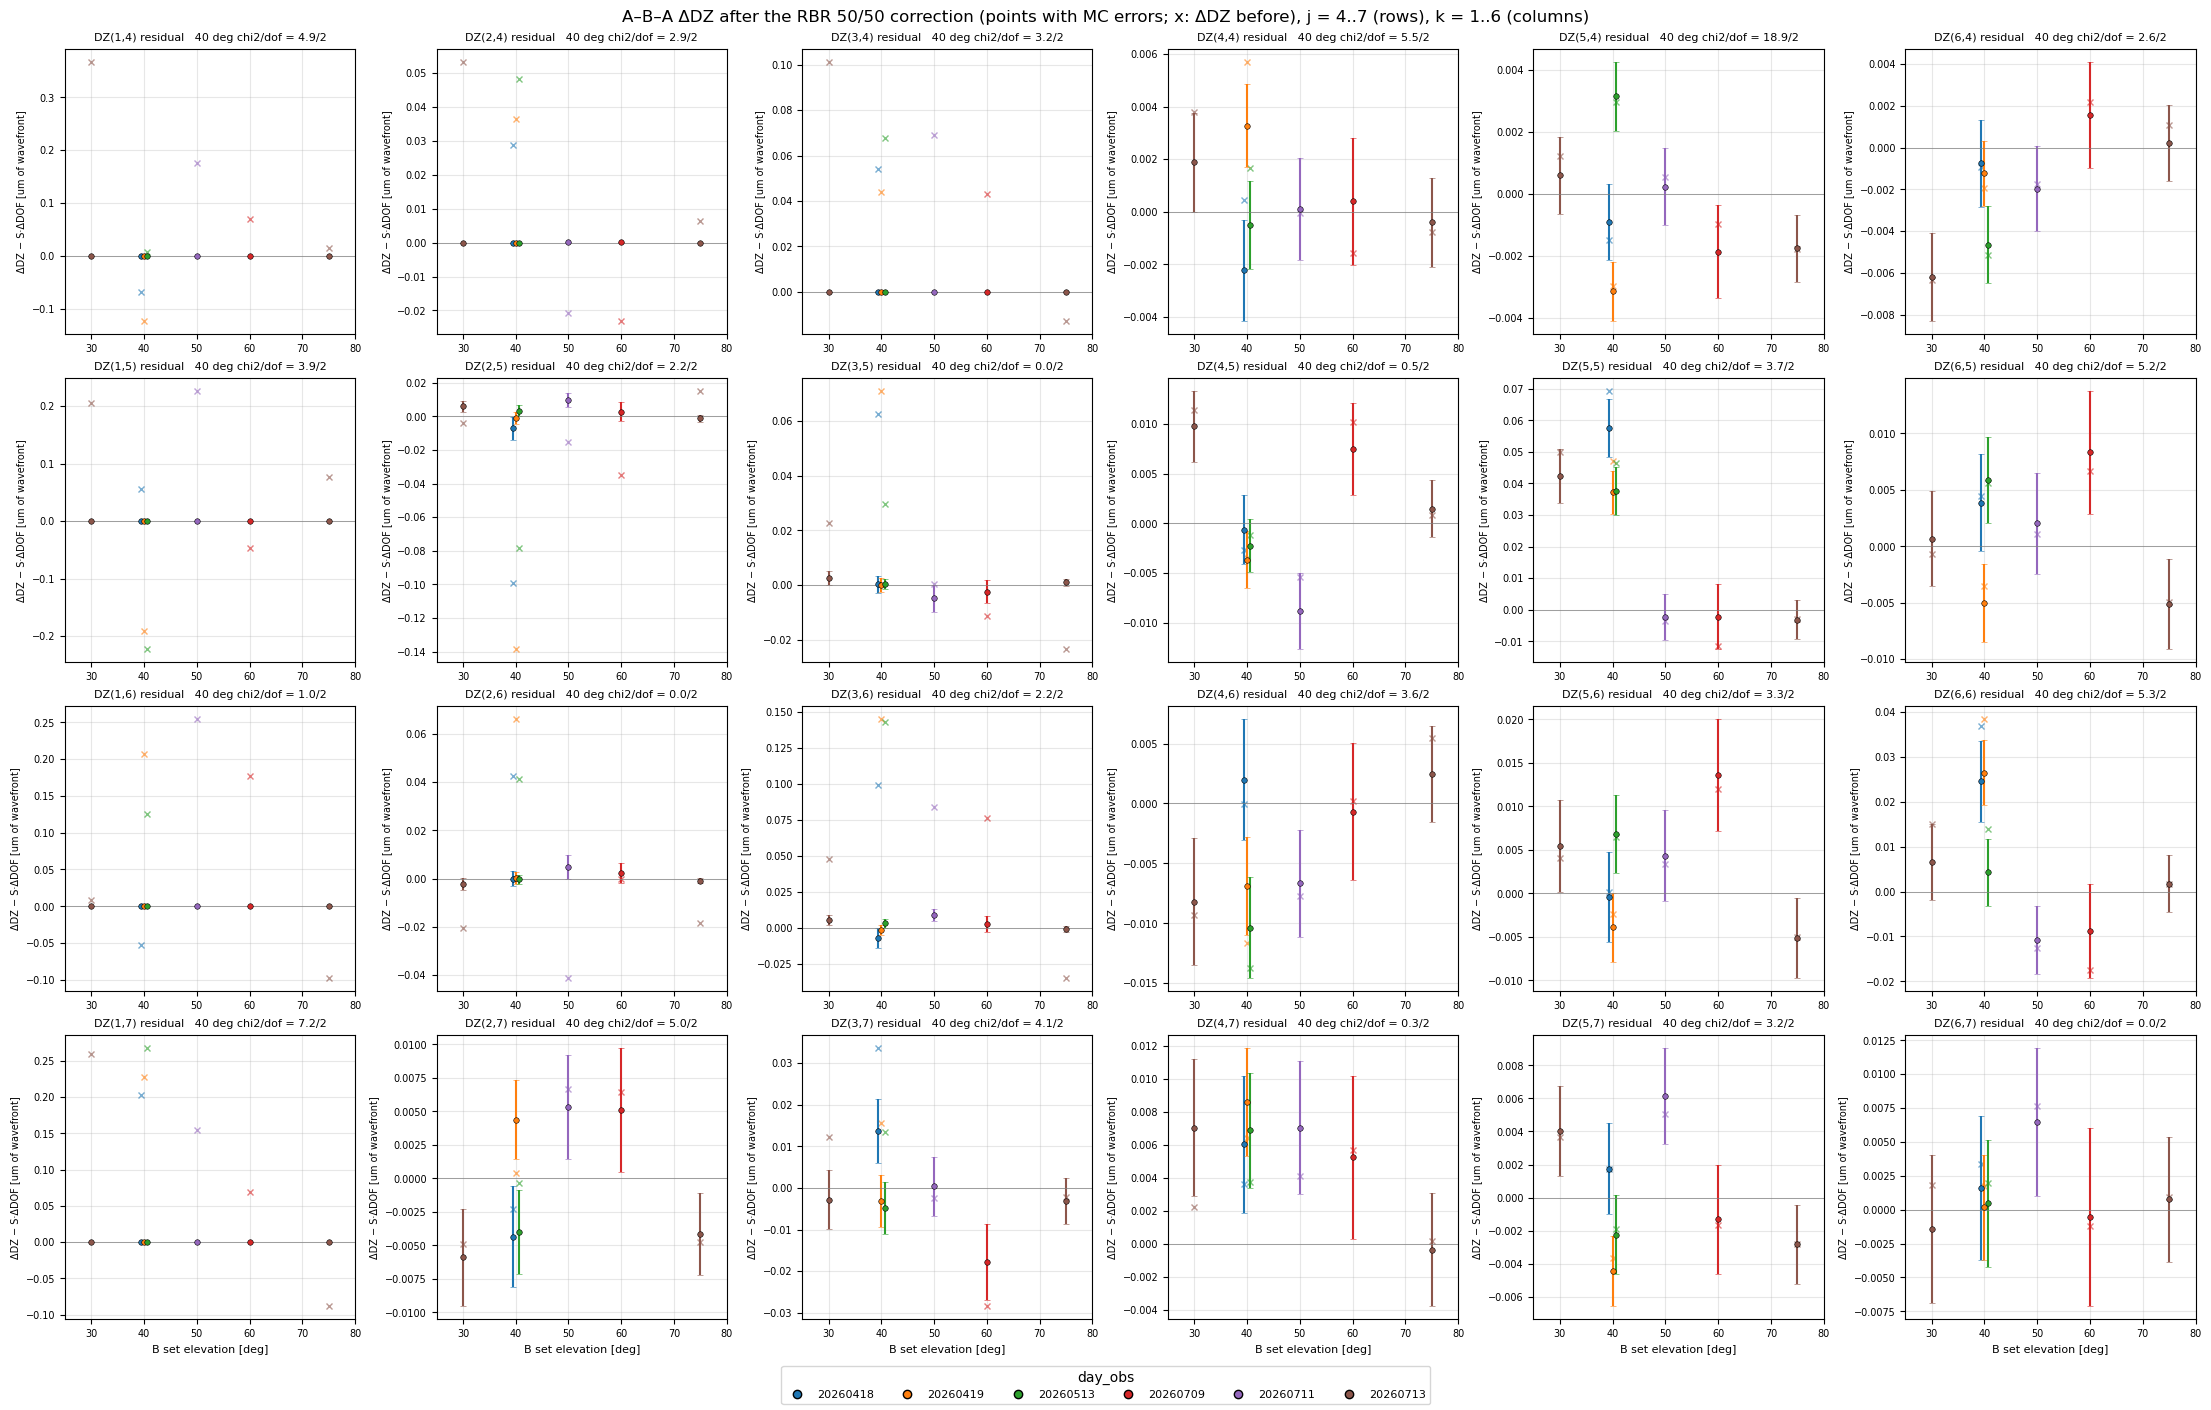

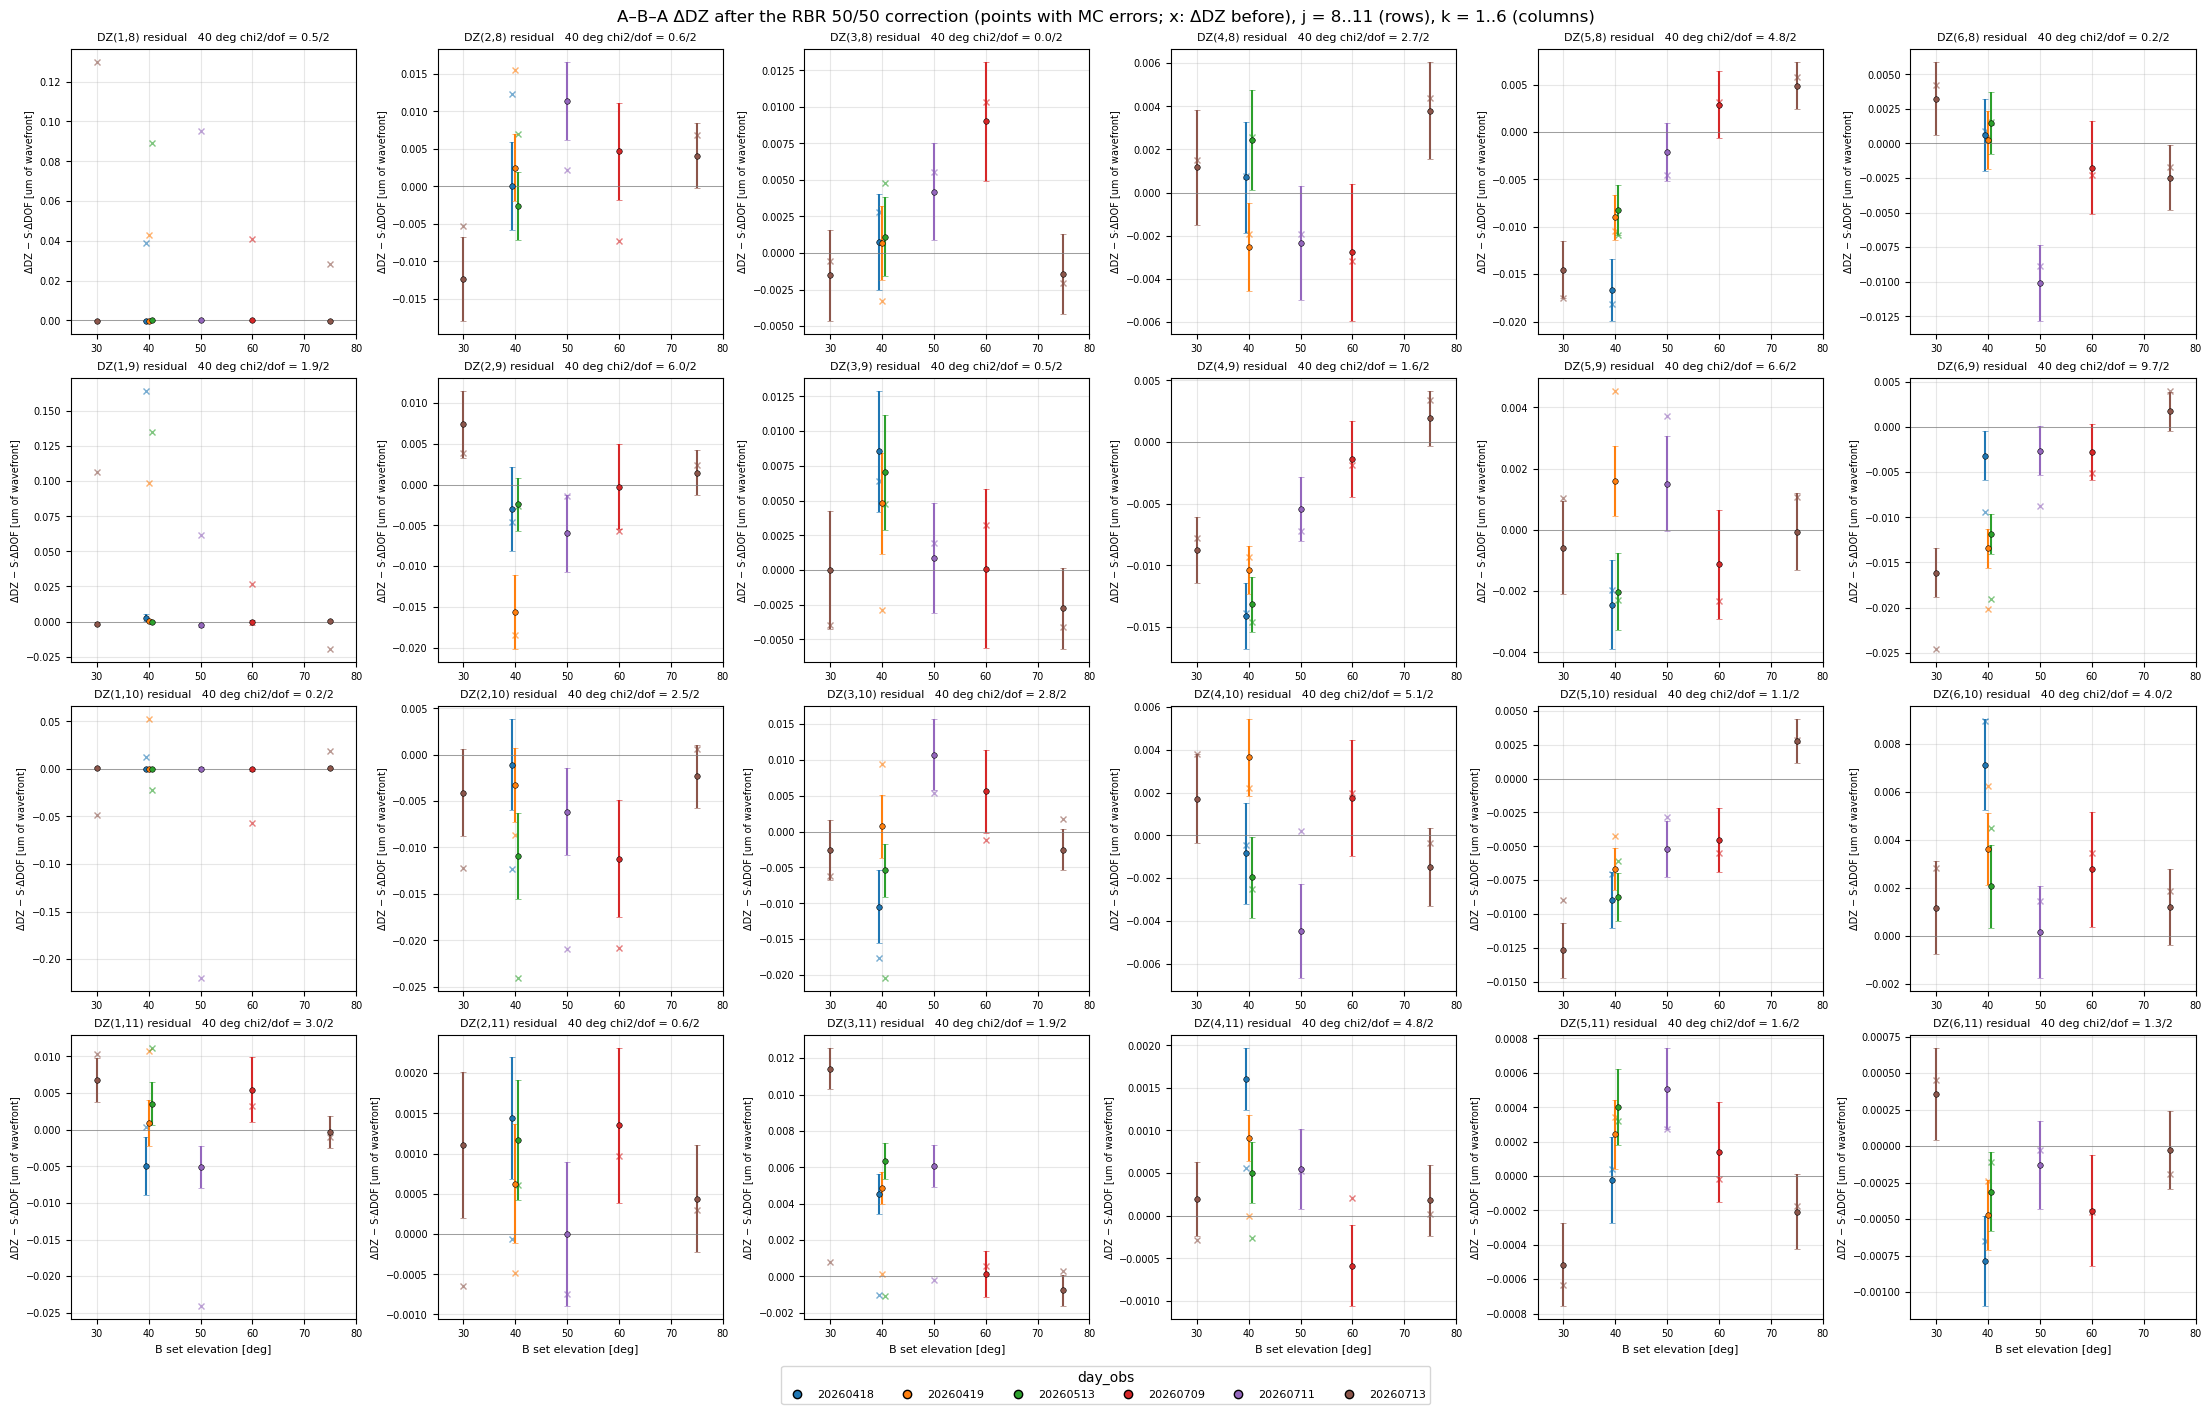

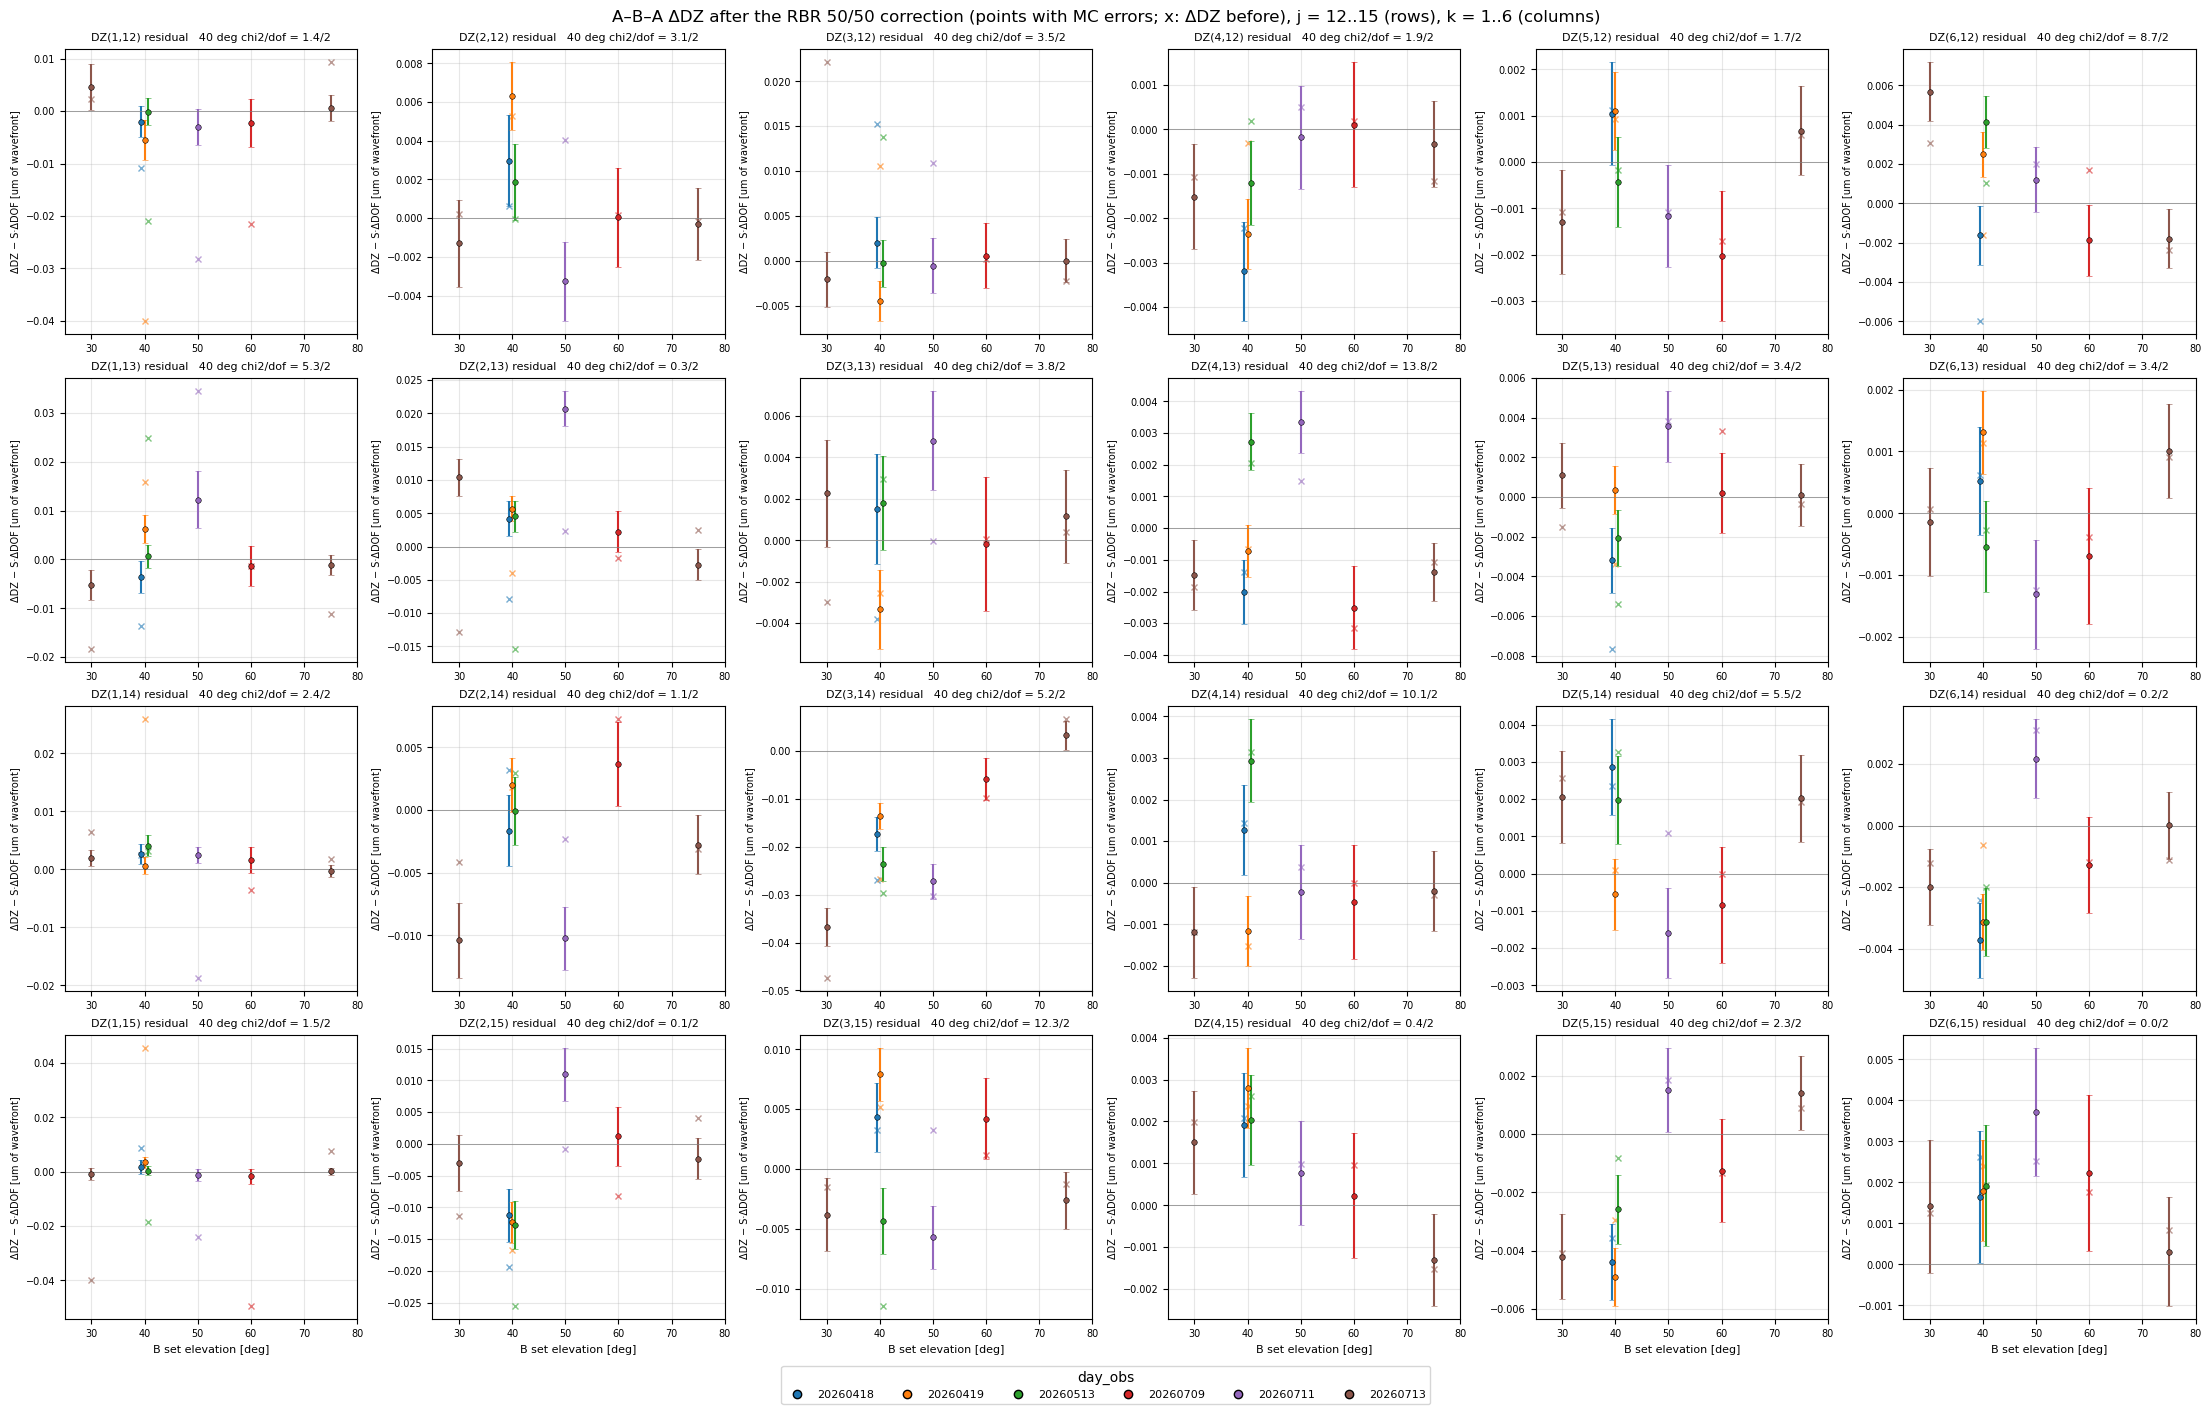

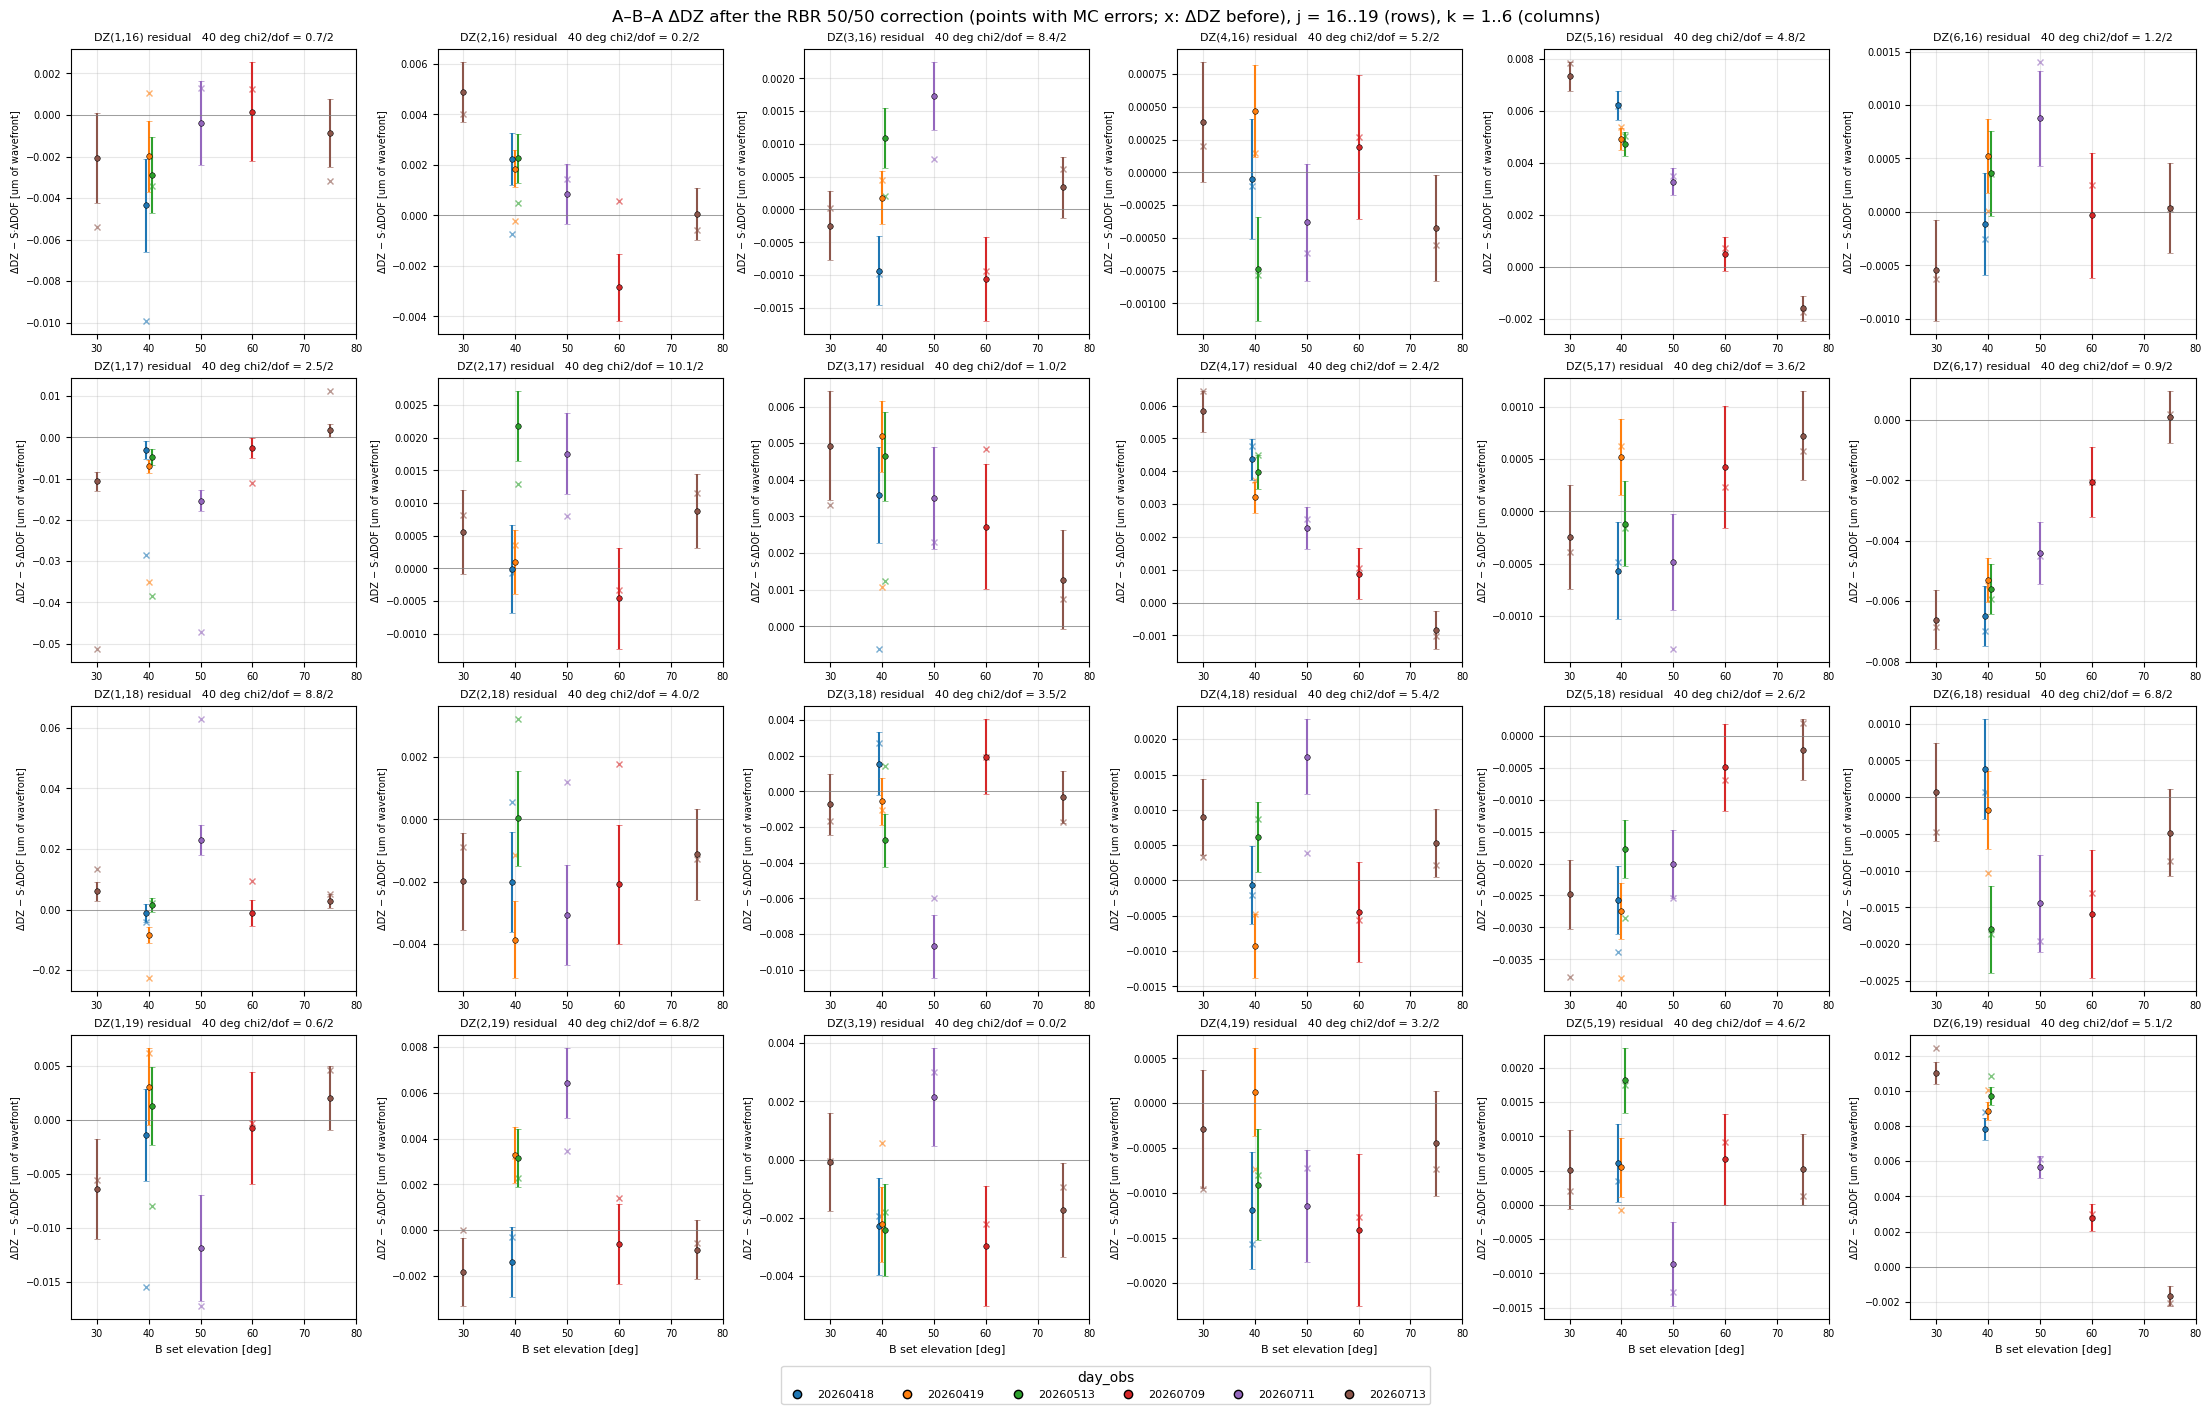

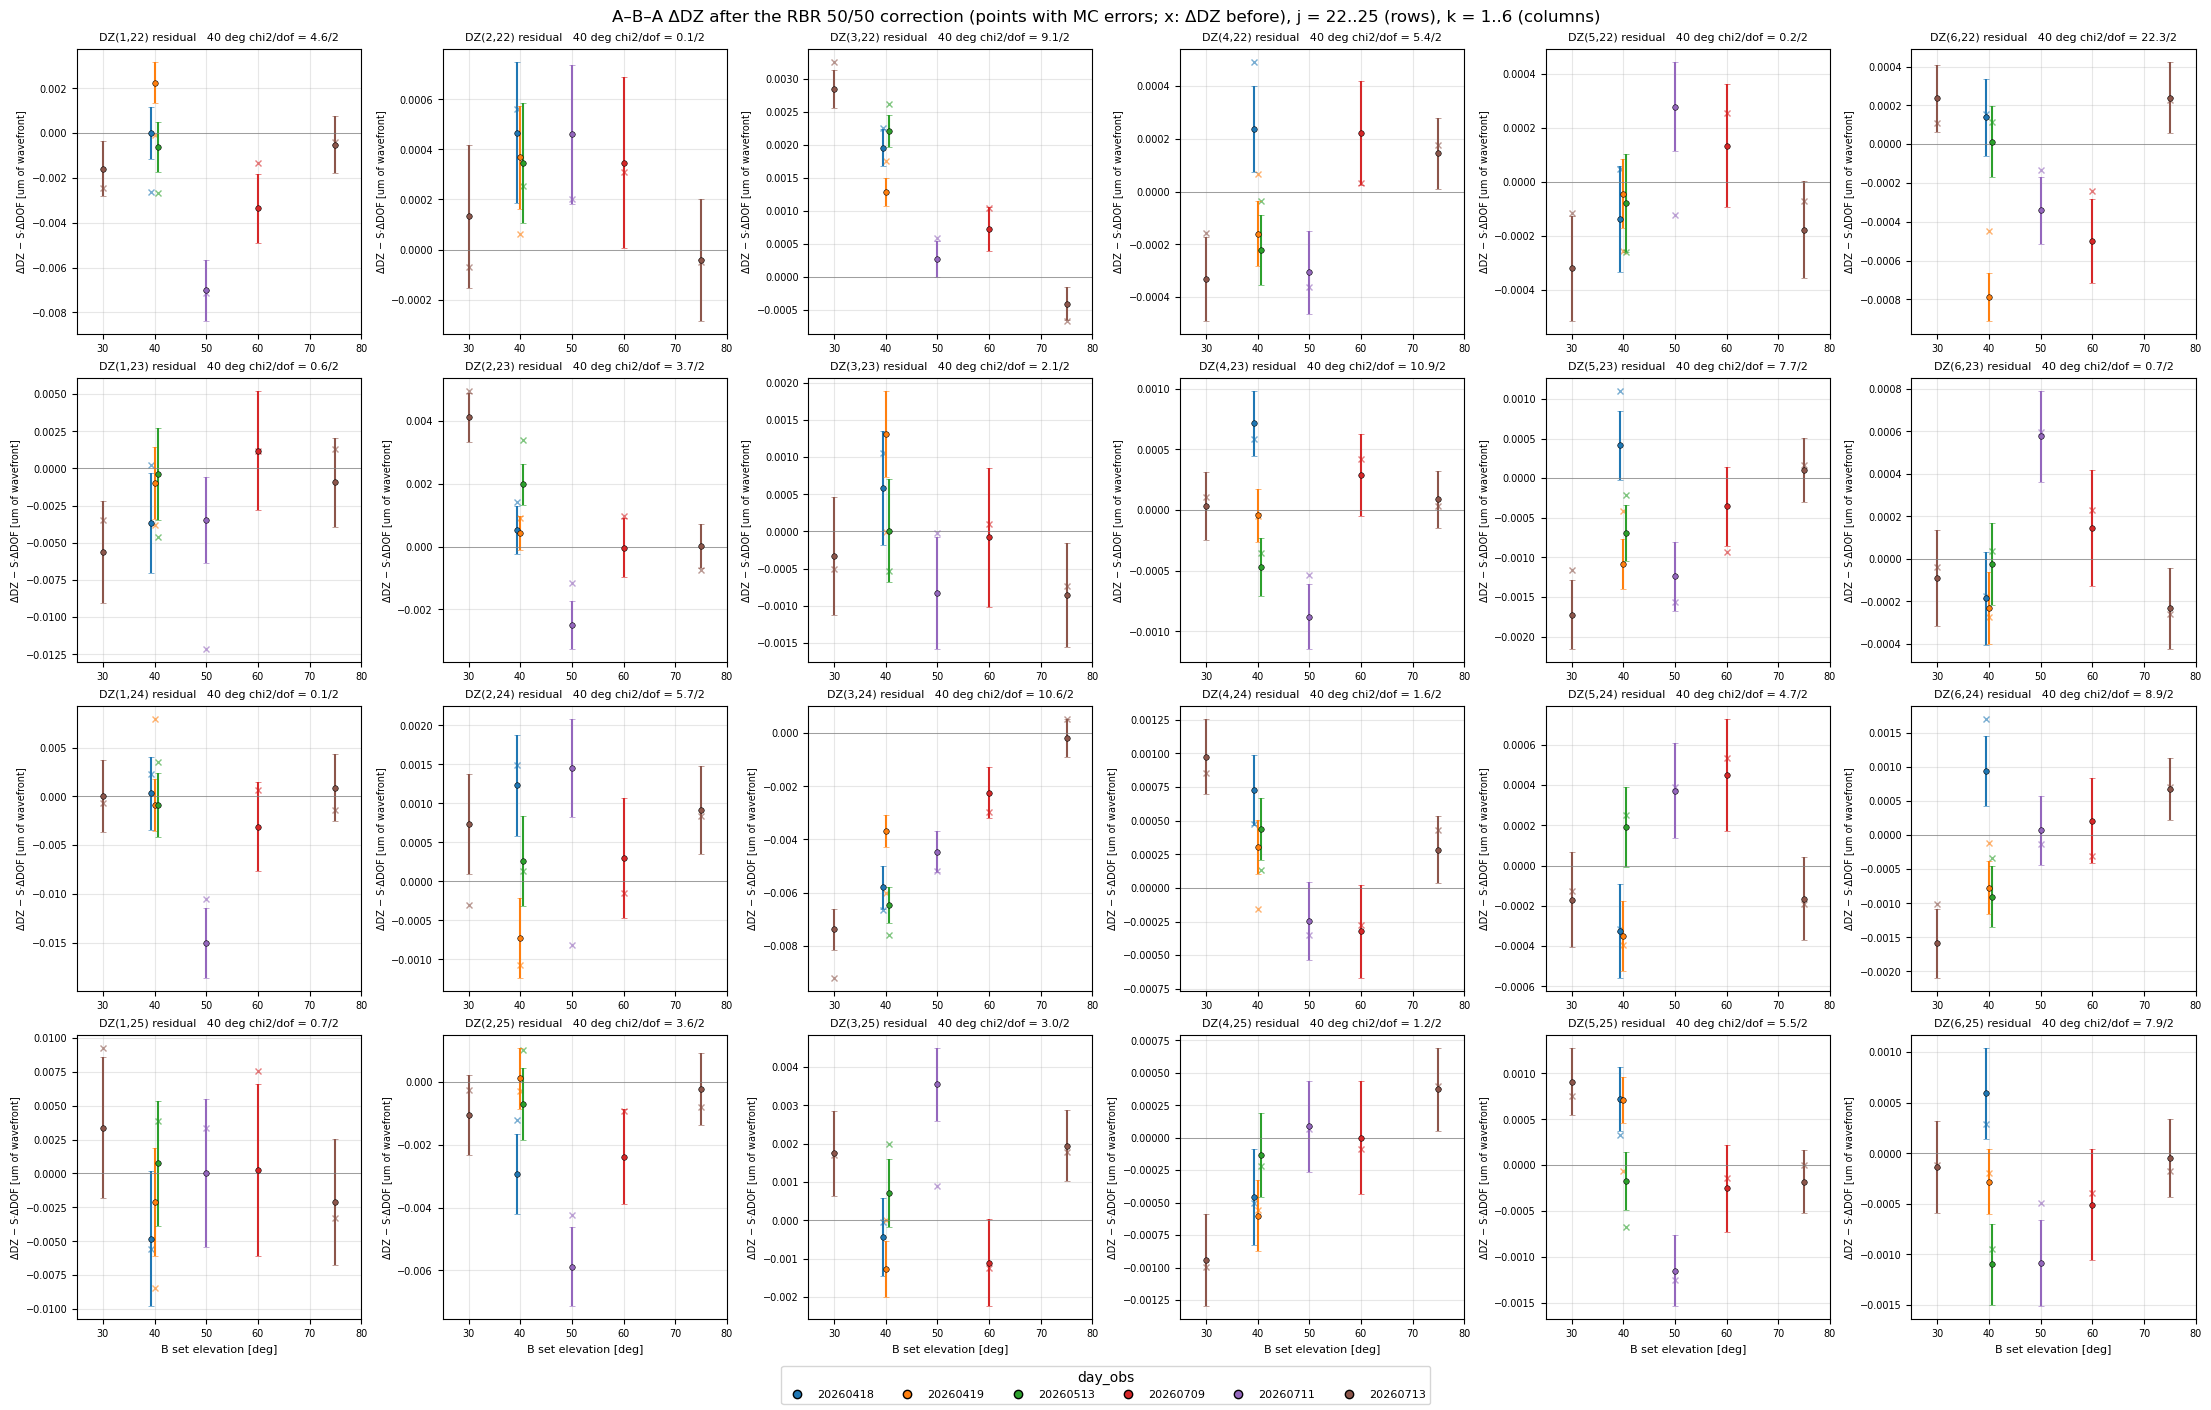

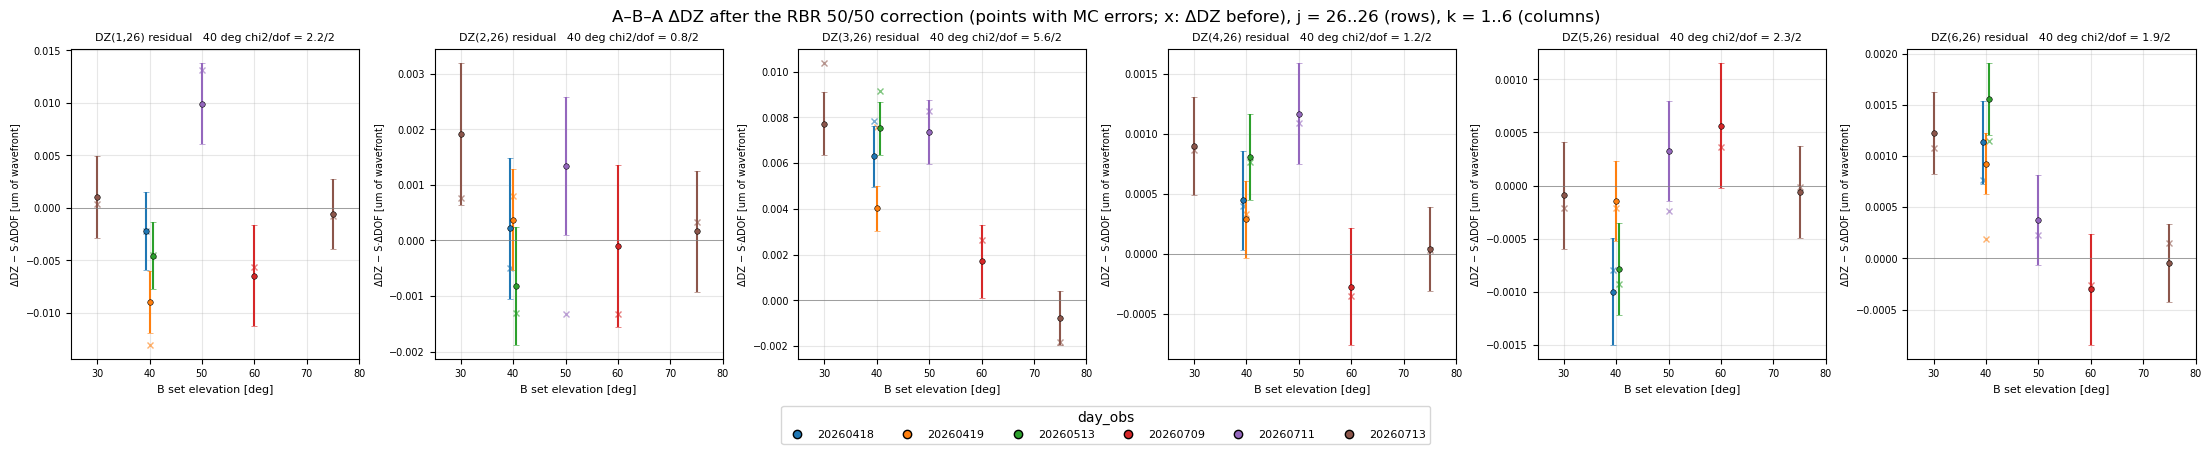

In [14]:
figs_res = []
for p0 in range(0, len(iZs), J_PER_PAGE):
    js = iZs[p0:p0 + J_PER_PAGE]
    fig, axs = plt.subplots(len(js), len(ks), figsize=(22, 3.2 * len(js) + 1.2), layout='constrained',
                            squeeze=False)
    for ri, j in enumerate(js):
        for ci, k in enumerate(ks):
            ix = KJ.index((k, j)); a_ = axs[ri, ci]
            for L in legs:
                a_.plot(L['b_value_deg'] + xoff.get(L['night'], 0.0), res[(L['night'], L['leg'])]['dz'][ix],
                        'x', color=ncol[L['night']], ms=5, alpha=0.6)
            panel(a_, lambda r: r['resid'][ix], lambda r: r['resid_err'][ix], f'DZ({k},{j}) residual',
                  'ΔDZ − S·ΔDOF [um of wavefront]')
            if ri == len(js) - 1:
                a_.set_xlabel('B set elevation [deg]', fontsize=8)
    fig.suptitle(f'A–B–A ΔDZ after the RBR 50/50 correction (points with MC errors; x: ΔDZ before), '
                 f'j = {js[0]}..{js[-1]} (rows), k = 1..6 (columns)')
    legend_fig(fig); figs_res.append(fig); plt.show()

<a id='save'></a>
## Save

In [15]:
if SAVE:
    out = run.path / 'bounce_aba_optical_state.pdf'
    with PdfPages(str(out)) as pdf:
        for f in [fig_focus, fig_rsum] + figs_res + [fig_vg] + figs_dz + figs_v + figs_dof + [fig_split, fig_cmp]:
            pdf.savefig(f, bbox_inches='tight')
    long = []
    for L in legs:
        r = res[(L['night'], L['leg'])]
        base = {'night': L['night'], 'leg': L['leg'], 'b_value_deg': L['b_value_deg']}
        long += [{**base, 'kind': 'DZ', 'name': f'DZ({k},{j})', 'unit': 'um', 'delta': r['dz'][a],
                  'err': r['dz_err'][a]} for a, (k, j) in enumerate(KJ)]
        long += [{**base, 'kind': 'vmode', 'name': f'v{m + 1}', 'unit': 'dimensionless',
                  'delta': r['v'][m], 'err': r['v_err'][m]} for m in range(50)]
        long += [{**base, 'kind': 'DOF', 'name': LABELS_50DOF[i], 'unit': DOF_UNITS_50[i],
                  'delta': r['dof'][i], 'err': r['dof_err'][i]} for i in range(50)]
    pd.DataFrame(long).to_csv(run.path / 'bounce_aba_optical_state.csv', index=False)
    nmod.to_csv(run.path / 'bounce_aba_noise_model.csv', index=False)
    key.to_csv(run.path / 'bounce_aba_v1_hexapod_split.csv', index=False)
    dz14.to_csv(run.path / 'bounce_aba_dz14_split.csv', index=False)
    pd.DataFrame([{'night': L['night'], 'leg': L['leg'], 'name': f'DZ({k},{j})', 'unit': 'um',
                   'delta': res[(L['night'], L['leg'])]['dz'][a],
                   'fit': res[(L['night'], L['leg'])]['fit'][a],
                   'resid': res[(L['night'], L['leg'])]['resid'][a],
                   'resid_err': res[(L['night'], L['leg'])]['resid_err'][a]}
                  for L in legs for a, (k, j) in enumerate(KJ)]).to_csv(
        run.path / 'bounce_aba_dz_residual.csv', index=False)
    np.savez(run.path / 'bounce_aba_noise_model.npz', SIG_W=SIG_W, SR14=SR14, ALPHA14=ALPHA14,
             kj=np.array(KJ))
    print(f'wrote {out}: {len(figs_dz)} DZ, {len(figs_v)} v-mode, {len(figs_dof)} DOF pages, '
          'after the DZ(1,4) focus page, residual summary and residual pages; '
          'hexapod-split and v1 comparison pages last')

wrote /sdf/group/rubin/u/roodman/LSST/rubin-work/studies/aos/bounce/20261104_aba_dz_residual/bounce_aba_optical_state.pdf: 6 DZ, 3 v-mode, 5 DOF pages, after the DZ(1,4) focus page, residual summary and residual pages; hexapod-split and v1 comparison pages last
